# IMPORATION DES BIBLIOTHEQUES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import plotly.express as px
import plotly.figure_factory as ff
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
import pyfixest as pf
from itertools import combinations
import warnings
warnings.filterwarnings("ignore", message=".*singleton fixed effect.*")

In [2]:
# =====================================================================
#  STYLE COMMUN
# =====================================================================
COULEURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
            "#e87ba4", "#008300", "#6250d6", "#e34948"]       # 8 couleurs maximum
BLEU_SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
TEXTE, TEXTE2, GRILLE = "#0b0b0b", "#52514e", "#e6e5e1"

pio.templates["memoire"] = go.layout.Template(layout=dict(
    font=dict(family="Arial, sans-serif", size=13, color=TEXTE),
    paper_bgcolor="white", plot_bgcolor="white", colorway=COULEURS,
    separators=", ",
    title=dict(x=0, xanchor="left", font=dict(size=16)),
    xaxis=dict(showgrid=False, zeroline=False, linecolor=TEXTE2, ticks="outside",
               tickcolor=TEXTE2, title=dict(font=dict(size=12, color=TEXTE2))),
    yaxis=dict(gridcolor=GRILLE, zeroline=False, showline=False,
               title=dict(font=dict(size=12, color=TEXTE2))),
    legend=dict(orientation="h", x=0, y=1.08, title=None, font=dict(size=12)),
    margin=dict(l=110, r=40, t=90, b=110),
    width=900, height=500, bargap=0.35,
))
pio.templates.default = "memoire"


# =====================================================================
#  OUTILS INTERNES
# =====================================================================
def _liste(v, defaut=None):
    """'a' -> ['a'] ; None -> defaut ; liste -> liste."""
    if v is None:
        return defaut
    return [v] if isinstance(v, str) else list(v)

def _a_plat(df):
    """Accepte un DataFrame/Series, avec ou sans index nommé (ex. par_sem)."""
    if isinstance(df, pd.Series):
        df = df.to_frame()
    return df.reset_index() if any(n is not None for n in df.index.names) else df.copy()

def _verifier_couleurs(n):
    if n > len(COULEURS):
        raise ValueError(f"{n} séries sur un même graphique : maximum {len(COULEURS)}. "
                         "Réduisez la liste, ou utilisez petits_multiples().")

def finir(fig, titre, source="Spotify Charts ; calculs de l'auteur", note=None):
    fig.update_layout(title_text=titre)
    texte = f"Source : {source}." + (f" {note}" if note else "")
    fig.add_annotation(text=texte, xref="paper", yref="paper", x=0, y=0, yshift=-78,
                       showarrow=False, xanchor="left", yanchor="top",
                       font=dict(size=11, color=TEXTE2))
    return fig


# =====================================================================
#  1. PETITS GRAPHIQUES (un panneau par pays, mêmes échelles)
# =====================================================================
def petits_multiples(df, colonnes, pays=None, x="semaine", pays_col="pays", ncols=5,
                     titre="", axe="", noms=None, ymin=0, show=True, **kw):
    d = _a_plat(df)
    colonnes = _liste(colonnes)
    pays = _liste(pays, list(d[pays_col].unique()))
    noms = noms or {}
    _verifier_couleurs(len(colonnes))
    d = d[d[pays_col].isin(pays)].sort_values(x)
    lignes = -(-len(pays) // ncols)
    fig = make_subplots(rows=lignes, cols=min(ncols, len(pays)), subplot_titles=pays,
                        shared_xaxes=True, shared_yaxes="all",
                        horizontal_spacing=0.03, vertical_spacing=0.12)
    for k, p in enumerate(pays):
        dd = d[d[pays_col] == p]
        for i, c in enumerate(colonnes):
            fig.add_scatter(x=dd[x], y=dd[c], mode="lines", name=noms.get(c, c),
                            line=dict(color=COULEURS[i], width=1.8),
                            showlegend=(k == 0 and len(colonnes) > 1), legendgroup=c,
                            row=k // ncols + 1, col=k % ncols + 1)
    fig.update_annotations(font=dict(size=12, color=TEXTE))
    fig.update_xaxes(tickangle=0, nticks=3, tickformat="%Y")

    if ymin is not None:
        fig.update_yaxes(rangemode="tozero")
    haut = 220 * lignes + 150
    fig.update_layout(height=haut, margin=dict(l=70, r=30, t=110, b=110))
    if len(colonnes) > 1:       # légende en haut à droite, au-dessus des titres de panneaux
        fig.update_layout(legend=dict(orientation="h", x=1, xanchor="right",
                                      y=1 + 75 / (haut - 220), yanchor="bottom"))
    fig = finir(fig, (titre + (f"<br><sup>{axe}</sup>" if axe else "")), **kw)
    if show:
        fig.show()
    return fig


# =====================================================================
#  2. BARRES : une ou plusieurs colonnes, un ou plusieurs pays
# =====================================================================
def barres(df, colonnes, pays=None, pays_col="pays", titre="", axe="", noms=None,
           trier_par=None, format_val=",.0f", valeurs=None, empiler=False, total=None,
           show=True, **kw):
    """df : tableau avec un pays par ligne (dans la colonne pays ou dans l'index).
    colonnes   : colonne(s) à représenter.
    empiler    : False = barres côte à côte ; True = barres empilées (parties d'un total).
    total      : (avec empiler) colonne du total, affichée au bout de chaque barre.
    trier_par  : colonne servant au tri (par défaut la première ; peut être le total).
    valeurs    : afficher les chiffres (par défaut : oui si une seule colonne ou empilé)."""
    if isinstance(df, pd.Series):
        df = df.to_frame()
    d = df.set_index(pays_col) if pays_col in df.columns else df.copy()
    colonnes = _liste(colonnes)
    noms = noms or {}
    _verifier_couleurs(len(colonnes))
    if pays is not None:
        d = d.loc[_liste(pays)]
    d = d.sort_values(trier_par or (total if (empiler and total) else colonnes[0]))
    valeurs = (len(colonnes) == 1 or empiler) if valeurs is None else valeurs
    fig = go.Figure()
    for i, c in enumerate(colonnes):
        fig.add_bar(y=d.index, x=d[c], orientation="h", name=noms.get(c, c),
                    marker=dict(color=COULEURS[i],
                                line=dict(color="white", width=2 if empiler else 0)),
                    text=d[c] if valeurs else None,
                    texttemplate="%{text:" + format_val + "}" if valeurs else None,
                    textposition="inside" if empiler else "outside",
                    insidetextanchor="middle",
                    textfont=dict(color="white", size=12) if empiler else None,
                    cliponaxis=False)
    if empiler and total:
        fig.add_scatter(x=d[total], y=d.index, mode="text", text=d[total],
                        texttemplate="  %{text:" + format_val + "}", textposition="middle right",
                        textfont=dict(color=TEXTE, size=13), showlegend=False,
                        hoverinfo="skip", cliponaxis=False)
        fig.update_xaxes(range=[0, d[total].max() * 1.12])
    fig.update_xaxes(title_text=axe, showgrid=True, gridcolor=GRILLE, ticks="")
    fig.update_yaxes(showgrid=False, ticks="")
    fig.update_layout(barmode="stack" if empiler else "group", showlegend=len(colonnes) > 1,
                      legend=dict(orientation="h", x=0, y=1.14, traceorder="normal"),
                      height=max(320, 190 + 26 * len(d) * (1 if empiler else len(colonnes))))
    fig = finir(fig, titre, **kw)
    if show:
        fig.show()
    return fig

In [3]:
# Importation de la base données

base=pd.read_csv("C:/Users/HP/Desktop/ENSAE/2A/PROJET PYTHON/base_complete.csv")   
#base=pd.read_csv("base_complete.csv")

In [4]:
"""noms_pays = {
    "ar": "Argentine",
    "de": "Allemagne",
    "eg": "Égypte",
    "fr": "France",
    "gr": "Grèce",
    "jp": "Japon",
    "kr": "Corée du Sud",
    "ma": "Maroc",
    "pt": "Portugal",
    "th": "Thaïlande",
}

base["pays"] = base["pays"].map(noms_pays)"""

'noms_pays = {\n    "ar": "Argentine",\n    "de": "Allemagne",\n    "eg": "Égypte",\n    "fr": "France",\n    "gr": "Grèce",\n    "jp": "Japon",\n    "kr": "Corée du Sud",\n    "ma": "Maroc",\n    "pt": "Portugal",\n    "th": "Thaïlande",\n}\n\nbase["pays"] = base["pays"].map(noms_pays)'

In [5]:
base.shape

(419891, 13)

In [6]:
base.columns

Index(['rank', 'uri', 'artist_names', 'track_name', 'source', 'peak_rank',
       'previous_rank', 'weeks_on_chart', 'streams', 'pays', 'semaine',
       'nationalite', 'langue'],
      dtype='object')

In [7]:
base.isna().sum()

rank               0
uri                0
artist_names       0
track_name         0
source             0
peak_rank          0
previous_rank      0
weeks_on_chart     0
streams            0
pays               0
semaine            0
nationalite       26
langue             3
dtype: int64

In [8]:
base.describe()

,rank,peak_rank,previous_rank,weeks_on_chart,streams
count,419891.000000,419891.000000,419891.000000,419891.000000,4.198910e+05
mean,100.500325,37.583375,83.828894,51.992319,3.805275e+05
std,57.734236,44.315334,59.398245,65.187909,4.537730e+05
min,1.000000,1.000000,-1.000000,1.000000,1.207600e+04
25%,51.000000,5.000000,31.000000,9.000000,8.591000e+04
50%,100.000000,18.000000,81.000000,28.000000,2.417310e+05
75%,151.000000,57.000000,134.000000,68.000000,5.119440e+05
max,200.000000,200.000000,200.000000,506.000000,1.229475e+07


In [9]:
base.describe(include=["object"])

,uri,artist_names,track_name,source,pays,semaine,nationalite,langue
count,419891,419891,419891,419891,419891,419891,419865,419888
unique,23000,9843,19300,3617,10,210,975,125
top,spotify:track:6dOtVTDdiauQNBQEDOtlAB,Lim Young Woong,BIRDS OF A FEATHER,Universal Music LLC,Argentine,2022-10-06,US,eng
freq,845,3604,845,13468,42000,2000,50939,90570


# INTRODUCTION

# 1. REVUE DE LITTERATURE

# 2. DONNEES, CONSTRUCTION ET ENRICHISSEMENT DE LA BASE

## 2.1 SOURCE, COLLECTE ET CONSTITUTION DE LA BASE DE DONNEES

La présente étude repose sur les classements hebdomadaires Spotify Top 200 de dix pays : *l'Argentine, l'Allemagne, l'Égypte, la France, la Grèce, le Japon, la Corée du Sud, le Maroc, le Portugal et la Thaïlande*. Le choix de ces pays répond à un objectif de diversité géographique et linguistique. L'échantillon comprend aussi bien des pays dont les langues sont parlées dans plusieurs régions du monde, comme la France, le Portugal et l'Argentine, que des pays dont les langues sont davantage circonscrites à un espace géographique particulier, comme le Japon, la Thaïlande et la Grèce. Cette diversité permet d'étudier les différences de circulation des titres musicaux selon les contextes linguistiques et géographiques.

La période d'étude couvre **210** semaines, de la semaine du *06/10/2022* à celle du *08/10/2026*. Chaque observation correspond à un titre présent dans le classement d'un pays au cours d'une semaine donnée. Les informations disponibles comprennent notamment le rang occupé par le titre et son nombre d'écoutes (streams).

#### Collecte

Les données ont été recueillies directement sur la plateforme Spotify Charts. Les conditions d'utilisation de Spotify ne permettant pas de procéder à une extraction automatisée des classements par scraping, la collecte a été réalisée par téléchargement individuel des fichiers hebdomadaires. Pour chacun des dix pays, les classements ont ainsi été téléchargés sur les 210 semaines de la période étudiée, conduisant à la constitution de 2 100 fichiers.

Ces fichiers ont ensuite été regroupés dans une base de données unique, dénommée base_complete, afin de disposer d'un ensemble de données exploitable pour les analyses statistiques et économétriques. Chaque observation a été associée à son pays et à sa semaine de référence.

#### Vérification

Une première vérification a porté sur la cohérence des fichiers téléchargés. Les noms des variables étant identiques dans l'ensemble des fichiers, aucune harmonisation supplémentaire n'a été nécessaire. De même, aucun doublon n'a été relevé après leur regroupement.

Compte tenu des dix pays et des 210 semaines retenus, le volume théorique de la base était 420 000 observations. Toutefois, la base constituée comporte 419 891 lignes. L'examen de cet écart a permis de constater que certaines observations étaient absentes des fichiers disponibles, en raison notamment du retrait de certains artistes des classements Spotify. 

## 2.2. ENRICHISSEMENT DES DONNEES ET CONSTRUCTION DES VARIABLES

Les classements Spotify ne fournissant pas d'informations sur la **nationalité des artistes** ni sur la **langue des chansons**, un travail complémentaire d'enrichissement a été nécessaire. Ces deux dimensions étant au cœur de la problématique étudiée, leur identification constituait une étape essentielle de la préparation des données.

La première source mobilisée a été **<u>MusicBrainz</u>**, une base de données musicale ouverte qui rassemble des informations sur les artistes, les groupes et les œuvres musicales. Un programme développé en Python a permis d'effectuer des recherches automatisées dans cette base afin de récupérer les informations disponibles sur les artistes et les titres présents dans notre échantillon.

L'enrichissement a été réalisé à partir des valeurs uniques plutôt que sur l'ensemble des observations, afin d'éviter de répéter les mêmes recherches pour un artiste ou un titre apparaissant plusieurs fois dans les classements. Ainsi, la recherche des langues a porté sur **20 392 couples distincts (artiste, titre)**, tandis que celle des nationalités a concerné **9 843 artistes distincts**.

Les nationalités sont codées selon la norme ISO 3166-1 alpha-2, qui associe à chaque pays un code de deux lettres. Lorsqu'un artiste ou un groupe est associé à plusieurs nationalités, les différents codes sont conservés et séparés par un point-virgule (par exemple FR;MA).

Les langues sont quant à elles codées selon la norme ISO 639-3, qui attribue un code de trois lettres à chaque langue. On retrouve ainsi les codes eng pour l'anglais, fra pour le français ou encore kor pour le coréen. Lorsqu'une chanson comporte plusieurs langues, les différents codes sont conservés et séparés par une virgule.

Toutefois, MusicBrainz ne renseigne pas systématiquement toutes les informations recherchées : à l'issue de cette première étape, la langue restait manquante pour 1 453 titres (7,1 %) et la nationalité pour 483 artistes (4,9 %). Pour compléter ces informations, nous avons eu recours à *Perplexity*, un outil d'intelligence artificielle capable d'effectuer des recherches sur Internet à partir de différentes sources. Les informations obtenues ont ensuite été examinées à l'aide de *Claude*, utilisé comme outil complémentaire de vérification, notamment pour les informations relatives aux artistes et à leur environnement musical.

Cette démarche a permis de compléter la quasi-totalité des informations initialement manquantes : il ne reste que 2 langues et 6 nationalités non renseignées. Les résultats ont ensuite été intégrés dans base_complete, à travers deux nouvelles colonnes : la nationalité des artistes et la langue des chansons.

## 2.3. CONTROLE DE LA QUALITE DE L'ENRICHISSEMENT

Compte tenu de l'importance des variables de nationalité et de langue dans cette étude, plusieurs vérifications ont été effectuées afin d'évaluer la cohérence des informations ajoutées et de limiter les erreurs de classification.

**Vérification des valeurs** 

Les informations recueillies auprès de Perplexity ont été examinées par Claude, utilisé comme outil de vérification.

Une attention particulière a également été accordée aux valeurs présentant des caractéristiques inhabituelles : langues rarement rencontrées dans l'échantillon, nationalités semblant incompatibles avec les autres informations disponibles ou codes linguistiques atypiques. Ces cas ont été vérifiés individuellement afin de distinguer les situations réelles des erreurs d'attribution.

**Traçabilité** 

Afin de garantir la transparence du processus d'enrichissement, les informations ajoutées en dehors de MusicBrainz ont été conservées dans deux fichiers distincts, `ajouts_langues.csv` (1 451 titres) et `ajouts_nationalites.csv` (477 artistes). Chaque ligne indique l'origine de la valeur ainsi que sa source ou son fondement. 

**Complétude finale** 

À l'issue du processus, 2 langues (0,01 % des 20 392 titres) et 6 nationalités (0,06 % des 9 843 artistes) restent non renseignées. Elles sont laissées vides plutôt que remplacées par une modalité « indéterminé », et sont donc traitées comme des valeurs non nationales et non locales dans la construction des variables. Elles représentent une part négligeable de la base.

# 3. ANALYSE DESCRIPTIVE DES CLASSEMENTS

## 3.1. VOLUME ET DYNAMIQUE DES ECOUTES

On regarde comment le total des écoutes du Top 200 change dans chaque pays : la tendance (3.1.1), les saisons (3.1.2) et les semaines exceptionnelles (3.1.3).

### 3.1.1 Évolution du total des streams du Top 200

Pour chaque pays et chaque semaine, on additionne les écoutes (streams) des 200 chansons du classement. Puis on trace une courbe par pays.

In [10]:

totaux=base.groupby(["pays","semaine"])["streams"].sum().reset_index()


print(totaux.shape, totaux["streams"].min())

(2100, 3) 5135953


In [11]:
pays_liste = totaux["pays"].unique()  

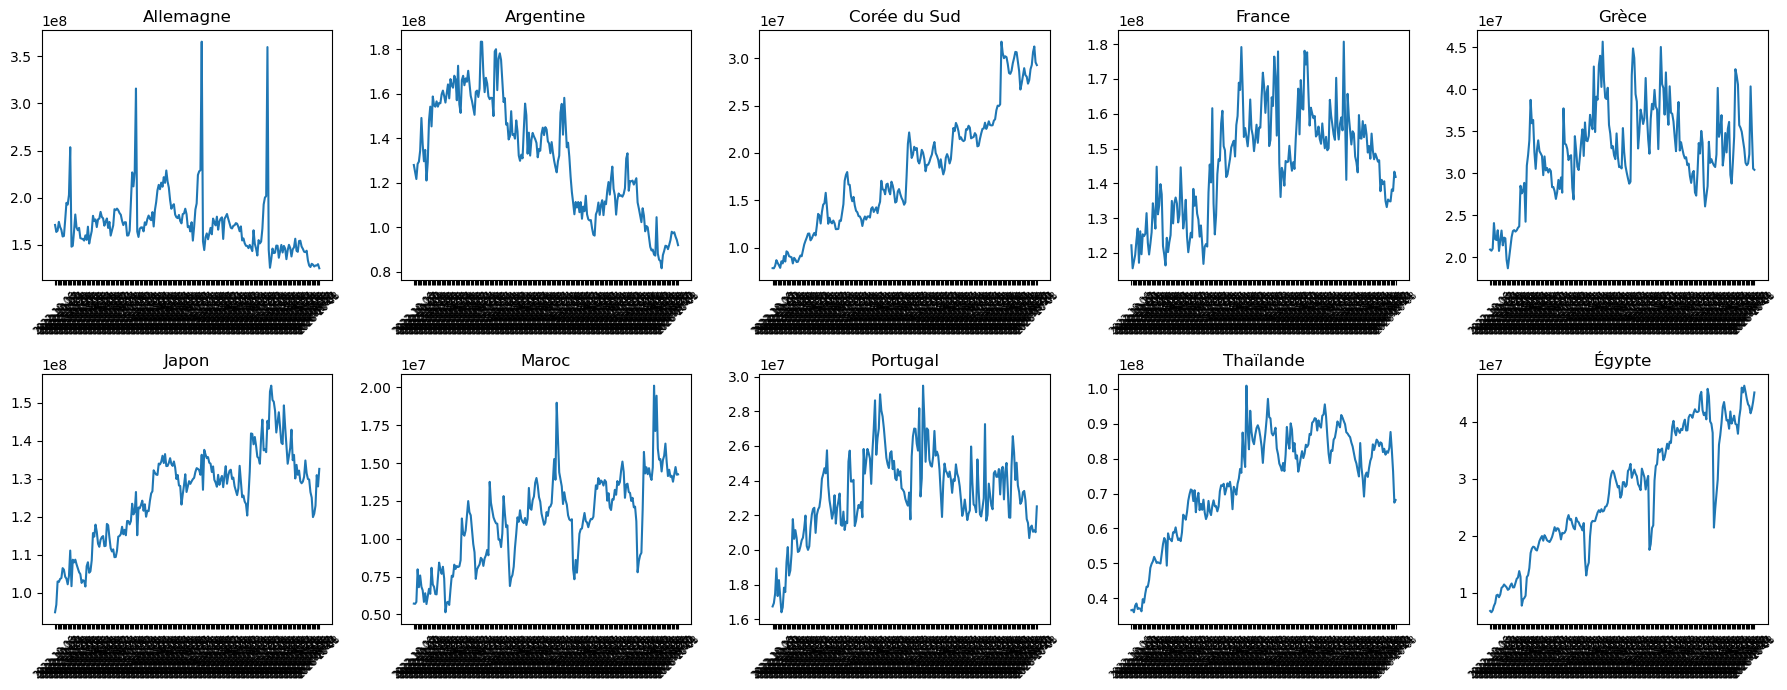

In [12]:
plt.figure(figsize=(18, 7))
for i in range(10):
    p = pays_liste[i]
    un_pays = totaux[totaux["pays"] == p]
    plt.subplot(2, 5, i + 1)
    plt.plot(un_pays["semaine"], un_pays["streams"])
    plt.title(p)
    plt.xticks(rotation=45, fontsize=7)
plt.tight_layout()
plt.show()

**Interprétations**

- **Égypte et Corée du Sud** : le total monte tout le temps. En Égypte, il y a aussi une forte baisse <u>chaque printemps (mars-avril)</u>.
- **Thaïlande et Japon** : le total monte jusqu'en 2024, puis reste à peu près stable ou baisse un peu.
- **Maroc** : hausse en 2023, puis le total devient très irrégulier, avec de gros pics fin 2024 et mi-2026.
- **France, Portugal, Grèce** : hausse jusqu'à un niveau haut en 2024, puis baisse. Cela commence dès 2024 au Portugal et mi-2025 en France. En Grèce, le total varie beaucoup en 2025-2026.
- **Argentine** : niveau haut en 2023, puis baisse depuis début 2024, avec une chute nette début 2025.
- **Allemagne** : niveau plutôt plat, qui baisse en 2025-2026, avec un très gros <u>pic chaque fin décembre</u>.

Les courbes montrent le sens de l'évolution, hausse ou baisse, mais pas de combien le total a changé. Chaque case a sa propre échelle : on ne peut pas comparer les pays à l'œil.

Pour mesurer la variation, on compare la moyenne des 4 premières semaines à celle des 4 dernières, pour chaque pays. Une moyenne sur 4 semaines évite qu'une semaine exceptionnelle change tout le résultat.

In [13]:
debut = totaux[totaux["semaine"] <= "2022-10-27"].groupby("pays")["streams"].mean()
fin = totaux[totaux["semaine"] >= "2026-09-17"].groupby("pays")["streams"].mean()
variation = (fin - debut) / debut * 100

resultat = pd.DataFrame({"debut": debut, "fin": fin, "variation_%": variation.round(1)})
print(resultat)

                     debut           fin  variation_%
pays                                                 
Allemagne     1.685546e+08  1.277431e+08        -24.2
Argentine     1.257255e+08  9.492123e+07        -24.5
Corée du Sud  8.118571e+06  3.017595e+07        271.7
France        1.186938e+08  1.403080e+08         18.2
Grèce         2.168234e+07  3.408876e+07         57.2
Japon         9.940037e+07  1.286121e+08         29.4
Maroc         6.299530e+06  1.437164e+07        128.1
Portugal      1.752690e+07  2.143008e+07         22.3
Thaïlande     3.673130e+07  7.358771e+07        100.3
Égypte        7.036186e+06  4.307063e+07        512.1


Les 4 premières semaines vont du 6 au 27 octobre 2022 et les 4 dernières du 17 septembre au 8 octobre 2026 : c'est à peu près la même période de l'année, donc la saison change peu la comparaison.

- 8 pays sur 10 sont en hausse. Les plus fortes : Égypte (+512 %), Corée du Sud (+272 %), Maroc (+128 %) et Thaïlande (+100 %). Les plus faibles : Grèce (+57 %), Japon (+29 %), Portugal (+22 %), France (+18 %).
- 2 pays sont en baisse : Argentine (−24,5 %) et Allemagne (−24,2 %).
- Pour l'Allemagne, les pics de Noël cachaient la baisse sur les courbes. La France, le Portugal et la Grèce baissent depuis 2024 ou 2025, mais restent au-dessus de leur niveau de 2022.

### 3.1.2 Saisons

On regarde si certains mois ont plus d'écoutes que d'autres. Par exemple, est-ce que décembre est toujours un mois fort ?

On ne peut pas comparer les mois directement, parce que le total change d'une année à l'autre. Alors on compare chaque semaine à la moyenne de son année.

Les étapes :

1. On prend le total des écoutes de chaque semaine, pour chaque pays (vu en 3.1.1).
2. On garde seulement 2023, 2024 et 2025, car ce sont les années complètes (52 semaines). 2022 n'a que 13 semaines (octobre à décembre) et 2026 que 41 semaines (jusqu'en octobre) : leur moyenne serait faussée.
3. Pour chaque pays et chaque année, on calcule la moyenne des écoutes par semaine.
4. Pour chaque semaine, on calcule le ratio : les écoutes de la semaine divisées par la moyenne de son année. Un ratio de 1 veut dire que la semaine est dans la moyenne. Un ratio de 1,2 veut dire 20 % au-dessus. Un ratio de 0,8 veut dire 20 % en dessous.
5. Pour chaque pays et chaque mois, on fait la moyenne des ratios des semaines de ce mois, sur les trois années. Pour décembre, c'est la moyenne de 12 semaines. On a 12 nombres par pays, donc 120 en tout.
6. On trace ces 12 nombres pour chaque pays, avec un trait en pointillé à 1. On les met aussi dans un tableau.

Si le ratio d'un mois est au-dessus de 1, ce mois est plus fort que la moyenne de l'année. Par exemple si un Pays a 1,50 en décembre : ses semaines de décembre sont en moyenne 50 % au-dessus de la moyenne de l'année.

In [17]:
totaux["semaine"] = pd.to_datetime(totaux["semaine"])

totaux["annee"] = totaux["semaine"].dt.year
totaux["mois"] = totaux["semaine"].dt.month
print(totaux.groupby("annee")["semaine"].nunique())

annee
2022    13
2023    52
2024    52
2025    52
2026    41
Name: semaine, dtype: int64


In [18]:
complets = totaux[totaux["annee"].isin([2023, 2024, 2025])].copy()

moyennes = complets.groupby(["pays", "annee"])["streams"].mean().reset_index()
moyennes = moyennes.rename(columns={"streams": "moyenne_annee"})
complets = complets.merge(moyennes, on=["pays", "annee"], how="left")

complets["ratio"] = complets["streams"] / complets["moyenne_annee"]
print(complets.shape, complets["ratio"].mean())

(1560, 7) 1.0


In [19]:
saison = complets.groupby(["pays", "mois"])["ratio"].mean().reset_index()
print(saison.shape)
print(saison.head(12))

(120, 3)
         pays  mois     ratio
0   Allemagne     1  0.898970
1   Allemagne     2  0.937047
2   Allemagne     3  0.946280
3   Allemagne     4  0.975614
4   Allemagne     5  1.062360
5   Allemagne     6  1.051658
6   Allemagne     7  0.998699
7   Allemagne     8  0.942061
8   Allemagne     9  0.962295
9   Allemagne    10  0.921234
10  Allemagne    11  0.942610
11  Allemagne    12  1.392291


On trace le ratio moyen de chaque mois, pour chaque pays. La ligne en pointillé est la moyenne de l'année (ratio = 1) : au-dessus, le mois est plus fort que la moyenne ; en dessous, il est plus faible.

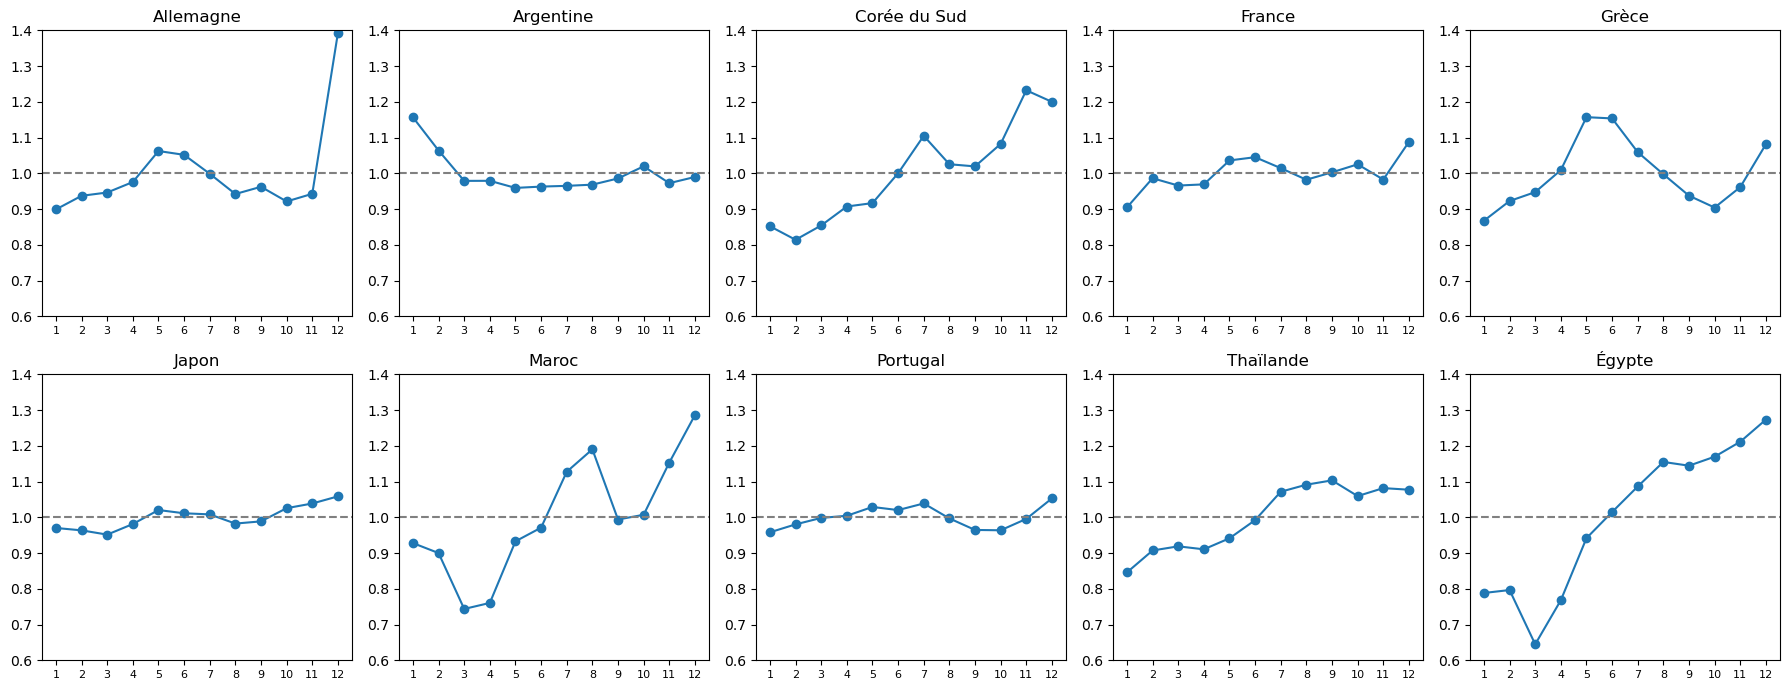

In [20]:
pays_liste = saison["pays"].unique()

plt.figure(figsize=(18, 7))
for i in range(10):
    p = pays_liste[i]
    s = saison[saison["pays"] == p]
    plt.subplot(2, 5, i + 1)
    plt.plot(s["mois"], s["ratio"], marker="o")
    plt.axhline(1, color="gray", linestyle="--")
    plt.title(p)
    plt.ylim(0.6, 1.4)
    plt.xticks(range(1, 13), fontsize=8)
plt.tight_layout()
plt.show()

Les mêmes valeurs en tableau, pour lire les chiffres exacts (un pays par ligne, un mois par colonne).

In [21]:
tableau = saison.pivot(index="pays", columns="mois", values="ratio").round(2)
print(tableau)

mois            1     2     3     4     5     6     7     8     9     10  \
pays                                                                       
Allemagne     0.90  0.94  0.95  0.98  1.06  1.05  1.00  0.94  0.96  0.92   
Argentine     1.16  1.06  0.98  0.98  0.96  0.96  0.96  0.97  0.99  1.02   
Corée du Sud  0.85  0.81  0.85  0.91  0.92  1.00  1.10  1.03  1.02  1.08   
France        0.90  0.99  0.97  0.97  1.04  1.05  1.01  0.98  1.00  1.03   
Grèce         0.87  0.92  0.95  1.01  1.16  1.15  1.06  1.00  0.94  0.90   
Japon         0.97  0.96  0.95  0.98  1.02  1.01  1.01  0.98  0.99  1.03   
Maroc         0.93  0.90  0.74  0.76  0.93  0.97  1.13  1.19  0.99  1.01   
Portugal      0.96  0.98  1.00  1.00  1.03  1.02  1.04  1.00  0.96  0.96   
Thaïlande     0.85  0.91  0.92  0.91  0.94  0.99  1.07  1.09  1.10  1.06   
Égypte        0.79  0.80  0.64  0.77  0.94  1.01  1.09  1.15  1.14  1.17   

mois            11    12  
pays                      
Allemagne     0.94  1.39  
Argent

**Interprétations**

- Décembre est au-dessus de la moyenne dans 9 pays sur 10, surtout en Allemagne (1,39), au Maroc (1,29) et en Égypte (1,27).
- L'Égypte et le Maroc ont un creux en mars-avril (entre 0,64 et 0,77).
- L'Égypte, la Thaïlande et la Corée du Sud sont plus hautes de juillet à septembre (le Maroc de juillet à août). Mais ces pays sont aussi en hausse sur toute la période : cela peut expliquer une partie de l'écart.
- Le Japon et le Portugal sont presque plats : il y a peu de saisons.

### 3.1.3 Semaines exceptionnelles

Sur les courbes de 3.1.1, on voit parfois un pic : le total d'un pays saute d'un coup, puis redescend. On veut savoir quelles semaines sont dans ce cas et ce qui les explique.

C'est utile parce que ces semaines changent le total. Elles peuvent aussi changer la part de musique nationale, par exemple si un seul artiste du pays domine la semaine.

Pour repérer une semaine exceptionnelle, on n'a pas fixé de seuil. On calcule la variation de chaque semaine par rapport à la semaine d'avant, en pourcentage, et on garde les 10 plus grosses hausses. On regarde seulement les hausses.

Les étapes :

1. On calcule la variation de chaque semaine, pays par pays.
2. On affiche les 10 plus grosses hausses.
3. On regarde quels pays reviennent le plus souvent, et on étudie ceux-là.
4. Pour chaque grosse semaine, on affiche les 10 chansons les plus écoutées, pour voir ce qui domine.
5. Si un seul artiste semble dominer, on calcule sa part dans le total de la semaine.

In [22]:
totaux["variation"] = totaux.groupby("pays")["streams"].pct_change()
print(totaux.sort_values("variation", ascending=False).head(10))

           pays    semaine    streams  annee  mois  variation
168   Allemagne 2025-12-25  359730985   2025    12   0.783057
116   Allemagne 2024-12-26  365493279   2024    12   0.595175
1320      Maroc 2023-11-30   13759510   2023    11   0.545373
952       Grèce 2024-11-28   41666440   2024    11   0.437623
64    Allemagne 2023-12-28  315791629   2023    12   0.390333
1263      Maroc 2022-10-27    7975149   2022    10   0.370386
1450      Maroc 2026-05-28   20118337   2026     5   0.367321
1373      Maroc 2024-12-05   18989802   2024    12   0.366298
898       Grèce 2023-11-16   37719631   2023    11   0.362758
2020     Égypte 2025-04-03   29673749   2025     4   0.359023


Dans ces 10 semaines, l'Allemagne revient 3 fois, le Maroc 4 fois, la Grèce 2 fois et l'Égypte 1 fois. Les sauts vont de +36 % à +78 %. On étudie l'Allemagne, le Maroc et la Grèce, qui font 9 des 10 semaines. Pour l'Allemagne, on prend ses trois semaines de fin décembre. Pour le Maroc et la Grèce, on prend leur plus gros saut.

**Allemagne : les chansons les plus écoutées lors des trois semaines de fin décembre** (25 décembre 2025, 26 décembre 2024, 28 décembre 2023)

In [23]:
allemagne = base[base["pays"] == "Allemagne"]
sp = allemagne[allemagne["semaine"] == "2025-12-25"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

                artist_names  \
75592             Brenda Lee   
75593                  Wham!   
75594        Shakin' Stevens   
75595              Chris Rea   
75596           Mariah Carey   
75597          Ariana Grande   
75598          Michael Bublé   
75599            Dean Martin   
75600       Melanie Thornton   
75601  John Lennon, Yoko Ono   

                                              track_name  streams  
75592                  Rockin' Around The Christmas Tree  8890547  
75593                                     Last Christmas  8685284  
75594                           Merry Christmas Everyone  8326328  
75595         Driving Home for Christmas - 2019 Remaster  7716104  
75596                    All I Want for Christmas Is You  7639858  
75597                                      Santa Tell Me  7376407  
75598        It's Beginning to Look a Lot like Christmas  7185796  
75599             Let It Snow! Let It Snow! Let It Snow!  7146099  
75600  Wonderful Dream (Holidays Ar

In [24]:
allemagne = base[base["pays"] == "Allemagne"]
sp = allemagne[allemagne["semaine"] == "2024-12-26"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

          artist_names                                   track_name  streams
65192            Wham!                               Last Christmas  9763935
65193     Mariah Carey              All I Want for Christmas Is You  9753627
65194  Shakin' Stevens                     Merry Christmas Everyone  8387832
65195       Brenda Lee            Rockin' Around The Christmas Tree  7999489
65196      Dean Martin       Let It Snow! Let It Snow! Let It Snow!  7177306
65197   Kelly Clarkson                          Underneath the Tree  7096059
65198   José Feliciano                                Feliz Navidad  7002445
65199              Sia                                      Snowman  6691807
65200    Ariana Grande                                Santa Tell Me  6680076
65201    Michael Bublé  It's Beginning to Look a Lot like Christmas  6671294


In [25]:
allemagne = base[base["pays"] == "Allemagne"]
sp = allemagne[allemagne["semaine"] == "2023-12-28"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

           artist_names                                         track_name  \
54792             Wham!                    Last Christmas - Single Version   
54793      Mariah Carey                    All I Want for Christmas Is You   
54794   Shakin' Stevens                           Merry Christmas Everyone   
54795         Chris Rea         Driving Home for Christmas - 2019 Remaster   
54796       Dean Martin             Let It Snow! Let It Snow! Let It Snow!   
54797               Sia                                            Snowman   
54798  Melanie Thornton  Wonderful Dream (Holidays Are Coming) - Radio ...   
54799    Kelly Clarkson                                Underneath the Tree   
54800     Ariana Grande                                      Santa Tell Me   
54801        Brenda Lee                  Rockin' Around The Christmas Tree   

       streams  
54792  8299586  
54793  8131265  
54794  7270396  
54795  5800495  
54796  5676912  
54797  5604473  
54798  5058276  
54799

Les trois années, les chansons les plus écoutées sont presque toutes des chansons de Noël . Les premières sont presque toujours les mêmes : Wham! (Last Christmas), Mariah Carey (All I Want for Christmas Is You), Shakin' Stevens (Merry Christmas Everyone) et Brenda Lee (Rockin' Around The Christmas Tree). Le pic de fin décembre vient donc de Noël, et il revient chaque année.

**Maroc et Grèce : les chansons les plus écoutées lors de leur plus gros saut** (30 novembre 2023 et 28 novembre 2024)

In [26]:
maroc = base[base["pays"] == "Maroc"]
sp = maroc[maroc["semaine"] == "2023-11-30"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

                artist_names                track_name  streams
305959          ElGrandeToto                  MAGHRIBI   678760
305960   ElGrandeToto, Hamza     DELLALI (feat. Hamza)   655290
305961          ElGrandeToto                   BGHAWNI   491193
305962          ElGrandeToto                    SULTAN   434821
305963          ElGrandeToto                        TP   410971
305964   ElGrandeToto, Morad     RAZONES (feat. Morad)   400898
305965          ElGrandeToto                 SARCELLES   379686
305966          ElGrandeToto                        27   366163
305967  ElGrandeToto, Oxlade  LIKE THAT (feat. Oxlade)   303751
305968          ElGrandeToto                       WOW   297849


In [27]:
# Les 10 chansons les plus écoutées en Grèce la semaine du 28 novembre 2024
grece = base[base["pays"] == "Grèce"]
sp = grece[grece["semaine"] == "2024-11-28"]
print(sp.sort_values("streams", ascending=False)[["artist_names", "track_name", "streams"]].head(10))

                artist_names       track_name  streams
190369       LEX, Dof Twogee       Nyxterides  1743227
190370       LEX, Dof Twogee    Alitiki Agapi  1649664
190371       LEX, Dof Twogee  Xeiroteri Genia  1423486
190372            LEX, Ortiz           Cognac  1143487
190373       LEX, Dof Twogee     3000 Strofes  1138729
190374       LEX, Dof Twogee         Graffiti  1135578
190375       LEX, Dof Twogee           F.K.A.  1121250
190376       LEX, Dof Twogee            24ora  1118863
190377            LEX, Ortiz       Breakdance  1095321
190378  LEX, Guè, Dof Twogee               SL   983191


Au Maroc, le 30 novembre 2023, les 10 chansons les plus écoutées sont toutes d'ElGrandeToto, seul ou avec un autre artiste. En Grèce, le 28 novembre 2024, les 10 chansons les plus écoutées sont toutes de LEX, seul ou avec d'autres artistes. Il reste à mesurer quelle part du Top 200 ces deux artistes représentent.

**Part d'un seul artiste dans le total de la semaine** (écoutes de l'artiste divisées par les écoutes du Top 200 de la semaine)

In [28]:
# Maroc, semaine du 30 novembre 2023 : part de l'artiste ElGrandeToto dans le total de la semaine
maroc = base[base["pays"] == "Maroc"]
sp = maroc[maroc["semaine"] == "2023-11-30"]
streams_artiste = sp[sp["artist_names"].str.contains("ElGrandeToto")]["streams"].sum()
print(streams_artiste, sp["streams"].sum(), 100 * streams_artiste / sp["streams"].sum())

7336269 13759510 53.317807102142446


In [29]:
# Grèce, semaine du 28 novembre 2024 : part de l'artiste LEX dans le total de la semaine
grece = base[base["pays"] == "Grèce"]
sp = grece[grece["semaine"] == "2024-11-28"]
streams_artiste = sp[sp["artist_names"].str.contains("LEX")]["streams"].sum()
print(streams_artiste, sp["streams"].sum(), 100 * streams_artiste / sp["streams"].sum())

15036926 41666440 36.08881872317385


Au Maroc, ElGrandeToto fait 53 % du Top 200 de la semaine. En Grèce, LEX fait 36 %. Dans les deux cas, le saut du total vient d'un seul artiste.

**Interprétations**

- Allemagne : fin décembre 2023, 2024 et 2025 (de +39 % à +78 %). Les trois années, Les chansons les plus écoutées sont des chansons de Noël, par exemple Wham! (Last Christmas), Mariah Carey (All I Want for Christmas Is You) et Shakin' Stevens (Merry Christmas Everyone).
- Maroc : semaine du 30 novembre 2023 (+55 %). Un seul artiste, ElGrandeToto, fait 53 % du Top 200 cette semaine-là, et ses titres sont tout le top 10.
- Grèce : semaine du 28 novembre 2024 (+44 %). Un seul artiste, LEX, fait 36 % du Top 200, et ses titres sont tout le top 10.

**Résultats du 3.1**

- Tendance : le total du Top 200 monte dans 8 pays sur 10 entre octobre 2022 et octobre 2026, surtout en Égypte, en Corée du Sud, au Maroc et en Thaïlande.
- Saisons : décembre est au-dessus de la moyenne dans 9 pays sur 10. L'Égypte et le Maroc ont un creux en mars-avril. Le Japon et le Portugal sont presque plats.
- Semaines exceptionnelles : en Allemagne, un pic à Noël chaque année. Au Maroc et en Grèce, une semaine dominée par un seul artiste.
- Pour la suite : la tendance et ces semaines peuvent changer les parts de musique nationale.

## 3.2. RENOUVELLEMENT DES CLASSEMENTS

Cette section étudie le renouvellement du top 200 à travers trois indicateurs : le nombre de titres différents, les nouvelles entrées par semaine et la durée de présence des titres, les entrées étant distinguées entre nouveautés et ré-entrées. L’hypothèse retenue est que ***plus les entrées hebdomadaires sont nombreuses, plus le renouvellement du classement est rapide.*** *Sa vérification permet de distinguer les marchés ouverts aux nouveaux titres de ceux dominés par des titres durablement installés.*

### 3.2.1. Titres distincts par pays sur la période 

Le premier indicateur mesure le nombre de titres différents ayant figuré dans le top 200 d’un pays au cours des 210 semaines. Plus ce nombre est élevé, plus le classement accueille de titres différents.

In [53]:
res=base.groupby("pays")["uri"].nunique().to_frame().sort_values("uri", ascending=False).rename(columns={"uri":"titres_distincts"})

# Ligne pour l'ensemble des 10 pays (un titre classé dans plusieurs pays compte une fois)
res.loc["10 pays"] = [base["uri"].nunique()]

#Affichage
res

,titres_distincts
pays,
Allemagne,5316
France,3693
Grèce,3520
Portugal,2800
Maroc,2774
Corée du Sud,2668
Argentine,2404
Thaïlande,2045
Japon,1848


On constate que le top 200 accueille beaucoup plus de titres différents en Allemagne (5 316) qu’au Japon (1 848) ou en Égypte (1 817). Ainsi, le classement allemand change beaucoup plus que le classement japonais ou égyptien. Cela peut venir d’entrées plus nombreuses chaque semaine. Pour le savoir, **il faut examiner les nouvelles entrées et la durée de présence des titres.**

On constate également que 23 000 titres différents ont été classés dans au moins un des dix pays, contre 28 885 en additionnant les résultats par pays. Cet écart s’explique par le fait que certains titres apparaissent dans plusieurs pays.

### 3.2.2. Nouvelles entrées par semaine

Le deuxième indicateur mesure le nombre moyen de titres qui entrent chaque semaine dans le top 200. On distingue les nouveautés, qui apparaissent pour la première fois, des ré-entrées, qui reviennent après une absence. Cette distinction est faite par rapport à la période d'étude : un titre déjà classé avant octobre 2022, absent au début de la période puis revenu plus tard, est compté comme une nouveauté (car aucun moyen de le savoir à partir de notre base).

In [31]:
base["previous_rank"].value_counts().sort_index()

previous_rank
-1      42025
 1       2095
 2       2090
 3       2090
 4       2090
        ...  
 196      926
 197      899
 198      899
 199      850
 200      808
Name: count, Length: 201, dtype: int64

In [32]:
base[(base["previous_rank"] == -1)].shape[0]

42025

In [33]:
# Compteur repris à 1 à la première apparition du titre dans la base

"""Nombre de semaines passées par le titre dans le classement du pays depuis son premier passage dans la base. 
Elle vaut 1 à sa première apparition, puis augmente d’une unité par semaine de présence."""

base["weeks_fenetre"] = (base["weeks_on_chart"]
                         - base.groupby(["pays", "uri"])["weeks_on_chart"].transform("min")
                         + 1)

In [34]:
base[(base["previous_rank"] == -1) & (base["weeks_fenetre"] > 1)].shape[0]

17460

In [35]:
base[(base["previous_rank"] == -1) & (base["weeks_fenetre"] == 1)].shape[0]

24565

In [36]:
# Sélection des entrants tout au long de la période
base["entrants"] = base["previous_rank"] == -1 #previous_rank vaut -1 lorsque la chanson n'y était pas la semaine précédente

# Sélection des nouveautés parmi les entrants
base["nouveautes"] = (base["entrants"]) & (base["weeks_fenetre"] == 1)

# Sélection des ré-entrants parmi les entrants
base["re-entrants"] = (base["entrants"]) & (base["weeks_fenetre"] > 1)

In [37]:
# Nombre d'entrées dans chaque classement hebdomadaire
par_sem = (base.groupby(["pays", "semaine"])
               [["entrants", "nouveautes", "re-entrants"]].sum()) # True est représenté comme 1.

par_sem

entrants  nouveautes  re-entrants
pays      semaine                                      
Allemagne 2022-10-06        45          45            0
          2022-10-13        28          28            0
          2022-10-20        23          23            0
          2022-10-27        32          32            0
          2022-11-03        17          13            4
...                        ...         ...          ...
Égypte    2026-09-10        18           7           11
          2026-09-17        14           7            7
          2026-09-24        11           3            8
          2026-10-01        14           6            8
          2026-10-08        10           4            6

[2100 rows x 3 columns]

In [38]:
noms = {"nouveautes": "Nouveautés", "re-entrants": "Ré-entrées"}

# Les 10 pays en un seul tableau de petits graphiques
petits_multiples(par_sem, ["nouveautes", "re-entrants"], noms=noms, ncols=2,
                 titre="Entrées par pays", axe="Titres par semaine");

In [39]:
noms = {"nouveautes": "Nouveautés", "re-entrants": "Ré-entrées"}

fig = barres(par_sem.groupby("pays").mean().round(1), ["nouveautes", "re-entrants"], empiler=True, total="entrants",
             format_val=".1f", noms=noms,
             titre="Entrées moyennes par semaine dans le top 200",
             axe="Titres par semaine")

On constate que l’Allemagne se distingue par le rythme de renouvellement le plus élevé, avec 33,3 entrées par semaine en moyenne, ainsi que par de fortes fluctuations au cours de la période. À l’inverse, le Japon et l’Égypte enregistrent moins d’entrées, avec respectivement 13,6 et 13,2 par semaine, et présentent des évolutions plus stables.

De plus, les nouveautés dominent en Allemagne, en Grèce et en France, tandis que les ré-entrées sont plus nombreuses au Portugal, en Argentine, en Thaïlande et au Japon. Le Maroc et la Corée du Sud présentent des volumes assez proches pour les deux catégories. Ces différences montrent que le renouvellement du classement repose soit sur l’arrivée de nouveaux titres, soit sur le retour de titres déjà présents.

### 3.2.3. Durée de séjour dans le classement

Le troisième indicateur mesure combien de temps les titres restent dans le top 200. Pour chaque titre et chaque pays, on retient la durée totale de présence, donnée par la valeur maximale de weeks_fenetre (compteur construit à partir de weeks_on_chart, voir 3.2.2), afin que chaque titre ne soit compté qu’une fois. On décrit sa distribution par pays : durée moyenne et médiane, part des titres qui ne restent qu’une semaine, et part de ceux qui durent au moins un an.

In [40]:
# Une ligne par titre et par pays
g = (base.groupby(["pays", "uri"])
         .agg(duree=("weeks_fenetre", "max"),          # durée totale du séjour
              nb_semaines=("semaine", "nunique"))       # semaines vues dans la base
         .reset_index())

g

,pays,uri,duree,nb_semaines
0,Allemagne,spotify:track:001TLpmtuQMWJYyE7q9ayM,1,1
1,Allemagne,spotify:track:003vvx7Niy0yvhvHt4a68B,146,146
2,Allemagne,spotify:track:007tCma4anG4nzhE1jzzSd,2,2
3,Allemagne,spotify:track:00FgA8qDMtKrAokzmRrsPH,1,1
4,Allemagne,spotify:track:00XmE56Q9wZ6ztUrCRYW4D,1,1
...,...,...,...,...
28880,Égypte,spotify:track:7yqw4f8ovU2HuuQmfy4kVu,9,9
28881,Égypte,spotify:track:7zCFOXdSE6zkM8rVuEo6Ga,2,2
28882,Égypte,spotify:track:7zE6sykTrQkXMaiZTZJSFJ,5,5
28883,Égypte,spotify:track:7zOLnHG9JUViKeW8DnWzIF,9,9


In [41]:
# Tableau par pays
tab = (g.groupby("pays")["duree"]
        .agg(titres="size", moyenne="mean", mediane="median",
             p90=lambda x: x.quantile(.9),
             pct_1_semaine=lambda x: 100 * (x == 1).mean(),
             pct_52_plus=lambda x: 100 * (x >= 52).mean())
        .round(1)
        .sort_values("mediane", ascending=False))
tab

,titres,moyenne,mediane,p90,pct_1_semaine,pct_52_plus
pays,,,,,,
Égypte,1817,23.1,9.0,62.4,16.5,14.3
Japon,1848,22.9,7.0,62.3,16.1,12.9
Thaïlande,2045,20.6,7.0,61.0,19.0,12.6
Argentine,2404,17.5,6.0,48.0,19.1,9.2
Maroc,2774,15.2,5.0,43.0,25.5,8.3
Corée du Sud,2668,15.8,4.0,46.0,25.6,8.8
Grèce,3520,11.9,4.0,32.0,28.0,5.1
Portugal,2800,15.0,4.0,43.1,27.8,8.0
France,3693,11.4,3.0,31.0,31.1,4.7


On constate que la durée de séjour des titres varie assez d’un pays à l’autre. En Allemagne, la durée médiane est de 2 semaines et 42,8 % des titres ne restent qu’une semaine dans le classement, alors qu’en Égypte la médiane est de 9 semaines et seulement 16,5 % des titres restent une semaine. Le Japon et la Thaïlande ont une médiane de 7 semaines, la France de 3 semaines et la Grèce de 4 semaines.

De plus, la moyenne est nettement supérieure à la médiane dans tous les pays (par exemple 23,1 contre 9 semaines en Égypte). Cela s’explique par un petit nombre de titres qui restent très longtemps : 14,3 % des titres égyptiens et 12,9 % des titres japonais sont classés au moins 52 semaines, contre 3,0 % en Allemagne et 4,7 % en France.

**NB :** Les durées sont mesurées à l'intérieur de la période d'étude (octobre 2022 à octobre 2026). Un titre déjà classé en octobre 2022 voit sa durée comptée à partir de cette date, et un titre encore classé en octobre 2026 voit sa durée arrêtée à cette date. Les durées réelles sont donc sous-estimées pour ces titres, ce qui joue surtout sur la moyenne et sur la part des titres classés au moins 52 semaines.

<u>**INFORMATION À RETENIR**</u>

Cette sous-partie consacrée au renouvellement des classements met en évidence des différences importantes entre les marchés. Les pays où le nombre de titres distincts est le plus élevé enregistrent également un renouvellement plus fréquent du Top 200, tandis que les titres y présentent des durées de séjour généralement plus courtes. L'Allemagne constitue le cas le plus marqué, avec 5 316 titres différents classés sur la période, une durée médiane de présence de 2 semaines et 42,8 % de titres qui ne restent qu'une semaine. À l'opposé, l'Égypte, le Japon et la Thaïlande comptent environ 1 800 à 2 000 titres différents, avec une durée médiane de 7 à 9 semaines et plus de 12 % de titres classés au moins un an. Ces écarts illustrent des rythmes de renouvellement sensiblement différents d'un marché à l'autre.

Ils soulèvent toutefois plusieurs questions, qui seront examinées dans les parties suivantes. 
- **Les trois marchés au renouvellement lent ont en commun une langue et une écriture propres (arabe, japonais, thaï) : leur stabilité tient-elle à un répertoire local dominant du fait de la langue ?**
- **Dans les pays où le classement se renouvelle rapidement (Allemagne, France, Grèce), cela s’explique-t-il par une plus grande présence de titres en langues étrangères, en l’occurrence l’anglais, qui représente environ 17 % des titres classés sur la période ?**
- **Les titres nationaux parviennent-ils à rester dans le classement malgré l’arrivée régulière de nouveaux titres étrangers ?**

## 3.3. CONCENTRATION DU MARCHE

## 1. Comprendre les données

Une observation correspond à une chanson dans un pays pendant une semaine. Le nombre d’écoutes mesure son poids dans ce classement. Une même chanson présente plusieurs semaines apparaît donc plusieurs fois : c’est normal. Le tableau affiché sert à vérifier ce que représentent les colonnes, pas à tirer une conclusion statistique.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

base = pd.read_csv('base_complete.csv')
base['semaine'] = pd.to_datetime(base['semaine'])
cles = ['pays', 'semaine']
sortie = Path('resultats')
sortie.mkdir(exist_ok=True)
print(base.shape)
print(base[['pays', 'semaine', 'track_name', 'artist_names', 'streams']].head().to_string(index=False))

(419891, 11)
     pays    semaine                               track_name        artist_names  streams
Argentine 2022-10-06                               La Bachata       Manuel Turizo  4434508
Argentine 2022-10-06 Quevedo: Bzrp Music Sessions, Vol. 52/66   Bizarrap, Quevedo  3793440
Argentine 2022-10-06                               Tu Turrito Rei, Callejero Fino  3279246
Argentine 2022-10-06                               AUTOMÁTICO       Maria Becerra  2991284
Argentine 2022-10-06                                 DESPECHÁ             ROSALÍA  2986606


Une observation correspond à une chanson dans un pays pendant une semaine. Le nombre d’écoutes mesure son poids dans ce classement. Une même chanson présente plusieurs semaines apparaît donc plusieurs fois : c’est normal. Le tableau affiché sert à vérifier ce que représentent les colonnes, pas à tirer une conclusion statistique.

## 2. Pourquoi contrôler les classements ?

Un classement incomplet peut modifier les proportions : si une chanson manque, ses écoutes manquent aussi au total. On exige donc 200 lignes et 200 rangs distincts, après avoir vérifié les doublons et les valeurs manquantes. Dans le tableau, sum est le nombre de semaines complètes et count le nombre de semaines disponibles. On conserve 2 000 classements sur 2 100, soit environ 95,2 %. Cela améliore la comparabilité sans prouver que les semaines exclues sont aléatoires.

In [2]:
colonnes = cles + ['uri', 'rank', 'streams', 'artist_names']
assert not base[colonnes].isna().any().any(), 'Valeurs manquantes à examiner'
assert not base.duplicated(cles + ['uri']).any(), 'Titres en double'
assert not base.duplicated(cles + ['rank']).any(), 'Rangs en double'
assert base['streams'].gt(0).all()
assert base['rank'].between(1, 200).all()

controle = base.groupby(cles).agg(lignes=('uri', 'size'), rangs=('rank', 'nunique'))
controle['complet'] = (controle['lignes'] == 200) & (controle['rangs'] == 200)
base = base.merge(controle['complet'], on=cles, validate='many_to_one')
donnees = base[base['complet']].copy()
print(controle.groupby('pays')['complet'].agg(['sum', 'count']).to_string())
print('Classements exclus :', (~controle['complet']).sum())

              sum  count
pays                    
Allemagne     201    210
Argentine     210    210
Corée du Sud  210    210
France        209    210
Grèce         208    210
Japon         210    210
Maroc         184    210
Portugal      198    210
Thaïlande     179    210
Égypte        191    210
Classements exclus : 100


 ## 3. Les indicateurs par chanson : définition, calcul et lecture

    **Part du Top 10** = écoutes des dix premières chansons / écoutes des 200 chansons. Par exemple  : 150 000 / 1 000 000 = 15 %. Cela signifie que dix chansons captent 15 écoutes sur 100 du classement. Les parts du Top 1 et du Top 5 suivent la même formule.

    **Nombre de titres pour atteindre 50 %** : on additionne les écoutes en descendant le classement jusqu’à atteindre la moitié du total. Si le résultat vaut 60, les 60 premières chansons réunissent au moins la moitié des écoutes, les 59 premières n’y suffisent pas. Plus ce nombre est faible, plus la tête du classement concentre les écoutes.

    **HHI** = somme des parts de chaque chanson au carré. Les grosses parts pèsent davantage : cet indice tient compte de toute la distribution. Avec 200 titres de même poids, il vaut 0,005.
    C'est la probabilité de, si on tire deux écoutes aléatoirement parmi toutes les écoutes, de tomber sur une même chanson.
    
     **Nombre effectif = 1 / HHI** : un résultat de 80 signifie une concentration équivalente à 80 titres de même poids, même si 200 titres sont réellement présents. Ce nombre diminue quand la concentration augmente.

    Si le nombre effectif vaut 80 : les écoutes sont plus concentrées que si nos 200 chansons étaient également écoutées. En tirant deux écoutes au hasard, on a la même probabilité de retrouver la même chanson que dans un ensemble de 80 chansons également écoutées.

In [3]:
donnees = donnees.sort_values(cles + ['rank'])
donnees['part'] = donnees['streams'] / donnees.groupby(cles)['streams'].transform('sum')
donnees['part_cumulee'] = donnees.groupby(cles)['part'].cumsum()

titres = donnees.groupby(cles).agg(nombre_titres=('uri', 'size'))
titres['top1'] = donnees[donnees['rank'] == 1].groupby(cles)['part'].sum()
titres['top5'] = donnees[donnees['rank'] <= 5].groupby(cles)['part'].sum()
titres['top10'] = donnees[donnees['rank'] <= 10].groupby(cles)['part'].sum()
titres['titres_pour_50'] = donnees[donnees['part_cumulee'] < 0.5].groupby(cles).size().reindex(titres.index, fill_value=0) + 1

# Le HHI additionne les parts au carré ; son inverse donne un nombre effectif de titres.
donnees['part_carree'] = donnees['part'] ** 2
titres['hhi'] = donnees.groupby(cles)['part_carree'].sum()
titres['titres_effectifs'] = 1 / titres['hhi']
print(titres.head().round(3).to_string())

                      nombre_titres   top1   top5  top10  titres_pour_50    hhi  titres_effectifs
pays      semaine                                                                                
Allemagne 2022-10-06            200  0.040  0.122  0.188              52  0.008           119.383
          2022-10-13            200  0.035  0.114  0.188              52  0.008           123.416
          2022-10-20            200  0.030  0.104  0.171              54  0.008           132.544
          2022-10-27            200  0.031  0.108  0.172              53  0.008           129.784
          2022-11-03            200  0.033  0.111  0.173              54  0.008           128.335


En Allemagne, pour la semaine se terminant le **6 octobre 2022**, la chanson la plus écoutée représente **4 % des écoutes du Top 200**. Les cinq premières en réunissent **12,2 %**, et les dix premières **18,8 %**. Ces dix chansons, qui constituent seulement 5 % des titres du classement, captent donc près d’une écoute sur cinq.

Il suffit de **52 chansons pour atteindre la moitié des écoutes**, contre 100 si les 200 titres étaient également écoutés. Cela confirme que les écoutes sont davantage concentrées vers les premières places.

Le **nombre effectif de titres est de 119,4** : selon le HHI, la probabilité que deux écoutes tirées au hasard concernent la même chanson est identique à celle d’environ 119 chansons également écoutées. Cette probabilité est d’environ **0,84 %**, contre 0,5 % pour 200 chansons de poids égaux. Les écoutes sont donc inégalement réparties, sans être dominées par une seule chanson.

## 4. Passer des chansons aux artistes

**Part du Top 5 des artistes** = écoutes attribuées aux cinq artistes en tête / total des écoutes du classement. On additionne d’abord tous les titres de chaque artiste. Pour une collaboration, on répartit également les écoutes : 900 écoutes avec trois artistes donnent 300 à chacun. Le total reste 900.

On répond ici à la qurstion : quels artistes captent le plus d’écoutes lorsqu’on rassemble toutes leurs chansons présentes dans le Top 200 ?

In [4]:
def separer_artistes(credit):
    credit = credit.replace('Tyler, The Creator', 'Tyler__The Creator')
    credit = credit.replace('Earth, Wind & Fire', 'Earth__Wind & Fire')
    if credit == 'Niaks & Maes':
        credit = 'Niaks, Maes'
    if credit == 'TIF & Flenn':
        credit = 'TIF, Flenn'
    noms = []
    for nom in credit.split(','):
        nom = nom.strip().replace('__', ', ')
        if nom and nom not in noms:
            noms.append(nom)
    return noms

donnees['artistes'] = donnees['artist_names'].apply(separer_artistes)
credits = donnees[cles + ['streams', 'artistes']].copy()
credits['ecoutes_partagees'] = credits['streams'] / credits['artistes'].str.len()
credits = credits.explode('artistes')
artistes = credits.groupby(cles + ['artistes'])['ecoutes_partagees'].sum().reset_index()
artistes['part'] = artistes['ecoutes_partagees'] / artistes.groupby(cles)['ecoutes_partagees'].transform('sum')
artistes = artistes.sort_values(cles + ['ecoutes_partagees'], ascending=[True, True, False])
artistes['position'] = artistes.groupby(cles).cumcount() + 1
top5_artistes = artistes[artistes['position'] <= 5].groupby(cles)['part'].sum()

# Le partage doit conserver le total des écoutes de chaque classement.
total_avant = donnees.groupby(cles)['streams'].sum()
total_apres = artistes.groupby(cles)['ecoutes_partagees'].sum()
assert ((total_apres - total_avant).abs() / total_avant < 0.000000001).all()
print(artistes.head().to_string(index=False))

     pays    semaine        artistes  ecoutes_partagees     part  position
Allemagne 2022-10-06         Luciano       1.622426e+07 0.094818         1
Allemagne 2022-10-06        Pashanim       1.151955e+07 0.067323         2
Allemagne 2022-10-06      Nina Chuba       3.753664e+06 0.021937         3
Allemagne 2022-10-06 Miksu / Macloud       3.269096e+06 0.019105         4
Allemagne 2022-10-06      Apache 207       3.242486e+06 0.018950         5


Pour la semaine se terminant le 6 octobre 2022 en Allemagne, Luciano arrive en tête des artistes du classement. En regroupant tous ses titres présents dans le Top 200 et en partageant les écoutes des collaborations, on lui attribue environ **16,22 millions d’écoutes**, soit **9,48 % du total**. Pashanim arrive deuxième avec environ **11,52 millions d’écoutes**, soit **6,73 %**.

À eux deux, ils représentent donc **16,21 % des écoutes du Top 200**, soit environ une écoute sur six. Les trois artistes suivants ont des parts nettement plus faibles : **2,19 % pour Nina Chuba, 1,91 % pour Miksu / Macloud et 1,90 % pour Apache 207**. Les cinq premiers réunissent ainsi **22,21 % des écoutes du classement**, dont près des trois quarts sont attribués aux deux premiers.

Ce regroupement révèle le poids cumulé des artistes à travers leurs différentes chansons. Dans le tableau précédent, la première chanson représentait environ **4 %** des écoutes ; ici, Luciano atteint **9,48 %** en réunissant ses titres et ses participations. L’analyse par artiste fait donc apparaître une concentration que le poids d’une chanson prise isolément ne suffit pas à décrire.

Ces résultats concernent uniquement les titres présents dans le Top 200 allemand cette semaine-là et dépendent de notre convention de partage des collaborations.

## 5. Lire le tableau et les barres

Les parts sont calculées par semaine puis moyennées par pays : chaque semaine a le même poids. Le nombre de titres pour 50 % est résumé par sa médiane, c’est-à-dire la valeur centrale des semaines.

**France :** Top 10 = 14,9 %. Sur 100 écoutes du Top 200, environ 15 vont aux dix premières chansons dans une semaine moyenne. Le Top 5 des artistes atteint 24,1 %, soit environ une écoute sur quatre. La médiane de 60 titres pour atteindre 50 % montre que la moitié des écoutes dépasse largement les dix premiers succès.

              semaines  top10_titres  titres_pour_50  titres_effectifs  top5_artistes
pays                                                                                 
Allemagne          201          14.9            62.0             147.9           16.2
Portugal           198          14.7            61.0             148.1           20.5
Thaïlande          179          19.3            52.0             116.8           21.6
Argentine          210          16.7            53.0             134.4           22.2
France             209          14.9            60.0             146.6           24.1
Grèce              208          19.9            47.0             113.9           28.2
Égypte             191          14.8            61.0             146.3           30.4
Maroc              184          18.5            50.0             122.3           35.3
Japon              210          14.8            52.0             140.3           36.3
Corée du Sud       210          21.2            48.0  

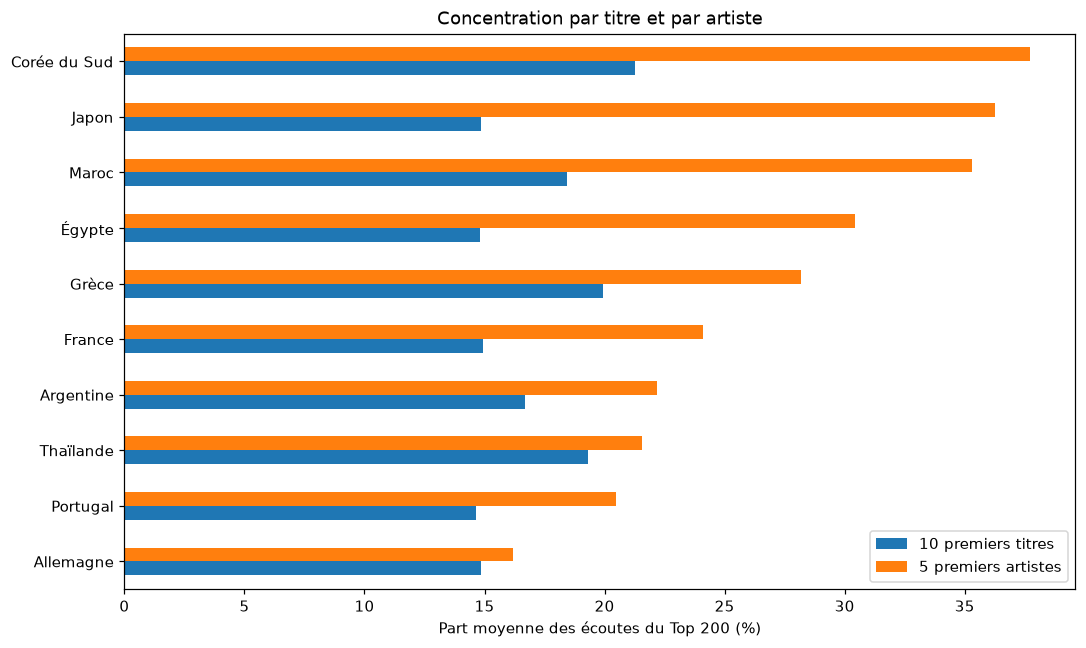

In [5]:
resume = titres.groupby('pays').agg(
    semaines=('top10', 'size'),
    top10_titres=('top10', 'mean'),
    titres_pour_50=('titres_pour_50', 'median'),
    titres_effectifs=('titres_effectifs', 'mean'))
resume['top5_artistes'] = top5_artistes.groupby('pays').mean()
resume = resume.sort_values('top5_artistes')
affichage = resume.copy()
affichage[['top10_titres', 'top5_artistes']] *= 100
print(affichage.round(1).to_string())

ax = (resume[['top10_titres', 'top5_artistes']] * 100).plot.barh(figsize=(10, 6))
ax.set_xlabel('Part moyenne des écoutes du Top 200 (%)')
ax.set_ylabel('')
ax.set_title('Concentration par titre et par artiste')
ax.legend(['10 premiers titres', '5 premiers artistes'])
plt.tight_layout()
plt.savefig(sortie / 'comparaison_pays.png', dpi=150)
plt.show()
plt.close()

En Allemagne, sur les **201 semaines complètes**, les dix premières chansons représentent en moyenne **14,9 % des écoutes du Top 200**. Leur poids est donc près de trois fois supérieur aux 5 % qu’elles représenteraient si les 200 chansons étaient également écoutées. La médiane du nombre de titres nécessaires pour atteindre la moitié des écoutes est de **62** : une part importante des écoutes s’étend donc au-delà des toutes premières places.

Les cinq premiers artistes allemands captent en moyenne **16,2 % des écoutes**. Cette valeur est inférieure aux **22,2 % observés pour la semaine du 6 octobre 2022** dans le tableau précédent. Cette semaine était donc plus concentrée sur les cinq premiers artistes que la moyenne de la période.

La comparaison avec le Japon montre l’intérêt de distinguer chansons et artistes. Les dix premières chansons y représentent en moyenne **14,8 % des écoutes**, une valeur presque identique à celle de l’Allemagne. Pourtant, les cinq premiers artistes réunissent **36,3 % des écoutes au Japon**, contre **16,2 % en Allemagne**, soit un écart de **20,1 points**. La concentration est donc comparable en tête du classement des chansons, mais nettement plus élevée au Japon lorsqu’on rassemble les titres par artiste.

Ces résultats montrent qu’un classement peut comporter de nombreuses chansons différentes tout en concentrant une part importante de ses écoutes sur quelques artistes. Ils décrivent les semaines complètes disponibles dans chaque pays, avec un partage égal des écoutes des collaborations.

## 6. Lire les évolutions hebdomadaires

L’axe horizontal représente les semaines ; l’axe vertical la part des écoutes, en %. La ligne pointillée est la moyenne du pays. Une hausse du Top 5 des artistes signifie que cinq artistes réunissent une plus grande fraction du classement cette semaine-là, même si le volume total d’écoutes baisse.

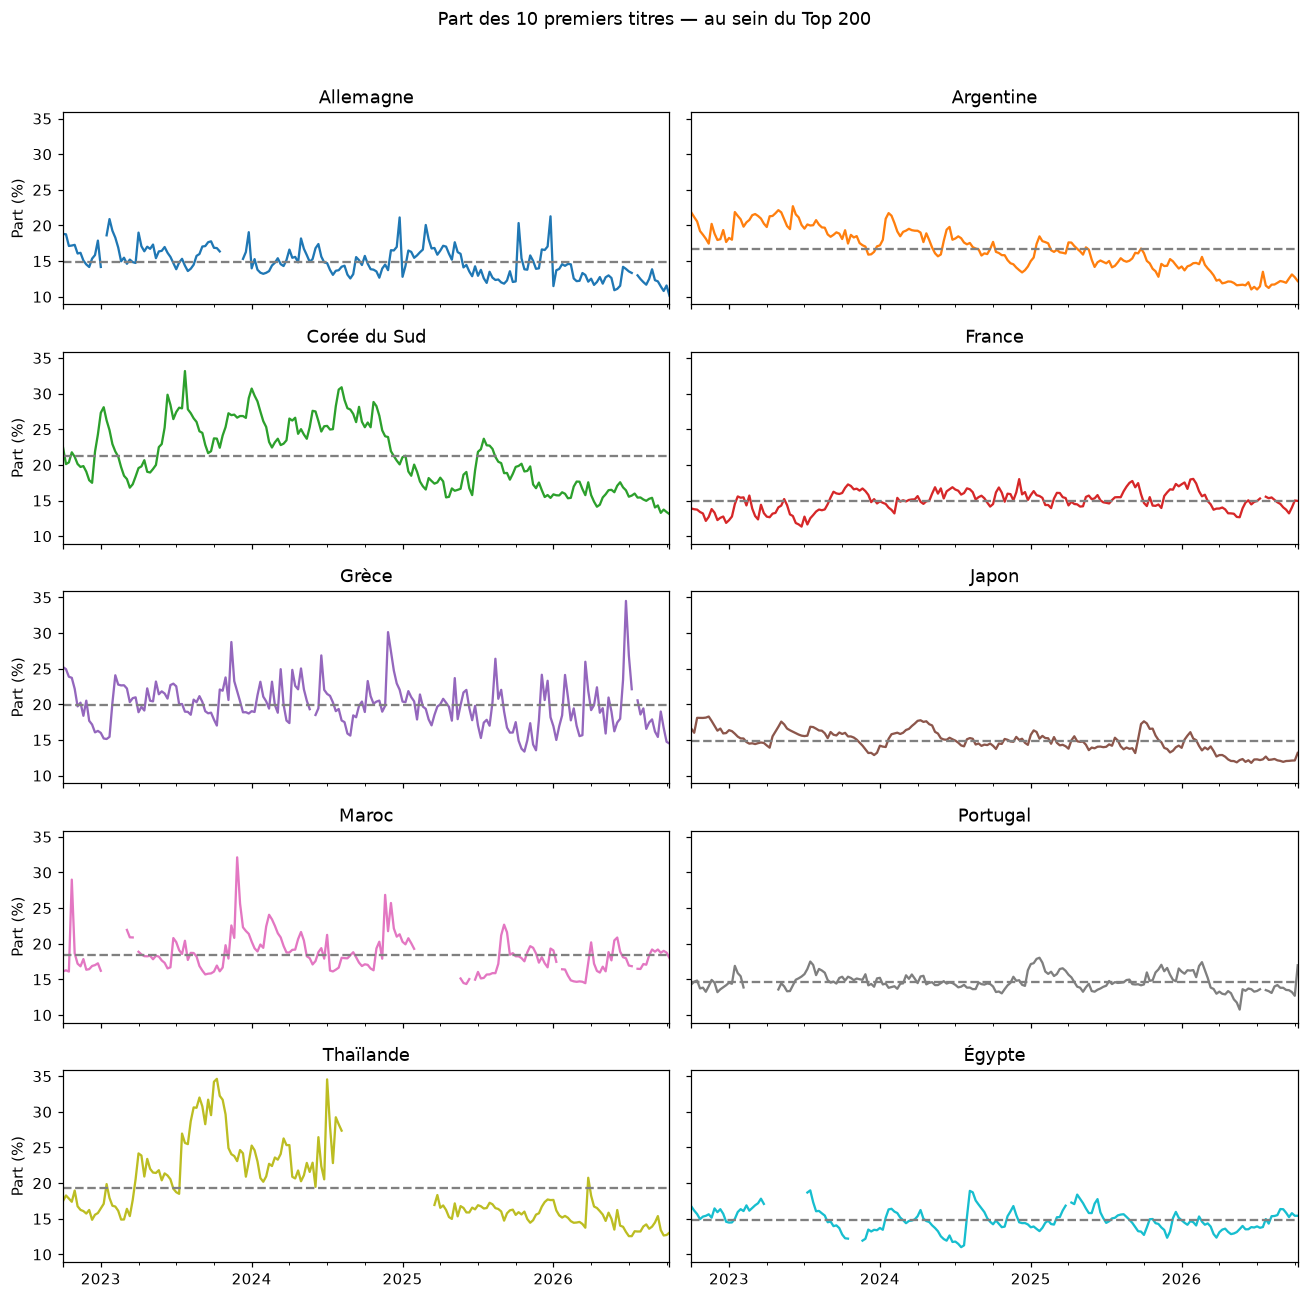

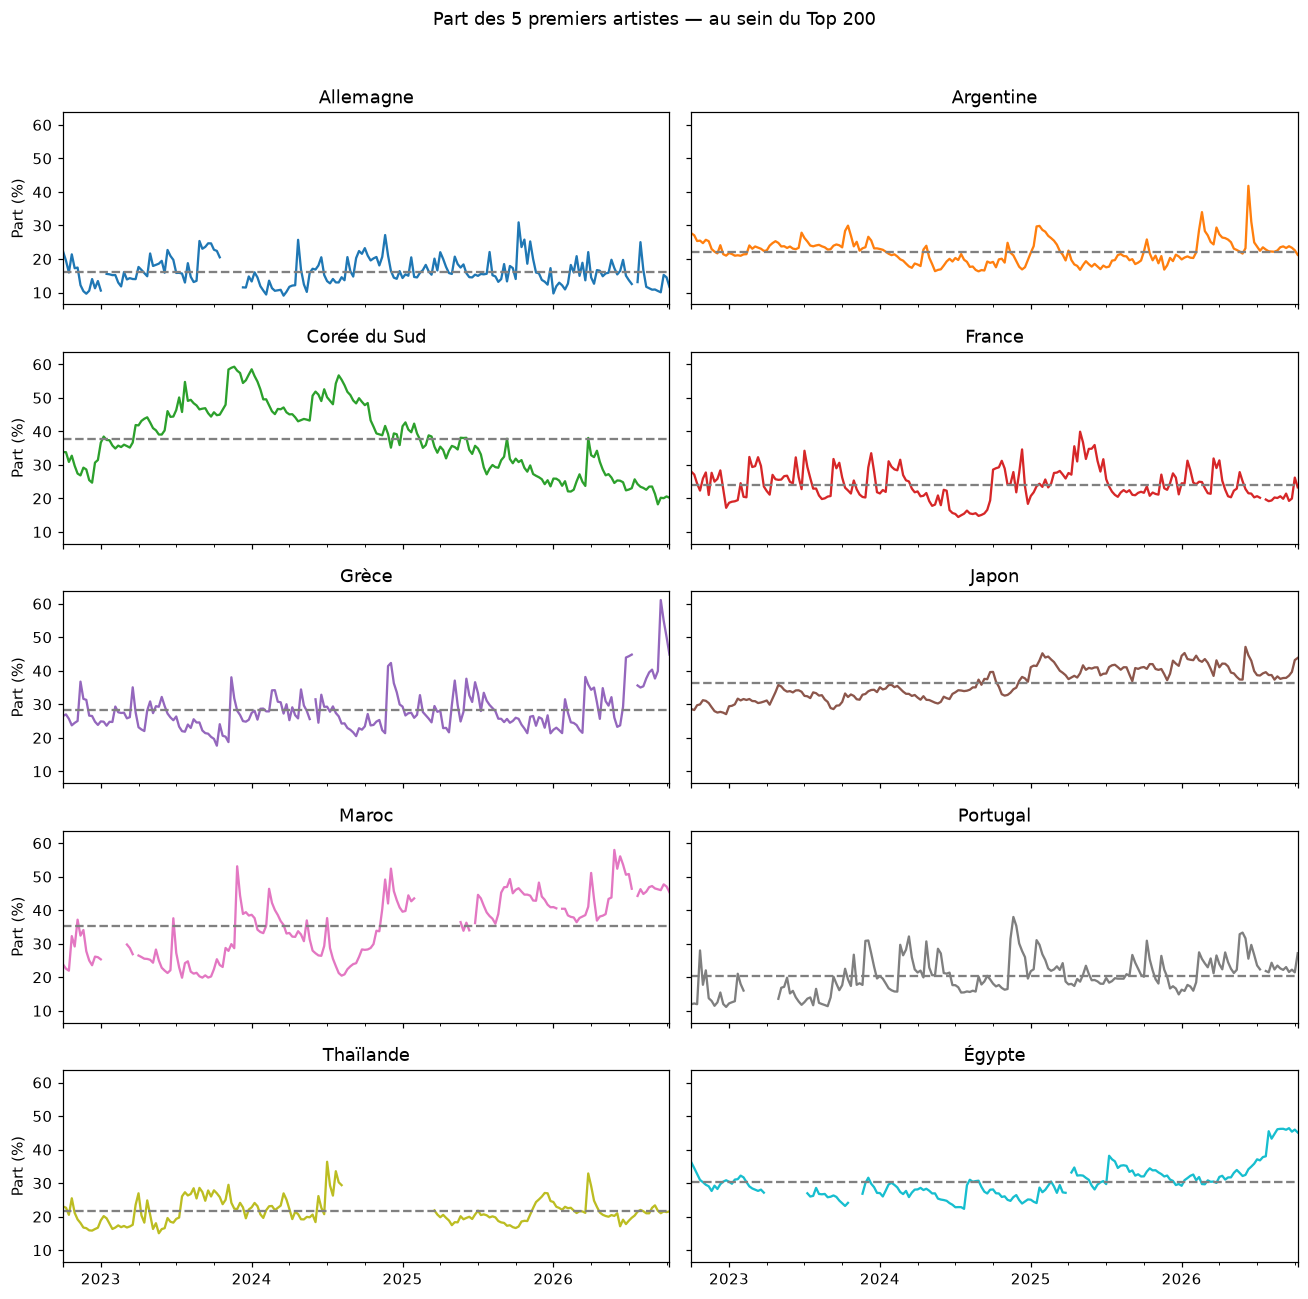

In [6]:
hebdo = titres[['top10']].copy()
hebdo['top5_artistes'] = top5_artistes
semaines = pd.date_range(base['semaine'].min(), base['semaine'].max(), freq='W-THU')

for variable, titre in [('top10', 'Part des 10 premiers titres'),
                         ('top5_artistes', 'Part des 5 premiers artistes')]:
    tableau = hebdo[variable].unstack('pays').reindex(semaines) * 100
    axes = tableau.plot(subplots=True, layout=(5, 2), figsize=(12, 12),
                        sharex=True, sharey=True, legend=False)
    for ax, pays in zip(axes.flat, tableau.columns):
        ax.set_title(pays)
        ax.axhline(tableau[pays].mean(), color='gray', linestyle='--')
        ax.set_ylabel('Part (%)')
    plt.suptitle(titre + ' — au sein du Top 200')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(sortie / (variable + '_evolution.png'), dpi=150)
    plt.show()
    plt.close()

 Les niveaux moyens donnent un repère : le Top 5 des artistes vaut 37,7 % en Corée du Sud contre 16,2 % en Allemagne. Les courbes permettent de voir les fluctuations autour de ces niveaux. Un pic ne suffit pas à identifier une sortie d’album : il faudrait examiner les titres et artistes de cette semaine. Les interruptions correspondent aux semaines exclues, jamais à zéro écoute.

## 7. Les résultats résistent-ils aux choix de méthode ?

Cette partie cherche à savoir si les différences de concentration observées entre pays restent présentes lorsqu’on change certaines décisions de calcul. **Si les résultats restent proches, nos conclusions sont moins dépendantes de ces choix. S’ils changent beaucoup, il faut les nuancer.**

On teste trois points :
- **Les semaines exclues :** les réintégrer permet de voir si leur suppression modifie les moyennes.
- **Les collaborations :** attribuer toutes les écoutes au premier artiste permet de vérifier si le partage égal influence fortement la concentration mesurée.
- **Les périodes comparées :** retenir les mêmes 134 semaines pour tous les pays évite qu’une différence entre pays provienne simplement de semaines différentes dans les données.

L’objectif est donc de déterminer quelles conclusions sont stables et lesquelles dépendent davantage de notre méthode.

In [7]:
base['part'] = base['streams'] / base.groupby(cles)['streams'].transform('sum')
tous_top10 = base.sort_values(cles + ['rank']).groupby(cles).head(10).groupby(cles)['part'].sum().groupby('pays').mean()
verification = resume[['top10_titres', 'top5_artistes']].copy()
verification['top10_avec_incomplets'] = tous_top10

premiers = donnees.copy()
premiers['premier_artiste'] = premiers['artistes'].str[0]
premiers = premiers.groupby(cles + ['premier_artiste'])['streams'].sum().reset_index()
premiers['part'] = premiers['streams'] / premiers.groupby(cles)['streams'].transform('sum')
premiers = premiers.sort_values(cles + ['streams'], ascending=[True, True, False])
premiers['position'] = premiers.groupby(cles).cumcount() + 1
verification['top5_premier_credit'] = premiers[premiers['position'] <= 5].groupby(cles)['part'].sum().groupby('pays').mean()

nombre_pays = controle['complet'].groupby('semaine').sum()
semaines_communes = nombre_pays[nombre_pays == base['pays'].nunique()].index
commun = hebdo.reset_index()
commun = commun[commun['semaine'].isin(semaines_communes)]
verification['top10_semaines_communes'] = commun.groupby('pays')['top10'].mean()
verification['top5_semaines_communes'] = commun.groupby('pays')['top5_artistes'].mean()
print('Semaines complètes communes :', len(semaines_communes))
print((verification * 100).round(1).to_string())

Semaines complètes communes : 134
              top10_titres  top5_artistes  top10_avec_incomplets  top5_premier_credit  top10_semaines_communes  top5_semaines_communes
pays                                                                                                                                  
Allemagne             14.9           16.2                   14.9                 18.3                     14.4                    15.6
Portugal              14.7           20.5                   14.6                 21.8                     14.5                    20.4
Thaïlande             19.3           21.6                   19.9                 22.8                     19.2                    22.1
Argentine             16.7           22.2                   16.7                 24.6                     16.1                    22.3
France                14.9           24.1                   14.9                 25.1                     15.0                    23.4
Grèce                

L’inclusion des classements incomplets modifie la part moyenne du Top 10 d’au maximum **0,61 point de pourcentage** selon le pays : son effet sur cet indicateur reste limité. En revanche, le traitement des collaborations peut modifier sensiblement la concentration par artiste. En Grèce, la part moyenne des cinq premiers artistes passe de **28,2 % avec partage égal à 38,8 % avec attribution au premier crédit**, soit **10,6 points de plus**. Les résultats par artiste doivent donc être présentés avec la convention utilisée. La comparaison sur les semaines communes permet également de comparer les pays sur un calendrier identique.

# 4. PREFERENCE NATIONALE, LANGUES ET QUOTAS

## 4.1. MESURES DESCRIPTIVES

# IV.1 — Répertoires nationaux, langues et quotas

## 1. Les données utilisées

On étudie la place des artistes nationaux et des langues locales dans les classements Spotify de dix pays, entre octobre 2022 et octobre 2026. On compare ensuite ces résultats selon les informations disponibles sur les quotas radio.

La base Spotify donne le pays d’écoute, la semaine, le titre, les artistes crédités et les écoutes. Les tables d’enrichissement ajoutent les origines des artistes et les langues des chansons. Le fichier des quotas sert à constituer les groupes de pays.

Une ligne représente une chanson dans un pays pendant une semaine. Les résultats décrivent uniquement les écoutes des titres du Top 200 : les chansons hors classement ne sont pas observées.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Ouvrir les fichiers
dossier = Path.cwd()
sortie = dossier / 'resultats'
sortie.mkdir(exist_ok=True)

base = pd.read_csv(dossier / 'base_complete.csv')
artistes = pd.read_csv(dossier / 'artistes_nationalites_recherche_web.csv')
chansons = pd.read_csv(dossier / 'chansons_2_complete_langues_precisees.csv')
quotas = pd.read_excel(dossier / 'QUOTAS.xlsx', engine='openpyxl')
print(base.shape)
print(base.head(3).to_string(index=False))

(419891, 11)
 rank                                  uri        artist_names                               track_name                        source  peak_rank  previous_rank  weeks_on_chart  streams      pays    semaine
    1 spotify:track:5ww2BF9slyYgNOk37BlC4u       Manuel Turizo                               La Bachata Sony Music Latin/La Industria          1              1              17  4434508 Argentine 2022-10-06
    2 spotify:track:2tTmW7RDtMQtBk7m2rYeSw   Bizarrap, Quevedo Quevedo: Bzrp Music Sessions, Vol. 52/66             DALE PLAY Records          1              2              14  3793440 Argentine 2022-10-06
    3 spotify:track:45dlaEXrXW47TVbrQ4gK7E Rei, Callejero Fino                               Tu Turrito             DALE PLAY Records          3              3              22  3279246 Argentine 2022-10-06


La base initiale contient **419 891 lignes et 11 colonnes**. Dans les premières lignes affichées, *La Bachata* occupe la première place en Argentine pour la semaine du 6 octobre 2022, avec **4 434 508 écoutes**. Il s’agit des écoutes de ce titre dans ce pays et cette semaine, pas de son total mondial. Une même chanson peut donc apparaître sur plusieurs lignes lorsqu’elle est classée ailleurs ou une autre semaine.

## 2. Rattacher les origines et les langues

On rapproche la base des classements des deux tables d’enrichissement. L’origine est rattachée par le crédit d’artistes ; la langue par le couple artistes–titre, pour éviter de confondre deux chansons portant le même nom.

Les jointures conservent toutes les observations Spotify, même sans correspondance. Les contrôles vérifient qu’elles ne multiplient pas les lignes et les écoutes. On définit également les codes des pays et la liste des langues retenues comme locales dans chacun.

In [2]:
# Ajouter les origines et les langues aux classements
# many_to_one : plusieurs lignes Spotify peuvent correspondre à une même fiche.
# Une fiche dupliquée provoquerait une erreur au lieu de multiplier les écoutes.
donnees = base.merge(artistes, on='artist_names', how='left', validate='many_to_one')
donnees = donnees.merge(chansons, on=['artist_names', 'track_name'],
                        how='left', validate='many_to_one')
assert len(donnees) == len(base)
assert not donnees.duplicated(['pays', 'semaine', 'uri']).any()
assert donnees['streams'].notna().all() and (donnees['streams'] > 0).all()
assert donnees['rank'].between(1, 200).all()
donnees['semaine'] = pd.to_datetime(donnees['semaine'])

codes_pays = {
    'France': 'fr', 'Allemagne': 'de', 'Argentine': 'ar', 'Portugal': 'pt',
    'Japon': 'jp', 'Grèce': 'gr', 'Maroc': 'ma', 'Égypte': 'eg',
    'Thaïlande': 'th', 'Corée du Sud': 'kr'
}
langues_locales = {
    'France': ['fra', 'fre'], 'Allemagne': ['deu', 'ger'], 'Argentine': ['spa'],
    'Portugal': ['por'], 'Japon': ['jpn'], 'Grèce': ['ell', 'gre'],
    'Maroc': ['ara', 'arb', 'ary', 'ber', 'zgh', 'tzm', 'shi', 'rif'],
    'Égypte': ['ara', 'arb', 'arz'], 'Thaïlande': ['tha'], 'Corée du Sud': ['kor']
}

Après cette étape, les informations d’origine et de langue sont associées aux observations Spotify. Les contrôles portent sur la cohérence du rapprochement ; ils ne garantissent pas l’exactitude des annotations. Les résultats devront donc être lus comme des mesures fondées sur les origines et langues renseignées dans la base.

## 3. Distinguer origine nationale et langue locale

On construit trois indicateurs pour chaque chanson :

- **National** : au moins une origine renseignée correspond au pays du classement. Une collaboration internationale compte donc comme nationale dès qu’une de ses origines est locale.
- **Langue locale** : au moins une langue renseignée appartient à la liste retenue pour le pays d’écoute.
- **Anglais** : l’anglais figure parmi les langues de la chanson.

On repère aussi les titres dont l’origine ou la langue est inconnue. Les cellules contenant plusieurs codes sont transformées en listes, sans compter deux fois le même code.

In [3]:
# Transformer les cellules contenant plusieurs codes en listes
def lire_codes(valeur):
    if pd.isna(valeur):
        return []
    texte = str(valeur).lower().replace(';', ',').replace(' ', ',')
    inconnus = ['', 'nan', 'mul', 'und', 'unknown', 'indetermine',
                'indéterminé', 'inconnue', 'inconnu', 'none']
    resultat = []
    for code in texte.split(','):
        if code not in inconnus and code not in resultat:
            resultat.append(code)
    return resultat

donnees['origines'] = donnees['nationalite'].apply(lire_codes)
donnees['langues'] = donnees['langue'].apply(lire_codes)

# Un titre est national si au moins une origine renseignée correspond au pays.
# Un titre bilingue peut être à la fois en langue locale et en anglais.
nationaux = []
locaux = []
anglais = []
for pays, origines, langues in zip(donnees['pays'], donnees['origines'], donnees['langues']):
    nationaux.append(codes_pays[pays] in origines)
    est_local = False
    for langue in langues:
        if langue in langues_locales[pays]:
            est_local = True
    locaux.append(est_local)
    anglais.append('eng' in langues)

donnees['national'] = nationaux
donnees['langue_locale'] = locaux
donnees['anglais'] = anglais
donnees['origine_connue'] = donnees['origines'].str.len() > 0
donnees['langue_connue'] = donnees['langues'].str.len() > 0

Ces indicateurs mesurent des dimensions différentes. Le critère d’origine porte sur les artistes, alors que celui de langue porte sur la chanson. Ils peuvent donc donner des résultats différents pour un même pays. Une chanson bilingue peut être classée à la fois en langue locale et en anglais : ces parts ne doivent pas être additionnées comme des catégories exclusives. Les origines renseignées sont utilisées comme approximation du répertoire national.

## 4. Conserver les classements complets

On compte les titres et les rangs distincts pour chaque pays et chaque semaine. Un classement est complet s’il contient **200 titres et 200 rangs différents**. Une chanson manquante peut modifier le total des écoutes et la part des catégories étudiées ; les calculs principaux utilisent donc seulement les classements complets.

Dans le tableau, **sum** indique le nombre de semaines complètes et **count** le nombre total de semaines disponibles.

In [4]:
# Repérer les semaines complètes : 200 titres et 200 rangs différents
controle = donnees.groupby(['pays', 'semaine']).agg(
    nombre_titres=('uri', 'size'), nombre_rangs=('rank', 'nunique'))
controle['complet'] = (controle['nombre_titres'] == 200) & (controle['nombre_rangs'] == 200)
controle.to_csv(sortie / 'controle_classements.csv', encoding='utf-8-sig')
donnees = donnees.merge(controle[['complet']], on=['pays', 'semaine'], validate='many_to_one')
print(controle.groupby("pays")["complet"].agg(["sum", "count"]).to_string())

              sum  count
pays                    
Allemagne     201    210
Argentine     210    210
Corée du Sud  210    210
France        209    210
Grèce         208    210
Japon         210    210
Maroc         184    210
Portugal      198    210
Thaïlande     179    210
Égypte        191    210


On dispose de **210 semaines par pays**, mais toutes ne contiennent pas 200 titres. La France conserve **209 semaines sur 210**, l’Allemagne **201**, contre **179** pour la Thaïlande. Au total, **2 000 classements sur 2 100** sont complets.

Les moyennes par pays reposent donc sur des nombres de semaines différents. Pour la comparaison des groupes de quotas, on retiendra ensuite uniquement les semaines complètes communes aux dix pays, afin de travailler sur le même calendrier.

## 5. Calculer les parts d’écoutes

Pour chaque pays et chaque semaine, on calcule :

**Part nationale = écoutes des titres identifiés comme nationaux / écoutes totales du classement.**

La même formule est appliquée aux titres en langue locale et aux titres contenant de l’anglais. Les chansons pèsent selon leur nombre d’écoutes. On fait ensuite la moyenne des parts hebdomadaires : chaque semaine complète a le même poids. Le tableau ci-dessous est affiché en pourcentages.

Deux indicateurs complètent ces parts :

- **Couverture** : proportion des écoutes pour lesquelles l’origine ou la langue est renseignée. Elle mesure la disponibilité de l’information, pas sa fiabilité.
- **Borne haute** : part identifiée à laquelle on ajoute les écoutes dont l’information manque. Elle correspond au cas où tous les titres non renseignés appartiendraient à la catégorie. Elle ne couvre pas les erreurs possibles dans les annotations connues.

Les titres non renseignés restent dans le total au dénominateur. Les calculs sont faits sur le Top 200 et sur le Top 50 ; le tableau affiché ici concerne le Top 200.

In [5]:
# Calculer les parts pour chaque pays et semaine, puis pour le Top 50
indicateurs = ['national', 'langue_locale', 'anglais']
lignes = []
for top in [200, 50]:
    selection = donnees[donnees['complet'] & (donnees['rank'] <= top)]
    for (pays, semaine), groupe in selection.groupby(['pays', 'semaine']):
        total = groupe['streams'].sum()
        ligne = {'pays': pays, 'semaine': semaine, 'top': top}
        for indicateur in indicateurs:
            ecoutes = groupe.loc[groupe[indicateur], 'streams'].sum()
            connu = 'langue_connue'
            if indicateur == 'national':
                connu = 'origine_connue'
            inconnues = groupe.loc[~groupe[connu], 'streams'].sum()
            ligne[indicateur] = ecoutes / total
            ligne[indicateur + '_borne_haute'] = (ecoutes + inconnues) / total
        ligne['couverture_origine'] = groupe.loc[groupe['origine_connue'], 'streams'].sum() / total
        ligne['couverture_langue'] = groupe.loc[groupe['langue_connue'], 'streams'].sum() / total
        lignes.append(ligne)

resultats = pd.DataFrame(lignes)
resultats.to_csv(sortie / 'indicateurs_hebdomadaires.csv', index=False, encoding='utf-8-sig')
colonnes = indicateurs + ['couverture_origine', 'couverture_langue']
moyennes = resultats.groupby(['top', 'pays'])[colonnes].mean()
moyennes.to_csv(sortie / 'moyennes.csv', encoding='utf-8-sig')
print((moyennes.loc[200] * 100).round(1).to_string())

              national  langue_locale  anglais  couverture_origine  couverture_langue
pays                                                                                 
Allemagne         43.7           38.5     55.4                99.0               97.1
Argentine         55.6           89.1      7.3                99.1               98.2
Corée du Sud      76.1           20.7     71.8                99.8               90.1
France            69.4           65.8     27.9                99.4               96.0
Grèce             66.8           89.2      8.2                98.1               98.3
Japon             84.6           85.0      9.7                99.7               94.9
Maroc             51.2           58.6     13.9                97.3               89.8
Portugal          24.7           43.1     41.5                99.4               94.3
Thaïlande         50.7           65.8     30.0                97.2               97.6
Égypte            76.5           85.4      8.1        

En France, les titres d’origine nationale représentent en moyenne **69,4 % des écoutes du Top 200**, soit environ sept écoutes sur dix. Cette part est de **43,7 % en Allemagne**, un écart de **25,7 points**. Les répertoires nationaux occupent donc des places différentes dans les classements des deux pays.

Au Portugal, la part nationale atteint **24,7 %**, alors que la langue locale représente **43,1 %**. L’écart de **18,4 points** montre que la présence d’une langue locale ne se confond pas avec celle d’artistes nationaux. Ces parts pouvant se recouper, cet écart ne mesure pas directement la part des seuls artistes étrangers chantant en portugais.

La couverture linguistique est de **96,0 % en France** : environ 4 % des écoutes restent sans langue identifiée. Pour la part en langue locale, la moyenne de la borne haute se situe donc autour de **69,8 %**, contre **65,8 % identifiés**. Cette marge concerne uniquement les informations manquantes.

Le profil de la Corée du Sud mérite une vérification des annotations : **76,1 %** d’origine nationale, mais **20,7 %** de langue locale et **71,8 %** d’anglais identifié. Les indicateurs peuvent différer, mais ce contraste ne suffit pas à établir une préférence réelle sans examiner la qualité des langues renseignées.

## 6. Suivre les évolutions hebdomadaires

Les moyennes peuvent masquer des semaines particulières. On trace donc, pour chaque pays, les parts nationale, en langue locale et en anglais au fil du temps.

L’axe horizontal donne la semaine ; l’axe vertical la part des écoutes en pourcentage. La courbe montre la part identifiée.

Une hausse signifie que la catégorie gagne du poids dans le classement. Elle ne prouve pas que son nombre absolu d’écoutes augmente : le total peut lui aussi changer.

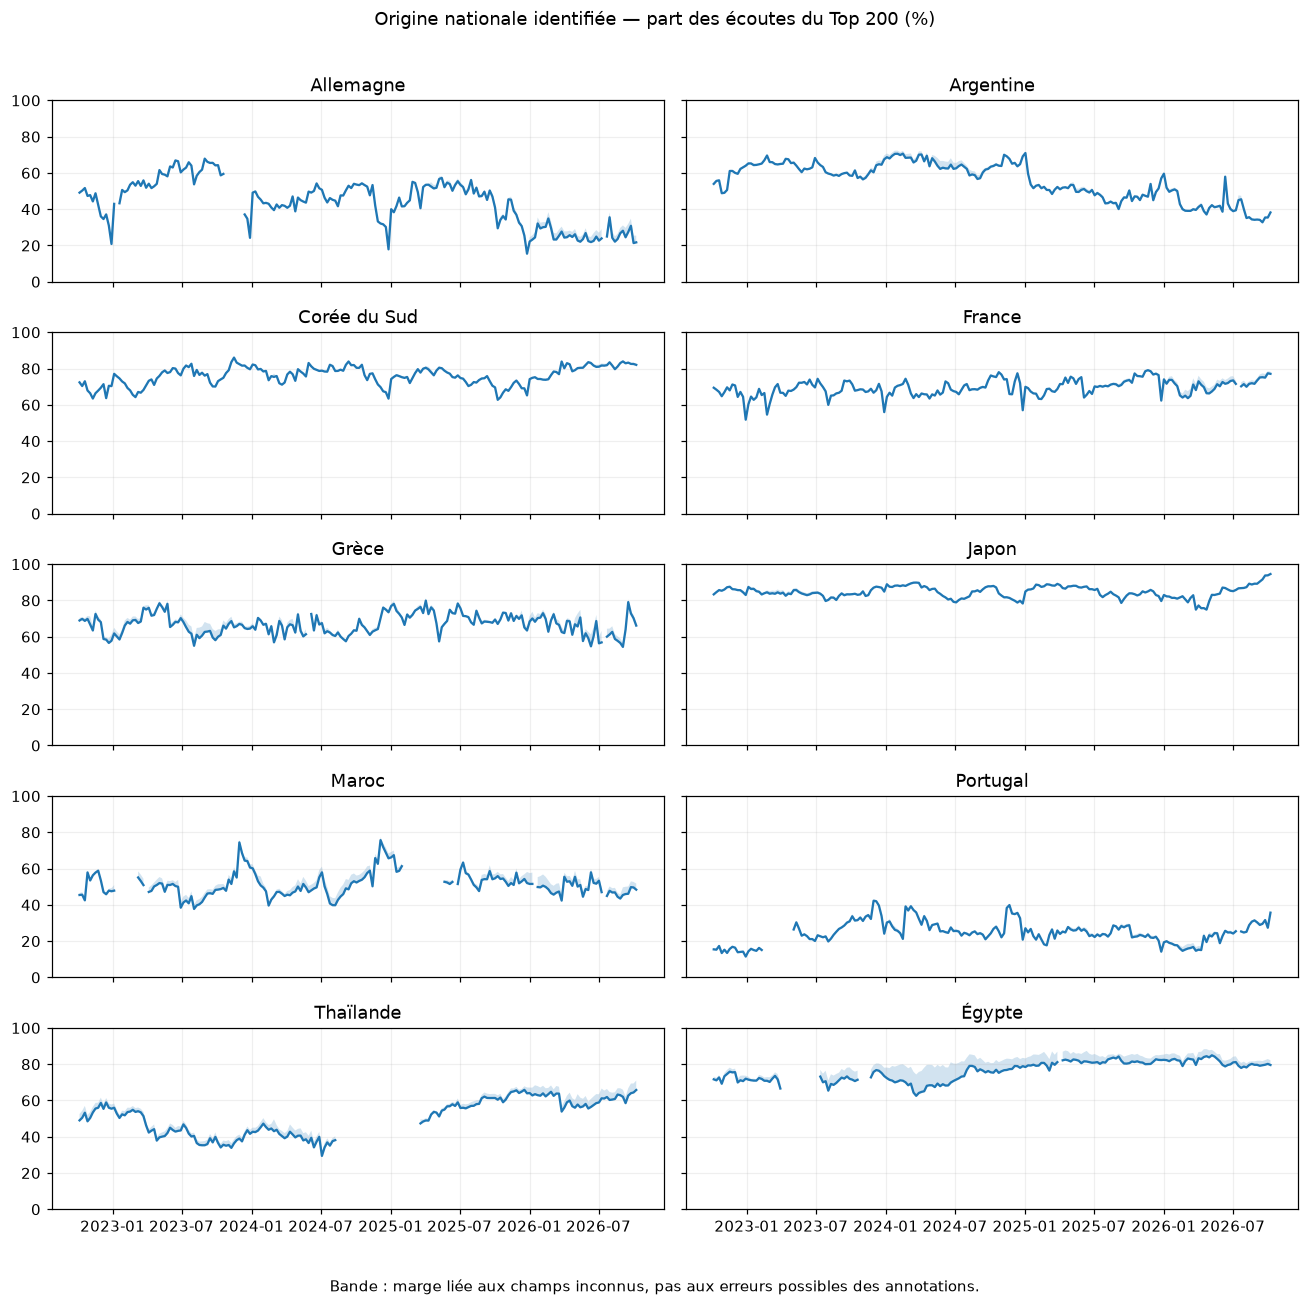

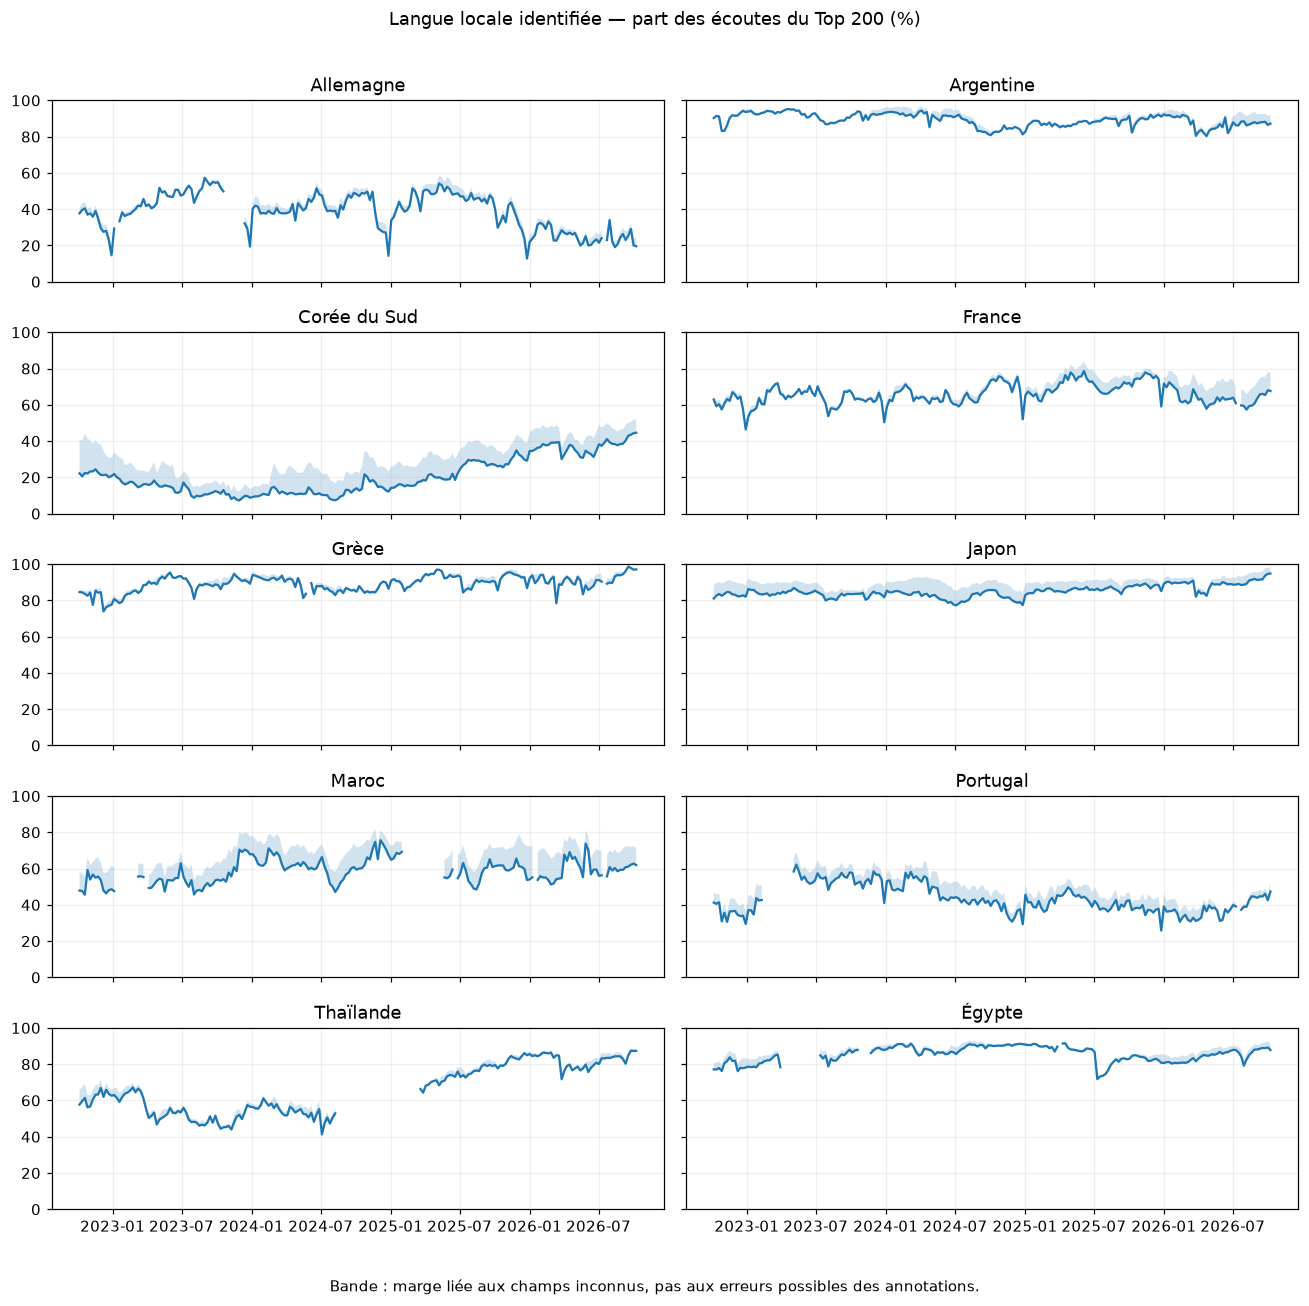

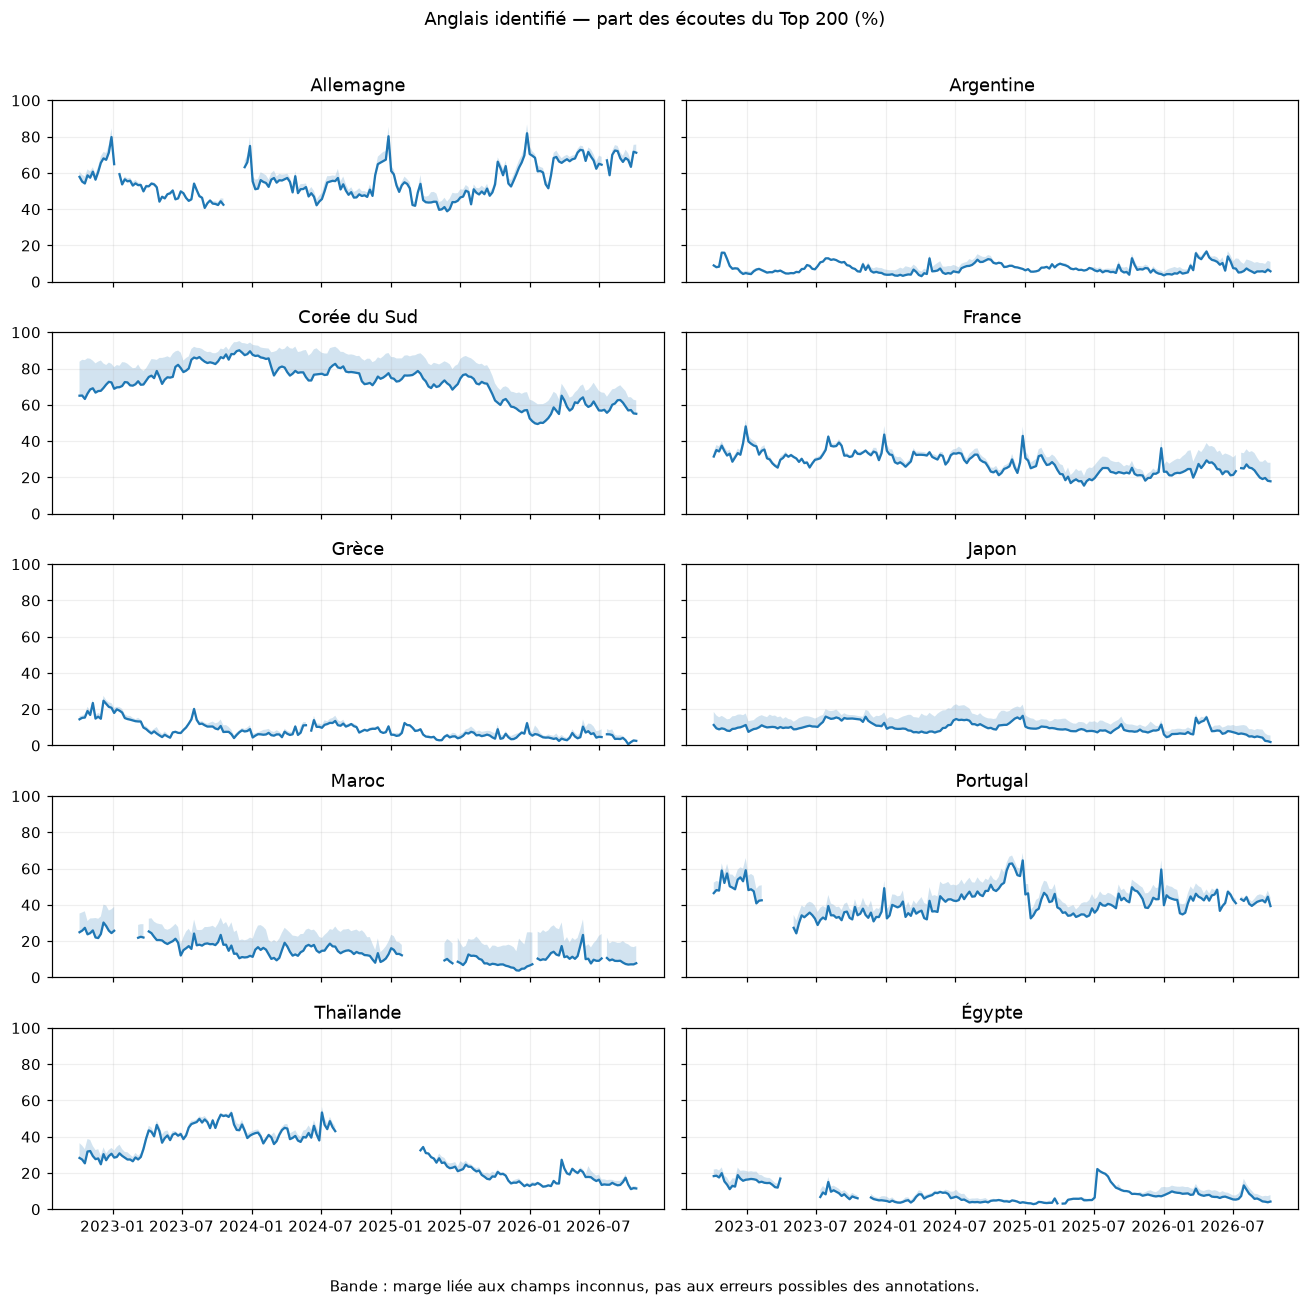

In [6]:
# Tracer les trois graphiques d'évolution par pays
titres = ['Origine nationale identifiée', 'Langue locale identifiée', 'Anglais identifié']
calendrier = pd.date_range(donnees['semaine'].min(), donnees['semaine'].max(), freq='W-THU')
for indicateur, titre in zip(indicateurs, titres):
    figure, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, sharey=True)
    for axe, pays in zip(axes.flat, sorted(codes_pays)):
        courbe = resultats[(resultats['top'] == 200) & (resultats['pays'] == pays)]
        courbe = courbe.set_index('semaine').reindex(calendrier)
        axe.plot(courbe.index, courbe[indicateur] * 100)
        axe.fill_between(courbe.index, courbe[indicateur] * 100,
                         courbe[indicateur + '_borne_haute'] * 100, alpha=0.2)
        axe.set_title(pays)
        axe.set_ylim(0, 100)
        axe.grid(alpha=0.2)
    figure.suptitle(titre + ' — part des écoutes du Top 200 (%)')
    figure.text(0.5, 0.01, 'Bande : marge liée aux champs inconnus, pas aux erreurs possibles des annotations.', ha='center')
    figure.tight_layout(rect=(0, 0.04, 1, 0.97))
    figure.savefig(sortie / (indicateur + '.png'), dpi=150)
    plt.show()
    plt.close(figure)

Les évolutions montrent que le profil moyen ne décrit pas toutes les semaines. En Allemagne, la part nationale varie de **15,5 % le 25 décembre 2025** à **67,9 % le 31 août 2023**. La semaine du 25 décembre 2025, la part en anglais atteint **81,9 %**, bien au-dessus de sa moyenne de **55,4 %**. La composition linguistique du classement change donc fortement pendant certaines semaines. La date évoque un possible effet des chansons de Noël, mais il faudrait identifier les titres concernés pour le confirmer.

Au Japon, la part nationale reste comprise entre **74,9 % et 94,6 %** sur les semaines complètes étudiées. Sa moyenne élevée de **84,6 %** correspond ainsi à une présence nationale majoritaire sur toute la période observée, plutôt qu’à quelques pics isolés.

En France, la part nationale passe selon les semaines de **51,8 % à 79,1 %**. Elle reste majoritaire dans les classements complets étudiés, avec des variations que la seule moyenne de 69,4 % ne montre pas.

## 7. Croiser les origines et les pays d’écoute

La matrice détaille la provenance des écoutes : **chaque colonne est un pays d’écoute et chaque ligne une origine d’artiste**. Une case contient la part moyenne des écoutes attribuée à cette origine dans ce pays.

Pour construire une répartition sans double comptage, les écoutes d’un titre sont partagées également entre ses origines distinctes. On calcule les parts chaque semaine, puis leur moyenne. Les origines inconnues restent dans une catégorie séparée, et les origines moins représentées sont regroupées dans « autres ».

Cette convention diffère de la part nationale précédente : celle-ci compte intégralement une collaboration dès qu’au moins une origine est nationale. La diagonale de la matrice n’a donc pas vocation à reproduire exactement cette part.

pays     France  Allemagne
origine                   
fr         63.8        2.3
de          1.2       38.1
us         14.1       30.9
gb          4.7        9.8


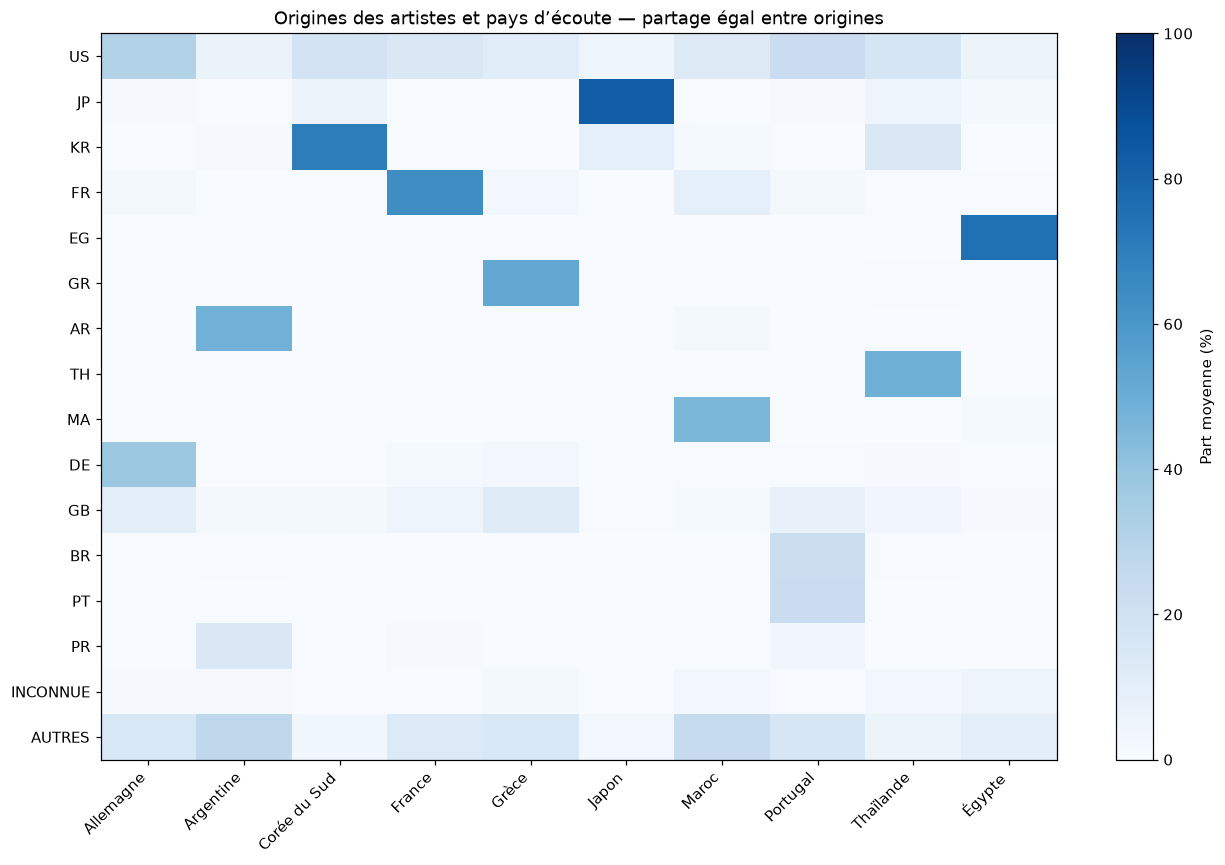

In [7]:
# Qui écoute les musiques de quels pays ?
# Pour cette matrice seulement, on partage également les écoutes entre origines.
# Une collaboration FR/US reçoit moitié FR, moitié US : pas de double comptage.
repartition = donnees[donnees['complet']].copy()
origines_matrice = []
for origines in repartition['origines']:
    if len(origines) == 0:
        origines_matrice.append(['inconnue'])
    else:
        origines_matrice.append(origines)
repartition['origine'] = origines_matrice
repartition['ecoutes_partagees'] = repartition['streams'] / repartition['origine'].str.len()
repartition = repartition.explode('origine')
matrice_semaine = repartition.groupby(['pays', 'semaine', 'origine'])['ecoutes_partagees'].sum().unstack(fill_value=0)
matrice_semaine = matrice_semaine.div(matrice_semaine.sum(axis=1), axis=0)
matrice = matrice_semaine.groupby('pays').mean().T
matrice.to_csv(sortie / 'matrice_origines.csv', encoding='utf-8-sig')
principales = list(matrice.mean(axis=1).nlargest(15).index)
if 'inconnue' not in principales:
    principales.append('inconnue')
vue = matrice.reindex(principales, fill_value=0)
vue.loc['autres'] = matrice.drop(index=principales, errors='ignore').sum()
figure, axe = plt.subplots(figsize=(12, 8))
image = axe.imshow(vue * 100, cmap='Blues', aspect='auto', vmin=0, vmax=100)
axe.set_xticks(range(len(vue.columns)), vue.columns, rotation=45, ha='right')
axe.set_yticks(range(len(vue)), vue.index.str.upper())
axe.set_title('Origines des artistes et pays d’écoute — partage égal entre origines')
figure.colorbar(image, ax=axe, label='Part moyenne (%)')
figure.tight_layout()
figure.savefig(sortie / 'matrice_origines.png', dpi=150)
plt.show()
plt.close(figure)
print((matrice[["France", "Allemagne"]].loc[["fr", "de", "us", "gb"]] * 100).round(1).to_string())

L’origine américaine représente **30,9 % des écoutes en Allemagne**, contre **14,1 % en France** : son poids est plus de deux fois supérieur dans le classement allemand selon cette convention. L’origine britannique représente également davantage d’écoutes en Allemagne (**9,8 %**) qu’en France (**4,7 %**).

Les origines française et allemande restent beaucoup plus présentes sur leur propre marché : l’origine française représente **63,8 % en France contre 2,3 % en Allemagne** ; l’origine allemande **38,1 % en Allemagne contre 1,2 % en France**. La matrice fait ainsi apparaître un ancrage national et une présence internationale importante de certains répertoires.

Les **63,8 %** attribués à l’origine française sont inférieurs aux **69,4 %** de part nationale calculés plus haut, notamment parce que les collaborations internationales sont ici réparties entre les origines. Ces chiffres répondent à deux conventions de calcul différentes. Une origine américaine ou britannique ne détermine pas à elle seule la langue chantée.

## 8. Comparer les plus gros succès au reste du classement

On compare la part nationale dans le Top 50 et dans le Top 200, sur les mêmes semaines complètes. Pour le Top 50, le dénominateur est le total des écoutes des cinquante premiers titres.

**Écart = part nationale dans le Top 50 − part nationale dans le Top 200.**

Un écart positif signifie que les origines nationales sont davantage représentées parmi les plus gros succès. Un écart négatif signifie qu’elles pèsent moins dans le Top 50. Les écarts sont exprimés en points de pourcentage : il s’agit d’une comparaison de périmètres, pas d’une évolution dans le temps.

In [8]:
verification = moyennes['national'].unstack('top') * 100
verification.columns = ['Top 50 (%)', 'Top 200 (%)']
verification['Écart Top 50 - Top 200 (points)'] = verification['Top 50 (%)'] - verification['Top 200 (%)']
print(verification.round(1).to_string())

              Top 50 (%)  Top 200 (%)  Écart Top 50 - Top 200 (points)
pays                                                                  
Allemagne           46.0         43.7                              2.3
Argentine           52.5         55.6                             -3.1
Corée du Sud        83.4         76.1                              7.3
France              73.6         69.4                              4.2
Grèce               69.7         66.8                              2.9
Japon               84.6         84.6                             -0.0
Maroc               54.5         51.2                              3.3
Portugal            27.1         24.7                              2.4
Thaïlande           49.2         50.7                             -1.5
Égypte              80.6         76.5                              4.1


En France, la part nationale passe de **69,4 % dans le Top 200 à 73,6 % dans le Top 50**, soit **+4,2 points**. Les titres nationaux pèsent donc davantage parmi les premières places. Le phénomène est plus marqué en Corée du Sud : **83,4 % contre 76,1 %**, soit **+7,3 points**, sous réserve des limites de l’enrichissement.

La situation n’est pas générale : en Argentine, la part passe de **55,6 % à 52,5 %**, soit **−3,1 points**. Les origines nationales y sont un peu moins représentées parmi les cinquante premiers titres que dans l’ensemble du Top 200. Au Japon, les deux valeurs sont presque identiques à l’arrondi (**84,6 %**).

Le contraste France–Allemagne reste visible avec le Top 50 (**73,6 % contre 46,0 %**). Il ne dépend donc pas uniquement des titres situés entre les rangs 51 et 200.

## 9. Définir les groupes de quotas

Le tableau fourni classe les pays selon la présence indiquée d’un quota. On utilise deux scénarios pour vérifier l’influence de ce classement :

- **groupe_fourni** conserve les catégories du fichier ;
- **groupe_prudent** met la Grèce et le Maroc à part, en raison des ambiguïtés documentées sur les dispositifs concernés.

Le classement est appliqué à toute la période. Il ne reconstitue pas les changements de lois semaine par semaine et ne mesure ni le niveau précis des obligations, ni leur application. Les quotas concernent la diffusion radio, tandis que les résultats étudiés concernent Spotify.

In [9]:
# Rapprocher les quotas et les résultats
noms_pays = {}
for pays, code in codes_pays.items():
    noms_pays[code] = pays
quotas['pays'] = quotas['country'].map(noms_pays)
assert quotas['pays'].notna().all() and not quotas['pays'].duplicated().any()
assert set(quotas['pays']) == set(donnees['pays'])
assert quotas['quota'].isin([0, 1]).all()
quotas['groupe_fourni'] = quotas['quota'].map({1: 'Quota indiqué', 0: 'Absence indiquée'})
quotas['groupe_prudent'] = quotas['groupe_fourni']
# La source grecque ne démontre pas un quota radio obligatoire.
# Certains cahiers des charges marocains contiennent des obligations.
# Les autres absences sont déclarées dans le fichier, mais non vérifiées.
quotas.loc[quotas['country'].isin(['gr', 'ma']), 'groupe_prudent'] = 'Mis à part'
quotas.to_csv(sortie / 'quotas_utilises.csv', index=False, encoding='utf-8-sig')
resultats = resultats.merge(quotas[['pays', 'groupe_fourni', 'groupe_prudent']],
                            on='pays', validate='many_to_one')
print(quotas[["pays", "quota", "groupe_prudent"]].to_string(index=False))

        pays  quota   groupe_prudent
   Argentine      1    Quota indiqué
   Allemagne      0 Absence indiquée
      Égypte      0 Absence indiquée
      France      1    Quota indiqué
       Grèce      1       Mis à part
       Japon      0 Absence indiquée
Corée du Sud      0 Absence indiquée
       Maroc      0       Mis à part
    Portugal      1    Quota indiqué
   Thaïlande      0 Absence indiquée


Le scénario prudent compare **trois pays avec quota indiqué** — Argentine, France et Portugal — à **cinq pays avec absence indiquée** — Allemagne, Égypte, Japon, Corée du Sud et Thaïlande. La Grèce et le Maroc ne participent pas à cette seconde comparaison.

Les absences indiquées dans le fichier ne sont pas toutes documentées. Le terme « absence indiquée » doit donc être conservé dans l’interprétation. Les résultats décrivent ces groupes particuliers ; ils ne représentent pas automatiquement tous les pays avec et sans quota. Le détail des réserves et des sources est conservé à la fin du notebook.

## 10. Comparer les groupes sur les mêmes semaines

On retient uniquement les semaines où les dix pays ont un classement complet. On calcule ensuite la moyenne des parts de chaque pays sur ces semaines, puis la moyenne des pays de chaque groupe.

**Moyenne d’un groupe = somme des moyennes de ses pays / nombre de pays.**

Chaque pays a le même poids, quel que soit son volume d’écoutes. Cela permet de comparer des profils de pays sans laisser les plus gros marchés dominer le résultat. Les colonnes national, langue_locale et anglais du tableau sont des proportions : **0,489 correspond à 48,9 %**. La colonne scenario distingue les deux classifications, et top le périmètre 50 ou 200.

In [10]:
# Comparer sur les mêmes semaines, avec le même poids pour chaque pays
nombre_pays = resultats[resultats['top'] == 200].groupby('semaine')['pays'].nunique()
semaines_communes = nombre_pays[nombre_pays == len(codes_pays)].index
commun = resultats[resultats['semaine'].isin(semaines_communes)]
moyennes_pays = commun.groupby(['top', 'pays', 'groupe_fourni', 'groupe_prudent'])[indicateurs].mean().reset_index()
moyennes_pays.to_csv(sortie / 'pays_semaines_communes.csv', index=False, encoding='utf-8-sig')
comparaisons = []
for scenario in ['groupe_fourni', 'groupe_prudent']:
    selection = moyennes_pays[moyennes_pays[scenario] != 'Mis à part']
    tableau = selection.groupby(['top', scenario])[indicateurs].mean()
    tableau['nombre_pays'] = selection.groupby(['top', scenario])['pays'].nunique()
    tableau = tableau.reset_index().rename(columns={scenario: 'groupe'})
    tableau['scenario'] = scenario
    comparaisons.append(tableau)
comparaison = pd.concat(comparaisons, ignore_index=True)
comparaison.to_csv(sortie / 'comparaison_quotas.csv', index=False, encoding='utf-8-sig')
print("Semaines communes :", len(semaines_communes))
print(comparaison.round(3).to_string(index=False))

Semaines communes : 134
 top           groupe  national  langue_locale  anglais  nombre_pays       scenario
  50 Absence indiquée     0.651          0.595    0.319            6  groupe_fourni
  50    Quota indiqué     0.547          0.751    0.175            4  groupe_fourni
 200 Absence indiquée     0.632          0.593    0.311            6  groupe_fourni
 200    Quota indiqué     0.531          0.716    0.210            4  groupe_fourni
  50 Absence indiquée     0.679          0.593    0.363            5 groupe_prudent
  50    Quota indiqué     0.503          0.686    0.220            3 groupe_prudent
 200 Absence indiquée     0.659          0.596    0.346            5 groupe_prudent
 200    Quota indiqué     0.489          0.656    0.254            3 groupe_prudent


La comparaison utilise **134 semaines communes**. Pour le Top 200 dans le scénario prudent, la part nationale moyenne vaut **48,9 % dans le groupe avec quota indiqué**, contre **65,9 % dans le groupe d’absence indiquée**. L’écart est d’environ **−17 points** : les pays du premier groupe n’ont donc pas, dans cet échantillon, une part nationale plus élevée.

Pour la langue locale, le sens s’inverse : **65,6 % contre 59,6 %**, soit environ **+6 points**. La part d’anglais est plus faible dans le groupe avec quota indiqué : **25,4 % contre 34,6 %**, soit environ **−9,2 points**. Une part plus élevée de langue locale peut ainsi coexister avec une part plus faible d’artistes nationaux.

Avec le classement fourni, la part nationale est de **53,1 % contre 63,2 %**. Le sens de l’écart reste le même, mais son ampleur change : environ **−10,1 points**, au lieu de −17. La composition des groupes influence donc le résultat. Ces écarts ne prouvent pas que les quotas en sont la cause : les pays diffèrent aussi par leurs langues et leurs marchés musicaux.

## 11. Représenter les écarts entre groupes

Les barres représentent les moyennes du scénario prudent pour le Top 200. Les trois graphiques comparent successivement l’origine nationale, les langues locales et l’anglais.

Les courbes donnent ensuite, chaque semaine commune, la moyenne des parts des pays du groupe. Une valeur de 60 % correspond donc à une moyenne des parts nationales, et non à la part calculée en additionnant toutes les écoutes de ces pays. Les dates non communes restent vides.

Les courbes permettent de voir si les écarts moyens sont constants ou s’ils varient au cours de la période.

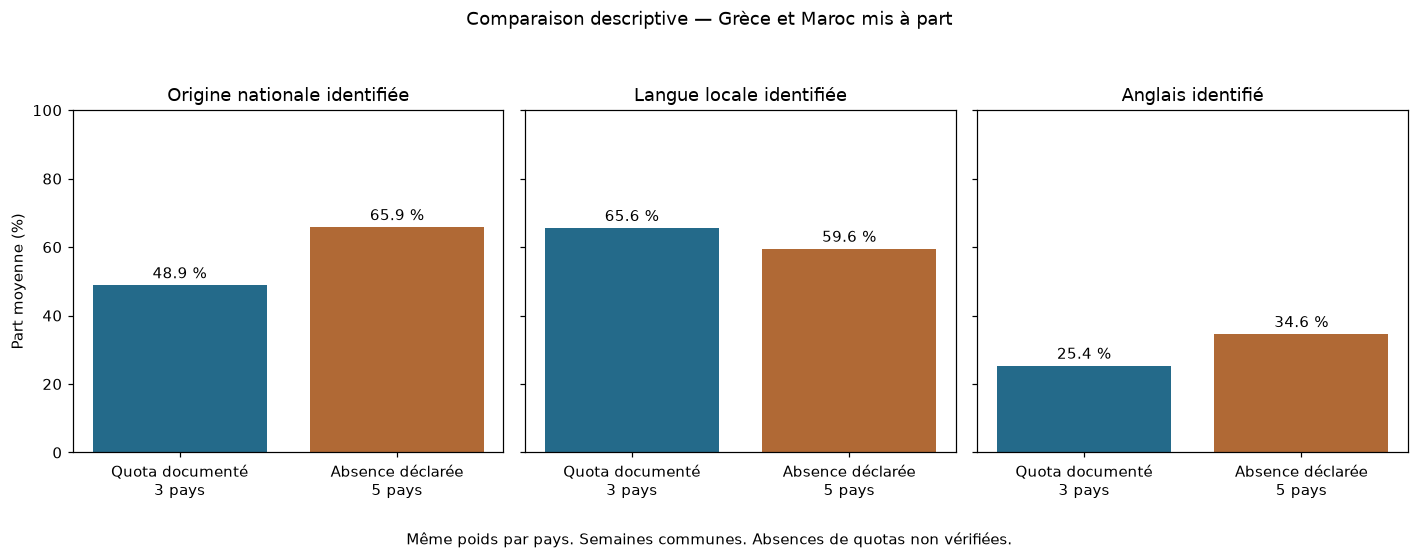

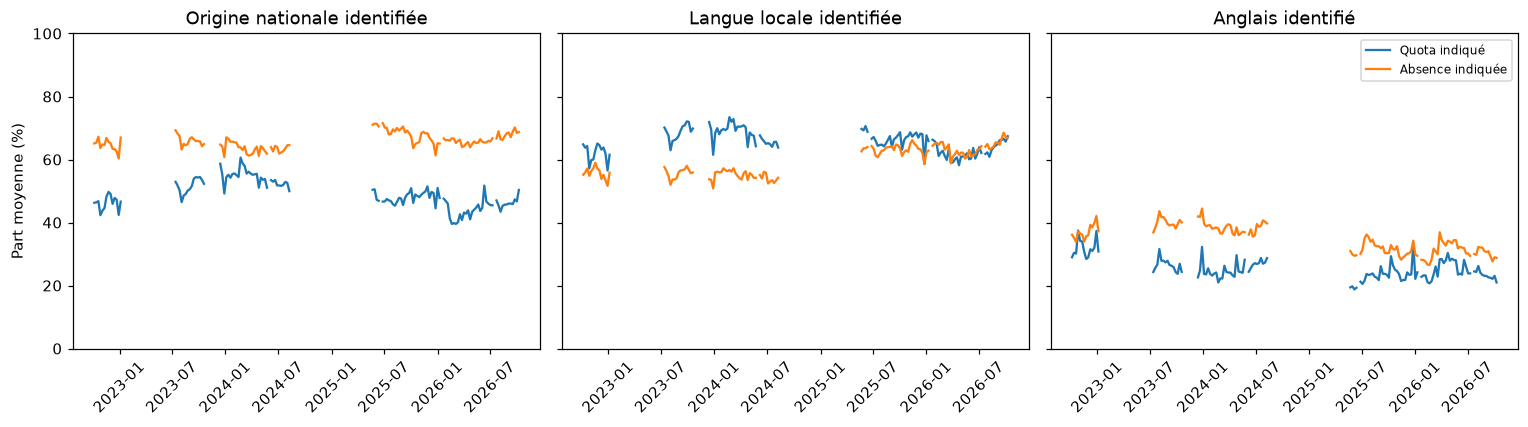

In [11]:
# Tracer la comparaison des groupes et leur évolution
groupes = ['Quota indiqué', 'Absence indiquée']
figure, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)
selection = comparaison[(comparaison['scenario'] == 'groupe_prudent') & (comparaison['top'] == 200)]
selection = selection.set_index('groupe').reindex(groupes)
for axe, indicateur, titre in zip(axes, indicateurs, titres):
    axe.bar([0, 1], selection[indicateur] * 100, color=['#246a8a', '#b06935'])
    axe.set_xticks([0, 1], ['Quota documenté\n3 pays', 'Absence déclarée\n5 pays'])
    axe.set_title(titre)
    axe.set_ylim(0, 100)
    for position in [0, 1]:
        valeur = selection[indicateur].iloc[position] * 100
        axe.text(position, valeur + 2, f'{valeur:.1f} %', ha='center')
axes[0].set_ylabel('Part moyenne (%)')
figure.suptitle('Comparaison descriptive — Grèce et Maroc mis à part')
figure.text(0.5, 0.01, 'Même poids par pays. Semaines communes. Absences de quotas non vérifiées.', ha='center')
figure.tight_layout(rect=(0, 0.06, 1, 0.94))
figure.savefig(sortie / 'comparaison_quotas.png', dpi=150)
plt.show()
plt.close(figure)

figure, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for axe, indicateur, titre in zip(axes, indicateurs, titres):
    for groupe in groupes:
        selection = commun[(commun['top'] == 200) & (commun['groupe_prudent'] == groupe)]
        courbe = selection.groupby('semaine')[indicateur].mean().reindex(calendrier)
        axe.plot(courbe.index, courbe * 100, label=groupe)
    axe.set_title(titre)
    axe.set_ylim(0, 100)
    axe.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Part moyenne (%)')
axes[-1].legend(fontsize=8)
figure.tight_layout()
figure.savefig(sortie / 'evolution_groupes.png', dpi=150)
plt.show()
plt.close(figure)



Les barres résument un résultat contrasté : le groupe avec quota indiqué présente une **part nationale plus faible**, mais une **part en langue locale plus élevée** et une **part d’anglais plus faible**. Il n’existe donc pas ici une association uniforme entre quotas et présence nationale, quelle que soit la dimension retenue.

Le contrôle sur le Top 50 conserve le sens de l’écart de part nationale : **50,3 % contre 67,9 %** dans le scénario prudent. La différence ne repose donc pas seulement sur les titres moins bien classés. Les courbes montrent les fluctuations autour des moyennes, mais une variation du groupe ne prouve pas que tous ses pays évoluent de la même manière.

Au total, les classements conservent des profils nationaux et linguistiques distincts. La comparaison des groupes apporte un constat descriptif ; elle ne permet pas d’isoler l’effet des quotas radio sur le streaming. Une conclusion plus forte nécessiterait notamment un historique réglementaire vérifié et une méthode tenant compte des autres différences entre pays.

## 4.2. INDICE DE BIAIS DOMESTIQUE

Pour chaque pays, on compare deux parts de musique nationale : sa part dans le Top 200 de son propre pays, et sa part dans les Top 200 des neuf autres pays.

indice = part de musique nationale dans son pays ÷ part de cette musique dans les 9 autres pays

Si l'indice est plus grand que 1, les gens écoutent plus leur musique nationale que les autres pays ne le font. Les parts sont calculées avec les écoutes (streams).

Une chanson est « nationale » si au moins un de ses artistes est du pays.

**Étape 2 : voir comment sont écrites les nouvelles colonnes**

Les nationalités sont des codes de pays à 2 lettres (FR, JP...) et les langues des codes à 3 lettres (eng, fra...). Quand une chanson a plusieurs artistes, il y a plusieurs nationalités séparées par un point-virgule.

In [55]:
print(base["nationalite"].value_counts().head(10))
print(base["langue"].value_counts().head(10))
print((base["nationalite"] == "").mean())

nationalite
US    50939
JP    37856
KR    34174
EG    32491
FR    28468
TH    25024
MA    21200
AR    20163
GR    18112
DE    16207
Name: count, dtype: int64
langue
eng    90570
ara    60941
spa    45596
ell    38540
jpn    37988
fra    36201
tha    31090
kor    24098
por    20920
deu    16739
Name: count, dtype: int64
6.192083183492859e-05


In [56]:
autres = base[base["nationalite"].str.len() != 2]
print(len(autres) / len(base))
print(autres["nationalite"].value_counts().head(15))

0.15451152799178836
nationalite
GB;US    3334
KR;US    2905
GR;HK    1893
CA;US    1692
KR;JP    1551
GR;GB    1534
FR;US    1220
FR;BE    1179
GB;GR    1133
GR;US     981
DE;US     942
FR;MA     778
CO;PR     671
US;GB     667
AO;PT     637
Name: count, dtype: int64


**Étape 3 : Calcul de l'indice  pour les 10 pays**

In [57]:
codes = {"Allemagne": "DE", "Argentine": "AR", "Corée du Sud": "KR", "Égypte": "EG", "France": "FR",
         "Grèce": "GR", "Japon": "JP", "Maroc": "MA", "Portugal": "PT", "Thaïlande": "TH"}

resultats = []

for nom, code in codes.items():
    chez_lui = base[base["pays"] == nom]
    autres = base[base["pays"] != nom]
    part_chez_lui = chez_lui[chez_lui["nationalite"].str.contains(code)]["streams"].sum() / chez_lui["streams"].sum()
    part_ailleurs = autres[autres["nationalite"].str.contains(code)]["streams"].sum() / autres["streams"].sum()
    resultats.append([nom, part_chez_lui, part_ailleurs, part_chez_lui / part_ailleurs])

indices = pd.DataFrame(resultats, columns=["pays", "part_chez_lui", "part_ailleurs", "indice"])
print(indices.round(6))

           pays  part_chez_lui  part_ailleurs        indice
0     Allemagne       0.460083       0.008490     54.189625
1     Argentine       0.593449       0.000836    709.908956
2  Corée du Sud       0.776349       0.037197     20.871313
3        Égypte       0.826537       0.000048  17352.929038
4        France       0.696236       0.017639     39.471570
5         Grèce       0.685312       0.000126   5419.369517
6         Japon       0.870367       0.009432     92.276752
7         Maroc       0.646209       0.001115    579.654520
8      Portugal       0.247602       0.000005  45672.321404
9     Thaïlande       0.608657       0.000095   6401.579269


**Étape 4 : graphique de l'indice**

Les indices vont de 21 à plus de 45 000. On utilise une échelle logarithmique pour tout voir sur le même graphique.

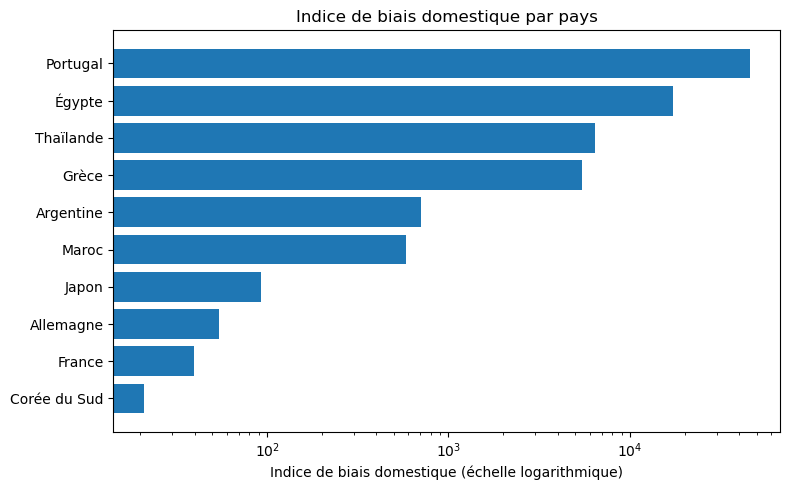

In [58]:
# Graphique à barres : un indice par pays, du plus petit au plus grand
indices = indices.sort_values("indice")

plt.figure(figsize=(8, 5))
plt.barh(indices["pays"], indices["indice"])
plt.xscale("log")
plt.xlabel("Indice de biais domestique (échelle logarithmique)")
plt.title("Indice de biais domestique par pays")
plt.tight_layout()
plt.show()

Le même graphique avec une couleur par groupe : bleu = pays avec quota (France, Portugal, Argentine, Grèce), gris = pays sans quota.

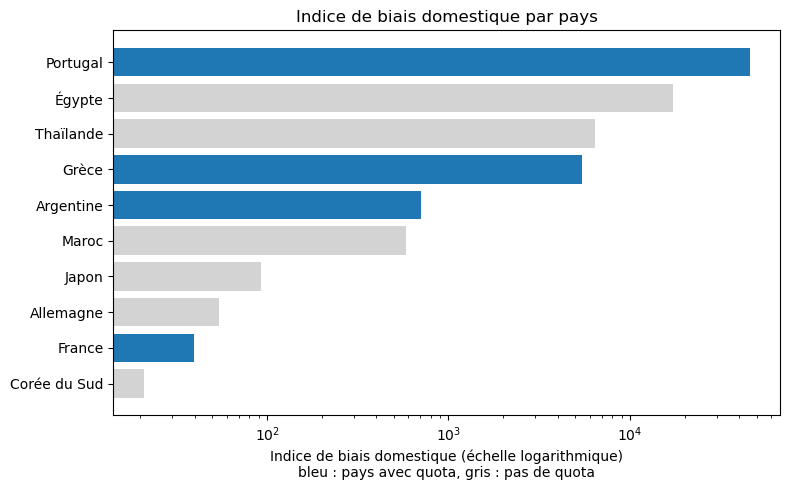

In [59]:
groupes = {"France": "quota", "Portugal": "quota", "Argentine": "quota", "Grèce": "quota",
           "Allemagne": "pas de quota", "Japon": "pas de quota", "Thaïlande": "pas de quota",
           "Corée du Sud": "pas de quota", "Maroc": "pas de quota", "Égypte": "pas de quota"}
couleurs = {"quota": "tab:blue", "pas de quota": "lightgray"}

indices["groupe"] = indices["pays"].map(groupes)

plt.figure(figsize=(8, 5))
plt.barh(indices["pays"], indices["indice"], color=indices["groupe"].map(couleurs))
plt.xscale("log")
plt.xlabel("Indice de biais domestique (échelle logarithmique)\nbleu : pays avec quota, gris : pas de quota")
plt.title("Indice de biais domestique par pays")
plt.tight_layout()
plt.show()

**Ce que montre l'indice**

- Dans les 10 pays, la musique nationale pèse beaucoup dans le Top 200 du pays : de 25 % (Portugal) à 87 % (Japon) des écoutes. Les indices sont tous bien plus grands que 1.
- Les indices sont très différents : de 21 (Corée du Sud) à plus de 45 000 (Portugal). Du plus haut au plus bas : Portugal, Égypte, Thaïlande, Grèce, Argentine, Maroc, Japon, Allemagne, France, Corée du Sud.
- On ne voit pas de séparation claire entre pays avec quota et sans quota : le Portugal (quota) est premier, la Grèce (quota) quatrième, l'Argentine (quota) cinquième, la France (quota) neuvième, et l'Égypte et la Thaïlande (sans quota) ont des indices très élevés.

**À retenir de 4.2**

- La musique nationale fait de 25 % (Portugal) à 87 % (Japon) des écoutes du Top 200 de son pays : il y a un biais domestique dans les 10 pays.
- Les indices vont de 21 à plus de 45 000.
- On ne voit pas de séparation claire entre pays avec quota et sans quota.

## 4.3. MODELE ECONOMETRIQUE

Dans cette partie, trois modèles de régression linéaire seront estimés à partir de la spécification générale suivante :

$$
\log(\text{streams}_{ict}) = \alpha_{it}+\delta_{ct}
+ \beta\,\text{National}_{ic}
+ \gamma\,\text{LangueLocale}_{ic}
+ \varepsilon_{ict}
$$

Les estimations seront réalisées sur trois échantillons :
- l’ensemble des données ;
- les pays appliquant des quotas ;
- les pays n’appliquant pas de quotas.

L'objectif est de mesurer deux choses : **les artistes nationaux bénéficient-ils de davantage d'écoutes dans leur pays ? Et les chansons chantées dans la langue locale y sont-elles davantage écoutées ?**

Pour répondre à ces questions, nous comparons les écoutes d'un même titre, au cours d'une même semaine, dans différents pays. Cela permet de mieux isoler le rôle de la nationalité de l'artiste et de la langue de la chanson.

#### 1. Présentation des variables

Chaque observation correspond à un titre $i$, dans un pays $c$, au cours d'une semaine $t$.

- **log(streams)** : logarithme des écoutes du titre. Pour un coefficient $\beta$, l'écart correspondant est de $(e^\beta-1)\times100$ %.
- **National** : vaut 1 si au moins un artiste du titre est originaire du pays du classement (un titre d'Aya Nakamura est national en France, mais pas en Allemagne).
- **LangueLocale** : vaut 1 si le titre est chanté dans la langue principale du pays.
- **$\alpha_{it}$** : effet fixe titre-semaine. Il neutralise ce qui est commun à un titre une semaine donnée (popularité, promotion, notoriété) : on compare le même titre entre pays, au même moment.
- **$\delta_{ct}$** : effet fixe pays-semaine. Il neutralise ce qui est commun aux titres d'un pays une semaine donnée (taille du marché, niveau d'écoute, événements locaux).
- **$\beta$ et $\gamma$** : coefficients estimés simultanément, associés à la nationalité de l'artiste et à la langue locale.
- **$\varepsilon$** : autres facteurs non pris en compte.

Les écarts-types sont regroupés par titre, car les observations d'un même titre ne sont pas indépendantes.

#### 2. Choix des effets fixes

Les écoutes d'un titre évoluent fortement dans le temps : maximales après la sortie, elles déclinent ensuite. Comparer un même titre entre pays sans contrôler cette dimension mélangerait l'effet du pays et celui de l'ancienneté du titre. Il faut donc **contrôler l'effet temporel**, et se pose la question du niveau retenu. Le niveau annuel est trop grossier : la partie 3.1 a montré de fortes différences entre mois (pic de décembre dans 9 pays sur 10, creux de mars-avril en Égypte et au Maroc). Le choix se fait donc entre le mois et la semaine.

Les statistiques de l'étape 2 montrent que les deux donnent presque le même résultat, car les titres classés dans plusieurs pays le sont presque toujours la même semaine. **La semaine est retenue parce qu'elle est plus rigoureuse** : elle compare le titre au même moment exact de sa diffusion, alors qu'un mois regroupe quatre à cinq semaines pendant lesquelles ses écoutes évoluent. L'effet fixe pays-semaine neutralise de même l'évolution propre à chaque marché (croissance du nombre d'utilisateurs, ramadan en Égypte et au Maroc), ce qu'un effet fixe pays constant ne peut pas faire. Un simple effet fixe titre, sans dimension temporelle, est testé en robustesse (étape 3).

**Limite : les résultats ne valent que pour les titres internationaux.** Seuls les titres classés dans au moins deux pays pendant la même semaine contribuent à l'estimation, soit 88 030 observations sur environ 419 000. Un titre classé dans un seul pays ne peut pas être comparé à lui-même d'un pays à l'autre.

#### 3. Comparaison des pays avec et sans quotas

Le même modèle est estimé sur trois échantillons : l'ensemble des pays, les pays appliquant des quotas et ceux n'en appliquant pas. Si les coefficients sont plus élevés avec quotas, les artistes nationaux ou les chansons en langue locale y bénéficieraient d'un avantage plus important. Cette comparaison ne permet toutefois pas d'attribuer l'écart aux quotas : les deux groupes diffèrent aussi par leur langue, la taille de leur marché et leur industrie musicale.


In [48]:
# Les titres absents des fichiers deviennent "" au lieu de NaN
base["nationalite"] = base["nationalite"].fillna("")
base["langue"] = base["langue"].fillna("")

# National : le pays du classement fait-il partie de "FR;BE" ?
code_du_pays = {"Argentine": "AR", "Allemagne": "DE", "Égypte": "EG", "France": "FR",
                "Grèce": "GR", "Japon": "JP", "Corée du Sud": "KR", "Maroc": "MA",
                "Portugal": "PT", "Thaïlande": "TH"}
base["code_pays"] = base["pays"].map(code_du_pays)
base["National"] = [
    int(p in n.split(";")) for p, n in zip(base["code_pays"], base["nationalite"])
]

# LangueLocale : la langue du pays fait-elle partie de "fra, eng" ?
langue_du_pays = {"Argentine": "spa", "Allemagne": "deu", "Égypte": "ara", "France": "fra",
                  "Grèce": "ell", "Japon": "jpn", "Corée du Sud": "kor", "Maroc": "ara",
                  "Portugal": "por", "Thaïlande": "tha"}
base["langue_pays"] = base["pays"].map(langue_du_pays)
base["LangueLocale"] = [
    int(lp in l.split(", ")) for lp, l in zip(base["langue_pays"], base["langue"])
]

In [49]:
base.head()

,rank,uri,artist_names,track_name,source,peak_rank,previous_rank,weeks_on_chart,streams,pays,...,weeks_fenetre,entrants,nouveautes,re-entrants,complet,part,code_pays,National,langue_pays,LangueLocale
0,1,spotify:track:5ww2BF9slyYgNOk37BlC4u,Manuel Turizo,La Bachata,Sony Music Latin/La Industria,1,1,17,4434508,Argentine,...,1,False,False,False,True,0.034647,AR,0,spa,1
1,2,spotify:track:2tTmW7RDtMQtBk7m2rYeSw,"Bizarrap, Quevedo","Quevedo: Bzrp Music Sessions, Vol. 52/66",DALE PLAY Records,1,2,14,3793440,Argentine,...,1,False,False,False,True,0.029638,AR,1,spa,1
2,3,spotify:track:45dlaEXrXW47TVbrQ4gK7E,"Rei, Callejero Fino",Tu Turrito,DALE PLAY Records,3,3,22,3279246,Argentine,...,1,False,False,False,True,0.025621,AR,1,spa,1
3,4,spotify:track:3Ne5uYDFzHEFYAPbaBMIck,Maria Becerra,AUTOMÁTICO,300 Entertainment,4,5,4,2991284,Argentine,...,1,False,False,False,True,0.023371,AR,1,spa,1
4,5,spotify:track:53tfEupEzQRtVFOeZvk7xq,ROSALÍA,DESPECHÁ,Columbia,3,4,10,2986606,Argentine,...,1,False,False,False,True,0.023335,AR,0,spa,1


#### Étape 1 : construction des variables

In [50]:
# Variable expliquée et identifiants des effets fixes
base["log_streams"] = np.log(base["streams"])
base["titre_semaine"] = base["uri"] + "_" + base["semaine"].astype(str)
base["pays_semaine"] = base["pays"] + "_" + base["semaine"].astype(str)

In [51]:
print(base[["National", "LangueLocale"]].mean()*100)

National        61.88487
LangueLocale    71.38948
dtype: float64


On constate que 61.88 % des observations concernent des chansons d'artistes nationaux (au moins un artiste du titre est originaire du pays du classement) et que 71.39 % concernent des chansons chantées dans la langue locale.

#### Étape 2 : Choix de la fenêtre temporelle

Le contrôle du temps peut se faire par semaine ou par mois. Pour choisir, on mesure combien d'observations sont comparables entre pays (titre classé dans au moins deux pays pendant la même période) et combien portent une variation de National ou de LangueLocale, seule source d'identification des coefficients.

In [52]:
base["mois"] = pd.to_datetime(base["semaine"]).dt.to_period("M").astype(str)

lignes = {}
for nom, periode in [("Semaine", "semaine"), ("Mois", "mois")]:
    g = base.groupby(["uri", periode])
    # le titre est-il classé dans au moins 2 pays pendant la même période ?
    multi = g["pays"].transform("nunique") >= 2
    # National ou LangueLocale diffère-t-il d'un pays à l'autre pour ce titre ?
    varie = ((g["National"].transform("max") != g["National"].transform("min"))
             | (g["LangueLocale"].transform("max") != g["LangueLocale"].transform("min")))
    lignes[nom] = {"Obs. dans ≥ 2 pays (%)": 100 * multi.mean(),
                   "Titres concernés": base.loc[multi, "uri"].nunique(),
                   "Obs. où National ou LangueLocale varie (%)": 100 * varie.mean()}
print(pd.DataFrame(lignes).T.round(1).to_string())

# Parmi les titres classés dans ≥ 2 pays le même mois : part sans aucune semaine commune
nb_pays_mois = base.groupby(["uri", "mois"])["pays"].nunique()
couples = nb_pays_mois[nb_pays_mois >= 2].index
max_pays_semaine = (base.groupby(["uri", "mois", "semaine"])["pays"].nunique()
                    .groupby(["uri", "mois"]).max())
print("Titre-mois dans ≥ 2 pays sans semaine commune :",
      round(100 * (max_pays_semaine.loc[couples] < 2).mean(), 1), "%")


         Obs. dans ≥ 2 pays (%)  Titres concernés  Obs. où National ou LangueLocale varie (%)
Semaine                    21.0            2363.0                                         8.3
Mois                       22.3            2377.0                                         9.0
Titre-mois dans ≥ 2 pays sans semaine commune : 0.5 %


Les deux fenêtres donnent des résultats très proches : 21,0 % des observations concernent un titre classé dans au moins deux pays la même semaine, contre 22,3 % le même mois, et la part des observations où National ou LangueLocale varie d'un pays à l'autre pour un même titre est de 8,3 % contre 9,0 %. Les titres communs à plusieurs pays sont presque toujours classés la même semaine : sur les couples titre-mois présents dans plusieurs pays, seuls 0,5 % n'ont aucune semaine commune. Le mois n'ajoute donc presque aucune comparaison utile. **La semaine reste plus rigoureuse** : elle compare le titre au même stade de son cycle de vie, alors qu'un mois regroupe quatre à cinq semaines pendant lesquelles ses écoutes évoluent.

Deux enseignements sont à retenir. D'une part, les comparaisons reposent sur environ 2 400 titres, soit un dixième des 23 000 titres de la base : **ce sont les titres internationaux**, et les titres propres à un seul pays (J-pop, rap arabe, par exemple) n'apportent aucune information. D'autre part, seules 8 à 9 % des observations ont une nationalité ou une langue qui diffère d'un pays à l'autre pour un même titre : ce sont elles qui identifient les coefficients. Les résultats qui suivent portent donc sur la circulation internationale des titres, non sur l'ensemble des classements.

#### Étape 3 : Robustesse

In [33]:
mA = pf.feols("log_streams ~ National + LangueLocale | titre_semaine + pays_semaine",
              data=base, vcov={"CRV1": "uri"})

mB = pf.feols("log_streams ~ National + LangueLocale | uri + pays_semaine",
              data=base, vcov={"CRV1": "uri"})

mC = pf.feols("log_streams ~ National + LangueLocale | titre_semaine + pays",
              data=base, vcov={"CRV1": "uri"})

mD = pf.feols("log_streams ~ National + LangueLocale | uri + pays",
              data=base, vcov={"CRV1": "uri"})

pf.etable([mA, mB, mC, mD])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef          National  0.342*** <br> (0.063)   
1              coef      LangueLocale  0.361*** <br> (0.056)   
2                fe              pays                      -   
3                fe      pays_semaine                      x   
4                fe     titre_semaine                      x   
5                fe               uri                      -   
6             stats      Observations                 88,030   
7             stats                R²                  0.932   

                       1                      2                      3  
0  0.237*** <br> (0.052)  0.365*** <br> (0.072)  0.271*** <br> (0.057)  
1  0.209*** <br> (0.047)  0.317*** <br> (0.063)  0.182*** <br> (0.051)  
2                      -                      x                      x  
3                      x                      -                      -  
4                      -                      x                      -  
5                      x                      -                      x  
6                414,054                 88,030                414,054  
7                  0.906                  0.917                  0.892  , _body=<great_tables._gt_data.Body object at 0x7f4be95f0980>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f4b626d8050>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f4be95f12b0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f4be9527390>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f4be95f1550>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f4be95f1940>, <great_tables._gt_data.FormatInfo object at 0x7f4b626d8690>, <great_tables._gt_data.FormatInfo object at 0x7f4b626d8a50>, <great_tables._gt_data.FormatInfo object at 0x7f4be950f5c0>, <great_tables._gt_data.FormatInfo object at 0x7f4be950f950>, <great_tables._gt_data.FormatInfo object at 0x7f4be93c0170>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_

Un test de robustesse consiste à réestimer le modèle en modifiant un choix de méthode, pour vérifier que les conclusions n'en dépendent pas. Quatre combinaisons d'effets fixes sont comparées. Les spécifications avec un effet fixe titre, sans dimension temporelle, mobilisent 414 054 observations, car un titre peut être comparé d'un pays à l'autre même s'il n'y est pas classé la même semaine.

| Effets fixes | (1) Titre × semaine + pays × semaine | (2) Titre + pays × semaine | (3) Titre × semaine + pays | (4) Titre + pays |
|---|---|---|---|---|
| National | 0,342*** (+41 %) | 0,237*** (+27 %) | 0,365*** (+44 %) | 0,271*** (+31 %) |
| LangueLocale | 0,361*** (+44 %) | 0,209*** (+23 %) | 0,317*** (+37 %) | 0,182*** (+20 %) |
| Observations | 88 030 | 414 054 | 88 030 | 414 054 |
| R² | 0,932 | 0,906 | 0,917 | 0,892 |

*Écarts-types regroupés par titre. \*\*\* p < 0,001. La spécification (1) est la spécification principale. Intervalles de confiance à 95 % de la spécification (1) : National [+24 % ; +59 %], LangueLocale [+29 % ; +60 %].*

Remplacer l'effet fixe pays-semaine par un effet fixe pays modifie peu les coefficients (colonnes 1 et 3) : l'évolution propre à chaque pays biaise peu les résultats. En revanche, remplacer l'effet fixe titre-semaine par un effet fixe titre réduit nettement les deux coefficients (colonnes 1 et 2, ou 3 et 4). Celui de la nationalité reste dans l'intervalle de confiance de la spécification principale, celui de la langue locale passe sous sa borne basse. Cette baisse est cohérente avec le cycle de vie des titres : comparer un titre à des stades différents ajoute des écarts sans rapport avec la nationalité ou la langue.

Les conclusions **qualitatives** sont inchangées : dans toutes les spécifications, les deux effets restent positifs et très significatifs. L'ampleur de l'effet de la langue est toutefois plus sensible au choix des effets fixes.


#### Étape 4 : Estimation

##### 1. Sur les trois échantillons

In [34]:
pays_quotas = ["France", "Portugal", "Grèce", "Argentine"]    
pays_quota_langue=["France","Grèce"]
pays_quota_nationalite = ["Portugal", "Argentine"]  

base["quota"] = base["pays"].isin(pays_quotas).astype(int)
base["quota_langue"] = base["pays"].isin(pays_quota_langue).astype(int)
base["quota_nationalite"] = base["pays"].isin(pays_quota_nationalite).astype(int)

formule = "log_streams ~ National + LangueLocale | titre_semaine + pays_semaine"

m_tout = pf.feols(formule, data=base, vcov={"CRV1": "uri"})
m_quota = pf.feols(formule, data=base[base["quota"] == 1], vcov={"CRV1": "uri"})
m_sans = pf.feols(formule, data=base[base["quota"] == 0], vcov={"CRV1": "uri"})
m_quota_l = pf.feols(formule, data=base[base["quota_langue"] == 1], vcov={"CRV1": "uri"})
m_quota_n = pf.feols(formule, data=base[base["quota_nationalite"] == 1], vcov={"CRV1": "uri"})

pf.etable([m_tout, m_quota, m_sans, m_quota_l, m_quota_n])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef          National  0.342*** <br> (0.063)   
1              coef      LangueLocale  0.361*** <br> (0.056)   
2                fe      pays_semaine                      x   
3                fe     titre_semaine                      x   
4             stats      Observations                 88,030   
5             stats                R²                  0.932   

                       1                      2                    3  \
0     0.115 <br> (0.105)  0.533*** <br> (0.081)  -0.110 <br> (0.243)   
1  0.608*** <br> (0.079)     0.120 <br> (0.081)   0.276 <br> (0.295)   
2                      x                      x                    x   
3                      x                      x                    x   
4                 27,844                 39,728                5,982   
5                  0.936                  0.928                 0.95   

                       4  
0    -0.126 <br> (0.164)  
1  0.756*** <br> (0.095)  
2                      x  
3                      x  
4                  8,388  
5                  0.913  , _body=<great_tables._gt_data.Body object at 0x7f4be950fe10>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f4b5058c3e0>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f4b626d9810>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f4b42d3c2b0>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f4b626d9450>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f4be950a470>, <great_tables._gt_data.FormatInfo object at 0x7f4be950ae00>, <great_tables._gt_data.FormatInfo object at 0x7f4be93a5150>, <great_tables._gt_data.FormatInfo object at 0x7f4be93a5450>, <great_tables._gt_data.FormatInfo object at 0x7f4be95a2990>, <great_tables._gt_data.FormatInfo object at 0x7f4be95a3200>, <great_tables._gt_data.FormatInfo object at 0x7f4aa0c1e270>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px',

Sur l'ensemble des pays (modèle (1)), un même titre réalise, la même semaine, environ 40,8 % d'écoutes supplémentaires ($e^{0,342}-1$) dans un pays où l'un de ses artistes est national, et environ 43,5 % ($e^{0,361}-1$) dans un pays dont il chante la langue principale. Les deux effets sont significatifs.

Dans les pays à quotas (Argentine, France, Grèce, Portugal ; modèle (2)), seule la langue compte : environ 83,7 % d'écoutes supplémentaires, alors que le coefficient de **National** n'est pas significatif. Dans les pays sans quotas (modèle (3)), c'est l'inverse : environ 70,4 % d'écoutes supplémentaires pour les titres d'artistes nationaux, sans effet significatif de la langue.

Ce résultat surprend, car l'Argentine et le Portugal imposent des quotas de nationalité (30 %). Nous distinguons donc les pays à quotas de langue (France et Grèce, modèle (4)) de ceux à quotas de nationalité (Argentine et Portugal, modèle (5)). Dans ces derniers, **National** reste non significatif, tandis que **LangueLocale** passe de 0,608 à 0,756 (environ 113 % d'écoutes supplémentaires). Dans les pays à quotas de langue, aucun coefficient n'est significatif.

Avec deux pays seulement, ces modèles comparent un même titre entre ces deux pays, la même semaine :

- Modèle (5) : l'Argentine et le Portugal partagent surtout des titres en espagnol ou en portugais. Un titre hispanophone est nettement plus écouté en Argentine, un titre lusophone au Portugal, quelle que soit la nationalité de l'artiste : c'est la langue qui distingue l'écoute.
- Modèle (4) : la France et la Grèce partagent très peu de titres (5 982 observations), surtout des succès internationaux en anglais. National et LangueLocale y varient très peu, d'où des estimations imprécises : l'absence d'effet traduit un manque d'information, non une absence de préférence.
- Pays sans quotas : un titre en japonais, en coréen ou en thaï est presque toujours chanté par un artiste du pays, et le modèle attribue l'avantage à la nationalité.

**Interprétation.** La préférence pour les titres liés au pays prend une forme linguistique quand une grande langue est partagée avec d'autres pays (espagnol, portugais, français) et une forme nationale quand la langue est propre au pays. Même avec des quotas de nationalité, c'est la langue qui compte. Les quotas portent toutefois sur la radio et non sur le streaming, et les estimations par paire de pays reposent sur peu d'observations : ces résultats n'établissent pas un effet des quotas. Ils suggèrent que, pour les titres internationaux étudiés, la langue partagée structure davantage les écoutes que la nationalité des artistes.


##### 2. Les pays aux classements les plus stables

La partie 3.2 a montré que les classements ne se renouvellent pas au même rythme selon les pays. L'Égypte (13,2 entrées par semaine en moyenne), le Japon (13,6) et la Thaïlande (16,6) ont les classements les plus stables, alors que tous les autres pays dépassent 18 entrées par semaine. Une hypothèse a alors été avancée : un pays qui écoute surtout ses propres artistes dépendrait moins du flux des sorties internationales, et son classement changerait moins vite.

Pour l'examiner, nous estimons le modèle principal séparément sur deux échantillons : les trois pays aux classements les plus stables, d'une part, et les sept autres pays, d'autre part. Si l'hypothèse est juste, l'avantage associé à la nationalité des artistes devrait être plus marqué dans le premier groupe.

In [35]:
pays_stables = ["Égypte", "Japon", "Thaïlande"]       # classements les moins renouvelés (partie 3.2)
base["stable"] = base["pays"].isin(pays_stables).astype(int)

formule = "log_streams ~ National + LangueLocale | titre_semaine + pays_semaine"

m_stables = pf.feols(formule, data=base[base["stable"] == 1], vcov={"CRV1": "uri"})
m_autres = pf.feols(formule, data=base[base["stable"] == 0], vcov={"CRV1": "uri"})

pf.etable([m_tout, m_stables, m_autres])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef          National  0.342*** <br> (0.063)   
1              coef      LangueLocale  0.361*** <br> (0.056)   
2                fe      pays_semaine                      x   
3                fe     titre_semaine                      x   
4             stats      Observations                 88,030   
5             stats                R²                  0.932   

                       1                      2  
0  1.248*** <br> (0.218)  0.345*** <br> (0.086)  
1    -0.269 <br> (0.338)  0.508*** <br> (0.067)  
2                      x                      x  
3                      x                      x  
4                  6,896                 63,601  
5                  0.855                  0.947  , _body=<great_tables._gt_data.Body object at 0x7f4be950b570>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f4be950b680>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f4be950e8b0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f4b505b4b90>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f4b626d9a90>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f4a861cc3d0>, <great_tables._gt_data.FormatInfo object at 0x7f4b505a46d0>, <great_tables._gt_data.FormatInfo object at 0x7f4aa0c28dd0>, <great_tables._gt_data.FormatInfo object at 0x7f4aa0c28950>, <great_tables._gt_data.FormatInfo object at 0x7f4a9013c3c0>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='tabl

Dans les trois pays aux classements les plus stables (modèle (2)), un même titre réalise, la même semaine, environ 248 % d'écoutes supplémentaires ($e^{1,248}-1$) dans le pays de son artiste, soit environ 3,5 fois plus : c'est l'avantage associé à la nationalité le plus élevé de toutes les estimations. Le coefficient de **LangueLocale** est négatif mais non significatif, avec un écart-type très élevé (0,338). Dans les sept autres pays (modèle (3)), les deux effets sont positifs et significatifs : environ 41,2 % d'écoutes supplémentaires pour un artiste national et 66,2 % pour un titre en langue locale.

**Interprétation.** Ces résultats vont dans le sens de l'hypothèse de la partie 3.2 : les pays dont les classements se renouvellent le moins sont aussi ceux où l'avantage des artistes nationaux est le plus marqué.

Il faut rester prudent sur la distinction entre nationalité et langue : l'arabe, le japonais et le thaï sont propres à certains pays de l'échantillon, donc les chansons dans ces langues sont souvent chantées par des artistes du pays. Leur effet combiné est plus fiable : environ 0,98 (166 % d'écoutes supplémentaires), contre 0,85 (135 %) dans les autres pays.

Enfin, l'estimation repose sur 6 896 observations, correspondant aux titres présents dans au moins deux de ces trois pays la même semaine, principalement des succès internationaux et de la K-pop. Ces résultats montrent une association entre préférence nationale et stabilité des classements, sans établir de causalité.


##### 3. La place de l'anglais

In [36]:
base["Anglais"] = base["langue"].str.split(", ").apply(lambda l: "eng" in l).astype(int)


L'anglais occupe une place particulière dans les classements : c'est la première langue en nombre de titres distincts et la seule présente dans les dix pays étudiés comme le montrent les analyses ci-dessous. Il est donc naturel de se demander si le fait d'être chanté en anglais est associé à davantage d'écoutes.

In [37]:
# Chaque chanson une seule fois, puis découpage "fra, eng" -> deux lignes "fra" et "eng"
langues = (base.drop_duplicates("uri")["langue"]
           .loc[lambda s: s != ""]
           .str.split(", ")
           .explode())

print(langues.nunique(), "langues différentes")
print(sorted(langues.unique()))
print(langues.value_counts())          # nombre de chansons par langue

63 langues différentes
['afr', 'ara', 'arz', 'bam', 'bos', 'cat', 'ceb', 'cmn', 'cos', 'deu', 'ell', 'eng', 'est', 'eus', 'fil', 'fin', 'fra', 'frc', 'fro', 'frr', 'gcf', 'gsw', 'hat', 'heb', 'hin', 'hye', 'ind', 'isl', 'ita', 'jpn', 'khm', 'kik', 'kor', 'ksh', 'lav', 'lin', 'lit', 'mam', 'mfe', 'msa', 'mya', 'nld', 'nmg', 'pcm', 'pol', 'por', 'ron', 'rus', 'scn', 'spa', 'sqi', 'srp', 'swe', 'tgl', 'tha', 'tso', 'tur', 'ukr', 'wol', 'xho', 'yor', 'zho', 'zxx']
langue
eng    3862
deu    3268
fra    2931
ara    2907
ell    2899
       ... 
frr       1
mya       1
scn       1
khm       1
fil       1
Name: count, Length: 63, dtype: int64


In [38]:
titres_pays = base.drop_duplicates(["uri", "pays"])[["uri", "pays", "langue"]]
titres_pays = titres_pays[titres_pays["langue"] != ""]
titres_pays["langue"] = titres_pays["langue"].str.split(", ")
titres_pays = titres_pays.explode("langue").reset_index(drop=True)    # ligne corrigée

grandes = ["eng", "deu", "fra", "ell", "ara", "spa", "kor", "jpn", "tha", "por"]
titres_pays["langue"] = titres_pays["langue"].where(titres_pays["langue"].isin(grandes), "autres")

croise = pd.crosstab(titres_pays["langue"], titres_pays["pays"], margins=True, margins_name="Total")
croise = croise.reindex(grandes + ["autres", "Total"])
croise

pays,Allemagne,Argentine,Corée du Sud,France,Grèce,Japon,Maroc,Portugal,Thaïlande,Égypte,Total
langue,,,,,,,,,,,
eng,1887,359,1349,943,656,335,661,1421,669,288,8568
deu,3265,1,0,3,2,0,2,1,0,0,3274
fra,41,5,3,2677,15,0,528,24,1,23,3317
ell,1,24,0,12,2790,7,31,0,0,35,2900
ara,8,1,0,8,9,0,1472,2,0,1454,2954
spa,49,2016,11,85,26,3,87,166,4,6,2453
kor,23,12,1482,13,26,235,52,24,295,17,2179
jpn,1,1,98,3,0,1396,4,1,26,3,1533
tha,0,0,1,0,0,1,0,6,1156,0,1164


In [39]:
base["Anglais_seul"] = (base["langue"] == "eng").astype(int)            # uniquement en anglais
base["Anglais_mixte"] = (base["Anglais"] == 1) & (base["Anglais_seul"] == 0)
base["Anglais_mixte"] = base["Anglais_mixte"].astype(int)               # anglais + autre langue

print(base.drop_duplicates(["uri", "pays"])
          .groupby("pays")[["Anglais_seul", "Anglais_mixte"]].sum())

              Anglais_seul  Anglais_mixte
pays                                     
Allemagne             1853             34
Argentine              334             25
Corée du Sud          1064            285
France                 879             64
Grèce                  620             36
Japon                  219            116
Maroc                  614             47
Portugal              1384             37
Thaïlande              557            112
Égypte                 269             19


**Pourquoi l'anglais n'apparaît pas dans le modèle principal.** Avec l'effet fixe titre-semaine, chaque titre n'est comparé qu'à lui-même d'un pays à l'autre : une variable n'a d'effet mesurable que si elle change d'un pays à l'autre pour un même titre. C'est le cas de National (un titre d'Aya Nakamura est national en France, mais pas en Allemagne) et de LangueLocale (un titre en français est en langue locale en France, mais pas en Grèce). Ce n'est pas le cas de l'anglais : il n'est la langue principale d'aucun des dix pays, donc un titre en anglais l'est partout. Son effet ne peut pas être estimé dans le modèle principal.

**Une comparaison différente.** Il faut comparer des titres différents, les uns en anglais, les autres non. Nous retirons l'effet fixe titre et estimons le modèle complémentaire suivant, qui utilise l'ensemble des observations et non plus seulement les titres internationaux :

$$\log(\text{streams}_{ict}) = \delta_{ct} + \alpha_a + \theta\,\text{Anglais}_{i} + \beta\,\text{National}_{ic} + \gamma\,\text{LangueLocale}_{ic} + \varepsilon_{ict}$$

où **Anglais** vaut 1 si le titre est chanté, au moins en partie, en anglais. L'effet fixe pays-semaine $\delta_{ct}$ compare les titres au sein d'un même classement, et l'effet fixe artiste $\alpha_a$ compare les titres d'un même artiste, les uns en anglais et les autres non, ce qui neutralise la notoriété (les titres en anglais sont souvent ceux de vedettes internationales). Le modèle est estimé sur l'ensemble des pays, puis séparément pour les pays avec et sans quotas et pour les trois pays aux classements les plus stables.

**Deux précautions.** Ce modèle compare des titres différents : il est moins rigoureux que le modèle principal. De plus, la base ne contient que le top 200 : les écarts mesurés ne disent rien de l'effet de l'anglais sur la probabilité d'entrer dans le classement.


In [41]:
base["artiste"] = base["artist_names"].str.split(", ").str[0].astype("string")

formule_ang = "log_streams ~ Anglais + National + LangueLocale | pays_semaine + artiste"

# Modèle complémentaire sur l'ensemble, puis avec effet fixe artiste
mE1 = pf.feols(formule_ang, data=base, vcov={"CRV1": "uri"})
#mE2 = pf.feols(formule_ang + " + artiste", data=base, vcov={"CRV1": "uri"})

# Même modèle (sans effet fixe artiste) par groupe de pays
mE_quota = pf.feols(formule_ang, data=base[base["quota"] == 1], vcov={"CRV1": "uri"})
mE_sans = pf.feols(formule_ang, data=base[base["quota"] == 0], vcov={"CRV1": "uri"})
mE_stables = pf.feols(formule_ang, data=base[base["stable"] == 1], vcov={"CRV1": "uri"})
mE_Non_stables = pf.feols(formule_ang, data=base[base["stable"] == 0], vcov={"CRV1": "uri"})

pf.etable([mE1, mE_quota, mE_sans, mE_stables, mE_Non_stables])

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef           Anglais   0.135** <br> (0.041)   
1              coef          National   0.056** <br> (0.019)   
2              coef      LangueLocale  0.123*** <br> (0.023)   
3                fe           artiste                      x   
4                fe      pays_semaine                      x   
5             stats      Observations                419,375   
6             stats                R²                  0.841   

                       1                     2                   3  \
0   0.161** <br> (0.052)   0.141* <br> (0.056)  0.051 <br> (0.126)   
1     0.001 <br> (0.026)  0.088** <br> (0.029)  0.043 <br> (0.054)   
2  0.204*** <br> (0.036)  0.097** <br> (0.032)  0.025 <br> (0.086)   
3                      x                     x                   x   
4                      x                     x                   x   
5                167,733               251,546             125,840   
6                  0.786                 0.862               0.746   

                       4  
0  0.152*** <br> (0.040)  
1   0.061** <br> (0.022)  
2  0.134*** <br> (0.029)  
3                      x  
4                      x  
5                293,492  
6                  0.861  , _body=<great_tables._gt_data.Body object at 0x7f4be93a6e50>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f4a24013200>, _spanners=Spanners([SpannerInfo(spanner_id='log_streams', spanner_level=1, spanner_label=Html(text='log_streams'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f4be950bce0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f4be950bf00>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x7f4b404af6f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x7f4a9013d020>, <great_tables._gt_data.FormatInfo object at 0x7f4a2c6d2ad0>, <great_tables._gt_data.FormatInfo object at 0x7f4b40b7fe30>, <great_tables._gt_data.FormatInfo object at 0x7f4a1ff47b60>, <great_tables._gt_data.FormatInfo object at 0x7f4a20834a50>, <great_tables._gt_data.FormatInfo object at 0x7f4a208361d0>, <great_tables._gt_data.FormatInfo object at 0x7f4a209a6660>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_ma

Ces modèles comparent les chansons d'un même artiste, en rapportant les écoutes de chacune à celles de son classement hebdomadaire (pays et semaine). La langue est ainsi associée aux écoutes sans confusion avec la notoriété de l'artiste ni avec le niveau d'écoute du pays et de la semaine.

Sur l'ensemble des pays (modèle (1)), les titres en anglais réalisent environ 14,5 % d'écoutes supplémentaires ($e^{0,135}-1$) par rapport aux autres titres du même artiste, contre 13,1 % pour les titres en langue locale et 5,8 % pour les titres d'artistes nationaux, tous effets significatifs. Ces deux derniers ne sont pas comparables à ceux du modèle principal, qui compare un même titre d'un pays à l'autre.

L'avantage de l'anglais se retrouve dans les pays avec quotas (17,5 %), sans quotas (15,1 %, significatif à 5 % seulement) et dans les sept pays non stables (16,4 %). Dans les trois pays stables (modèle (4)), aucun coefficient n'est significatif : peu d'artistes y chantent à la fois en anglais et dans une autre langue.

**Interprétation.** Pour un même artiste, les chansons en anglais sont un peu plus écoutées. Cela ne signifie pas que les auditeurs préfèrent l'anglais : les artistes multilingues (K-pop, latino-américains, européens) peuvent réserver l'anglais à leurs titres destinés au public international, mieux promus. L'avantage peut refléter cette stratégie plutôt qu'un effet propre de la langue. La base ne contient en outre que le top 200 : l'analyse ne dit rien de l'entrée dans le classement.


# 5. RESSEMBLANCE ENTRE CLASSEMENTS

Comme le montre le tableau présenté dans la section **3.2**, les dix pays étudiés comptabilisent au total 23 000 titres distincts. Toutefois, le cumul des titres distincts recensés dans chaque pays atteint 28 885. Cet écart s'explique par le fait qu'un même titre peut apparaître dans les classements de plusieurs pays. Il existe donc des titres communs, mais également des titres propres à chaque marché.

Cette partie vise à étudier plus précisément les proximités et les différences entre les classements nationaux. Dans un premier temps, nous mesurons leur similarité à travers les titres partagés et la part des écoutes qui leur est consacrée. Nous examinons ensuite si ces proximités permettent de faire apparaître des groupes de pays aux profils musicaux similaires.

## 5.1. SIMILARITES ENTRE LES CLASSEMENTS

Les régressions précédentes portaient sur les titres : à titre égal, un titre est-il davantage écouté dans le pays de son artiste ou de sa langue ? Cette partie adopte le point de vue des classements dans leur ensemble, en mesurant à quel point les classements de deux pays se ressemblent une même semaine. Elle complète la partie 3.2, qui mesurait la stabilité du classement d'un pays au cours du temps : on s'attend à ce que les pays aux classements les plus stables, comme l'Égypte, le Japon et la Thaïlande, soient aussi ceux dont les classements ressemblent le moins à ceux des autres pays.

Cette partie permet ainsi d'évaluer si les pays tendent à écouter les mêmes succès internationaux ou s'ils conservent chacun un répertoire propre. Elle permet aussi d'examiner l'hypothèse H3, selon laquelle les pays qui partagent une langue ont des classements plus proches. Parmi les dix pays étudiés, seuls l'Égypte et le Maroc ont la même langue principale, l'arabe, avec des dialectes toutefois très différents.

In [42]:
lignes = []
pays_liste=sorted(base["pays"].unique())
for semaine, tab in base.groupby("semaine"):
    titres = {p: set(g["uri"]) for p, g in tab.groupby("pays")}
    ecoutes = {p: g.groupby("uri")["streams"].sum() for p, g in tab.groupby("pays")}

    for a, b in combinations(pays_liste, 2):
        if a not in titres or b not in titres:
            continue
        communs = titres[a] & titres[b]
        union = titres[a] | titres[b]

        jaccard = len(communs) / len(union)
        part_a = ecoutes[a][list(communs)].sum() / ecoutes[a].sum()
        part_b = ecoutes[b][list(communs)].sum() / ecoutes[b].sum()

        lignes.append({"semaine": semaine, "pays_a": a, "pays_b": b,
                       "jaccard": jaccard, "part_ecoutes": (part_a + part_b) / 2})

sim = pd.DataFrame(lignes)
print(sim.shape)
print(sim[["jaccard", "part_ecoutes"]].describe().round(3))

(9450, 5)
        jaccard  part_ecoutes
count  9450.000      9450.000
mean      0.035         0.079
std       0.036         0.079
min       0.000         0.000
25%       0.010         0.022
50%       0.023         0.051
75%       0.047         0.110
max       0.250         0.534


In [43]:
# Une ligne par paire de pays : moyenne des deux indices sur toutes les semaines
moy_paires = (sim.groupby(["pays_a", "pays_b"])[["jaccard", "part_ecoutes"]]
                 .mean()
                 .reset_index())

# En pourcentage, plus facile à lire
moy_paires["jaccard"] = (moy_paires["jaccard"] * 100).round(1)
moy_paires["part_ecoutes"] = (moy_paires["part_ecoutes"] * 100).round(1)

# Noms de colonnes clairs, puis tri de la paire la plus semblable à la moins semblable
moy_paires.columns = ["Pays 1", "Pays 2", "Titres communs (%)", "Écoutes vers titres communs (%)"]
moy_paires = moy_paires.sort_values("Écoutes vers titres communs (%)", ascending=False)

moy_paires

,Pays 1,Pays 2,Titres communs (%),Écoutes vers titres communs (%)
6,Allemagne,Portugal,15.7,30.0
22,Corée du Sud,Thaïlande,8.4,25.4
19,Corée du Sud,Japon,8.5,22.8
2,Allemagne,France,10.8,22.3
27,France,Portugal,10.3,20.8
26,France,Maroc,7.0,16.6
14,Argentine,Portugal,5.3,13.0
21,Corée du Sud,Portugal,5.1,11.0
37,Japon,Thaïlande,3.3,10.9
3,Allemagne,Grèce,5.2,10.9


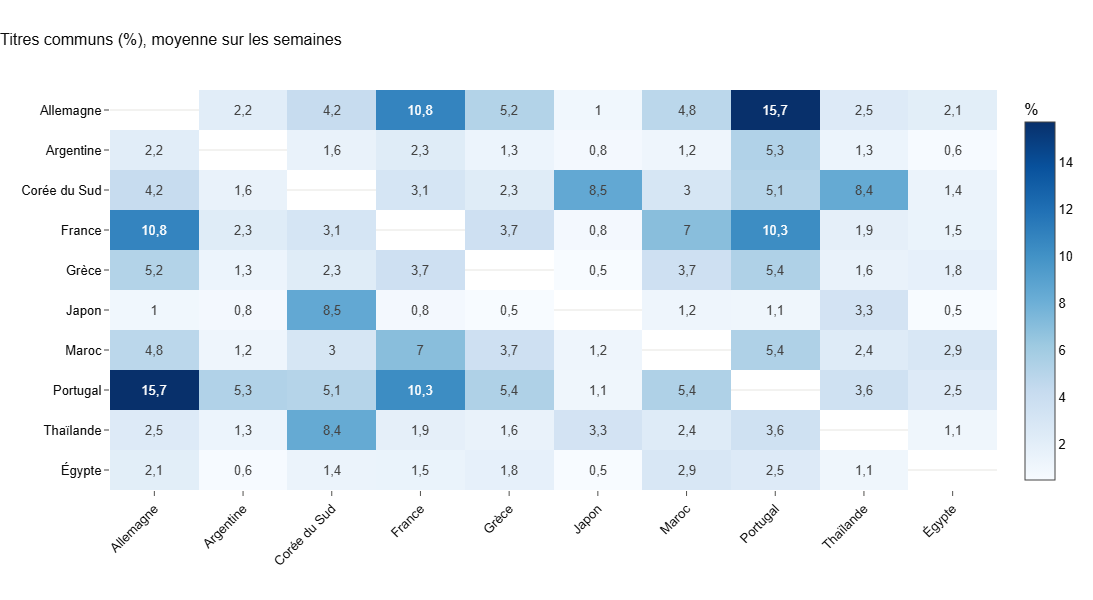

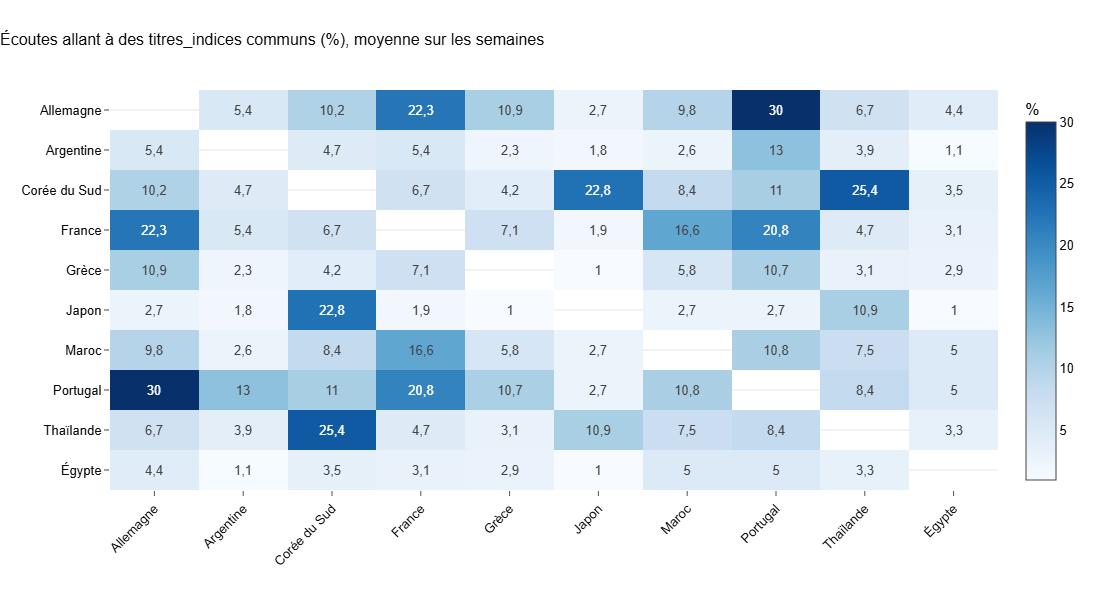

In [44]:
# ✎ Modifié par Claude : variable `titres` renommée `titres_indices` (conflit avec d'autres cellules)
def matrice(indice):
    m = sim.groupby(["pays_a", "pays_b"])[indice].mean().unstack()
    m = m.reindex(index=pays_liste, columns=pays_liste)
    m = m.combine_first(m.T)                 # on recopie la moitié symétrique
    for p in pays_liste:
        m.loc[p, p] = np.nan                 # diagonale vide (un pays face à lui-même)
    return (m * 100).round(1)                # en pourcentage

titres_indices = {"jaccard": "Titres communs (%), moyenne sur les semaines",
          "part_ecoutes": "Écoutes allant à des titres_indices communs (%), moyenne sur les semaines"}

for indice, titre in titres_indices.items():
    fig = px.imshow(matrice(indice), text_auto=True, color_continuous_scale="Blues",
                    labels=dict(color="%"), aspect="auto")
    fig.update_layout(title=titre, xaxis_title="", yaxis_title="",
                      width=750, height=600)
    fig.update_xaxes(side="bottom", tickangle=-45)
    fig.show()

Les classements des dix pays se ressemblent peu : même la paire la plus proche, Allemagne et Portugal, ne partage que 15,7 % de ses titres, et la plupart des paires moins de 5 %. Les titres communs pèsent toutefois environ deux fois plus dans les écoutes que dans le nombre de titres : ce qui circule entre pays, ce sont surtout les grands succès internationaux.

Deux blocs se dégagent : un bloc asiatique autour de la Corée du Sud, liée à la Thaïlande et au Japon par la K-pop, et un bloc européen réunissant l'Allemagne, le Portugal et la France. Le Maroc est nettement plus proche de la France que de l'Égypte, avec laquelle il partage pourtant l'arabe : ce n'est donc pas la langue officielle commune qui rapproche les classements, mais la langue réellement partagée dans la musique, ici le français. Enfin, l'Égypte et le Japon, dont les classements se renouvellent le moins, sont aussi les plus éloignés des autres pays.

**Conclusion.** Les classements des dix pays restent largement distincts : les titres communs sont peu nombreux et se limitent pour l'essentiel aux grands succès internationaux, qui concentrent toutefois une part importante des écoutes partagées. L'écoute sur Spotify ne conduit donc pas à une uniformisation des classements ; chaque pays conserve en grande partie son propre répertoire, ce qui est cohérent avec la préférence pour les artistes nationaux et la langue locale mise en évidence par les régressions.

**L'hypothèse H3** n'est que partiellement confirmée. Le partage d'une langue officielle ne suffit pas à rapprocher deux classements, comme le montre la faible proximité entre l'Égypte et le Maroc. Ce sont plutôt une langue réellement partagée dans la musique, comme le français entre la France et le Maroc, et une circulation régionale des répertoires, comme la K-pop en Asie, qui rapprochent les pays. Ces proximités suggèrent l'existence de groupes de pays aux profils d'écoute voisins, que la classification de la partie 5.2 permet d'identifier plus précisément.

## 5.2. GROUPES DE PAYS

La partie 5.1 a fait apparaître des proximités entre certains pays. Cette partie les systématise au moyen d'une classification ascendante hiérarchique. La distance entre deux pays est définie comme le complément de la part moyenne des écoutes allant à des titres communs : plus deux classements partagent d'écoutes, plus les pays sont proches. Les pays sont ensuite regroupés pas à pas, des plus proches aux plus éloignés, ce qui permet de faire apparaître des groupes de pays aux profils d'écoute voisins.

Étape 1 : Allemagne  +  Portugal  ->  distance 0.700
Étape 2 : Corée du Sud  +  Thaïlande  ->  distance 0.746
Étape 3 : France  +  Allemagne, Portugal  ->  distance 0.784
Étape 4 : Japon  +  Corée du Sud, Thaïlande  ->  distance 0.832
Étape 5 : Maroc  +  France, Allemagne, Portugal  ->  distance 0.876
Étape 6 : Grèce  +  Maroc, France, Allemagne, Portugal  ->  distance 0.914
Étape 7 : Argentine  +  Grèce, Maroc, France, Allemagne, Portugal  ->  distance 0.943
Étape 8 : Japon, Corée du Sud, Thaïlande  +  Argentine, Grèce, Maroc, France, Allemagne, Portugal  ->  distance 0.949
Étape 9 : Égypte  +  Japon, Corée du Sud, Thaïlande, Argentine, Grèce, Maroc, France, Allemagne, Portugal  ->  distance 0.967


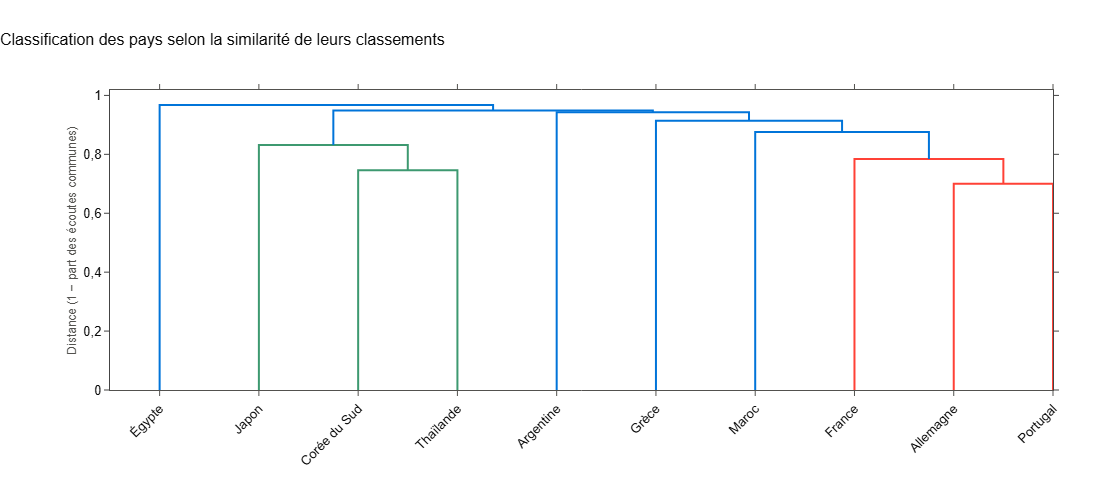

In [45]:
# 1. Matrice de distance : 1 - part moyenne des écoutes allant à des titres communs
sim_ecoutes = matrice("part_ecoutes") / 100
distance = 1-sim_ecoutes.fillna(1)
dist = squareform(distance.to_numpy(), checks=False)
noms_pays = distance.index.tolist()

Z = linkage(dist, method="average")

# On suit les groupes formés à chaque étape pour afficher des noms_pays lisibles
groupes = {i: [nom] for i, nom in enumerate(noms_pays)}
for etape, (g1, g2, hauteur, taille) in enumerate(Z, start=1):
    g1, g2 = int(g1), int(g2)
    nouveau = groupes[g1] + groupes[g2]
    groupes[len(noms_pays) + etape - 1] = nouveau
    print(f"Étape {etape} : {', '.join(groupes[g1])}  +  {', '.join(groupes[g2])}"
          f"  ->  distance {hauteur:.3f}")

# 2. Dendrogramme Plotly, avec nos distances et la méthode de la moyenne
fig = ff.create_dendrogram(
    distance.to_numpy(),
    labels=noms_pays,
    distfun=lambda x: dist,                                # on fournit nos propres distances
    linkagefun=lambda d: linkage(d, method="average"),     # même méthode qu'avant
    color_threshold=0.85,                                  # hauteur de coupe pour colorer les groupes
)
fig.update_layout(title="Classification des pays selon la similarité de leurs classements",
                  yaxis_title="Distance (1 − part des écoutes communes)",
                  width=850, height=500)
fig.update_xaxes(tickangle=-45)
fig.show()

Le dendrogramme fait apparaître deux groupes principaux :

- **Groupe européen :** l'Allemagne et le Portugal sont les pays les plus proches (0,700), suivis de la France (0,784). Le Maroc rejoint ensuite ce groupe (0,876), notamment grâce aux liens musicaux avec la France.
- **Groupe asiatique :** la Corée du Sud et la Thaïlande sont proches (0,746), puis le Japon les rejoint (0,832), probablement grâce à la diffusion de la K-pop.

La Grèce et l'Argentine restent plus éloignées du groupe européen. L'Égypte est le pays le plus isolé : elle rejoint les autres en dernier (0,967). Leurs classements sont donc moins proches de ceux des autres pays.



Ces résultats montrent que les ressemblances entre classements suivent davantage des liens musicaux régionaux que le simple partage d'une langue. Par exemple, le Maroc se rapproche du groupe européen bien avant l'Égypte, alors que les deux pays partagent l'arabe.

Cependant, les distances restent élevées (au moins 0,70). Même les pays d'un même groupe partagent donc une part limitée de leurs écoutes. Les préférences musicales restent largement nationales.

**Conclusion.** Les classements des dix pays restent largement nationaux, et leurs ressemblances suivent des logiques régionales, avec un bloc européen et un bloc asiatique, plutôt qu'une langue officielle commune. L'écoute sur Spotify ne conduit donc pas à une uniformisation des goûts, mais à la coexistence de répertoires nationaux et de quelques circulations régionales.

# 6. DISCUSSION : QUOTAS ET CULTURE

## 6.1 Ce que montrent les chiffres

Dans les dix pays, les gens écoutent beaucoup leur musique nationale, avec ou sans quota. Au Japon, 87 % des écoutes du Top 200 vont à des artistes japonais. Au Portugal, c'est seulement 25 % (partie 4.2). Les pays sans quota ne sont pas les moins tournés vers leur musique : le Japon fait 87 %, l'Égypte 83 % et la Corée du Sud 78 %.

Dans la partie 4.1, nous avons comparé les pays avec quota (Argentine, France, Grèce, Portugal) aux six autres. Les pays avec quota ont moins de musique nationale : 53,1 % contre 63,2 %. Si les quotas faisaient monter la musique nationale, on verrait le contraire. Si on met la Grèce et le Maroc de côté, l'écart est encore plus grand (48,9 % contre 65,9 %). Les pays avec quota ont plus de chansons dans leur langue (71,6 % contre 59,3 %).

On ne voit pas de séparation claire entre les deux groupes. Parmi les pays avec quota, la musique nationale va de 25 % au Portugal à 70 % en France. Dans le calcul de la partie 4.3, on compare le même titre, la même semaine, dans plusieurs pays. Dans les pays avec quota, la langue compte (+84 % d'écoutes), mais pas la nationalité. Dans les pays sans quota, c'est la nationalité qui compte (+70 %).

Les courbes de la partie 3.1 se ressemblent pour la France, le Portugal, la Grèce et l'Argentine : le total du Top 200 monte, puis baisse à partir de 2024 ou 2025. L'Allemagne, sans quota, baisse aussi (−24 %). L'Égypte, la Corée du Sud, le Maroc et la Thaïlande, eux, montent. Dans la partie 5, les pays les plus proches sont l'Allemagne et le Portugal, puis la Corée du Sud et la Thaïlande.

Les pays les plus tournés vers leur musique sont le Japon, l'Égypte et la Corée du Sud. Les plus ouverts sont le Portugal (25 %) et l'Allemagne (46 %), qui écoutent aussi beaucoup d'anglais (42 % et 55 % des écoutes, partie 4.1).

## 6.2 D'autres explications possibles

- **La langue.** Le Japon et la Thaïlande ont une langue que personne d'autre ne parle dans notre échantillon, et l'Égypte ne la partage qu'avec le Maroc. Leurs classements changent peu (partie 3.2), et le Japon et l'Égypte écoutent très peu d'anglais (9,7 % et 8,1 %).

- **La taille du marché.** Le Top 200 allemand fait environ 128 à 169 millions d'écoutes par semaine (début et fin de période). Celui de l'Égypte en fait 7 à 43 millions et celui du Maroc 6 à 14 millions. Dans un petit marché, un seul artiste peut tout changer : au Maroc, une semaine, ElGrandeToto fait 53 % du Top 200.

- **L'anglais.** L'Allemagne (55,4 %) et le Portugal (41,5 %) écoutent beaucoup d'anglais, et ce sont les pays avec le moins de musique nationale. Ce n'est pas vrai partout : la Corée du Sud a 71,8 % d'anglais (partie 4.1) et 78 % de musique nationale (partie 4.2). Ce chiffre d'anglais doit encore être contrôlé, comme le dit la partie 4.1.

- **Spotify.** Notre base ne contient que le Top 200 de Spotify, pas toute l'écoute d'un pays. Nous n'avons pas pu tester cette piste.

## 6.3 Pourquoi on ne conclut pas sur l'effet des quotas

1. Les quotas concernent la radio, et nous n'avons que des écoutes sur Spotify. Nous ne voyons pas la radio.
2. Les quotas existaient déjà avant le début de nos données (France 1986, Portugal 2001, Argentine 2009). Nous ne pouvons donc pas comparer « avant » et « après ». Seule la mesure grecque (2024) commence pendant notre période, et elle concerne les lieux publics, pas la radio.
3. Les pays avec et sans quota sont très différents : la langue, la taille du marché. Nous n'avons que dix pays.
4. Le résultat change selon la façon de classer la Grèce et le Maroc (53,1 % contre 63,2 % d'un côté, 48,9 % contre 65,9 % de l'autre).
5. Un pays met peut-être un quota parce que sa musique nationale est faible, comme le Portugal. Le quota serait alors la conséquence, pas la cause.
6. Les quotas ne sont pas tous les mêmes : 30 % en Argentine, 40 % en France et en Grèce, 30 % aujourd'hui au Portugal. Quand on compare seulement deux pays dans le calcul de la partie 4.3, il y a peu de lignes (5 982 et 8 388), donc le résultat est peu précis.

## 6.4 Ce que l'étude apporte malgré tout

- Nous avons comparé dix pays sur la même période : 210 semaines et 419 891 lignes.
- Les gens écoutent plus la musique de leur pays partout. Un même titre est écouté environ 41 % de plus là où un artiste est du pays, et 44 % de plus là où il est chanté dans la langue du pays.
- Les quotas ne sont pas nécessaires pour cela : le Japon, l'Égypte et la Corée du Sud n'ont pas de quota dans notre fichier et sont les plus tournés vers leur musique.
- Les classements restent différents d'un pays à l'autre : deux pays n'ont en moyenne que 3,5 % de titres en commun.
- Pour aller plus loin : avoir des données de radio, et regarder avant et après la mesure de la Grèce (2024).

# CONCLUSION